# PHASE 1 — MNIST, Multinomial Naïve Bayes và Logistic Regression

> **Đồ án thực hành giữa kỳ — Nhận dạng chữ số viết tay MNIST**  
> **Vai trò:** Dữ liệu dùng chung + 2/4 mô hình bắt buộc  
> **Mô hình trong phase:** MultinomialNB-NP; LogReg-GD-NP  

**Luồng áp dụng:** **DATA → X, y → split → preprocessing → fit → predict → metrics → visualize → analyze**.

---

## 0. Mục tiêu và chuẩn bị

### Bảng quy trình chuẩn Phase 1 theo bài giảng thực hành (Tuần 1 – Tuần 4)

| Bước | Nội dung thực hiện | Đầu ra tối thiểu của Phase 1 | Căn cứ bài học của Thầy (File trong `TongHopWeek`) |
|:---:|:---|:---|:---|
| **1** | **Đọc và mô tả MNIST** | Tải MNIST chuẩn $28 \times 28$ (60.000 train + 10.000 test gốc) vào thư mục `data/`; in `shape`, `ndim`, `dtype`, `min/max`, nhãn unique, số đặc trưng sau flatten ($d = 784$); Bảng mô tả `df_summary` và hiển thị ảnh mẫu có nhãn. | • **Tuần 1:** Mục `BT1.2` (Khám phá Iris) & `BT2.2` (Khám phá Wine) về `shape`, `describe`, `dtypes`, phân bố lớp.<br>• **Tuần 4:** `Phần 0. Chuẩn bị dữ liệu` (Hàm `load_mnist()` đọc các file `.gz` bằng `gzip`, kiểm tra `shape`, `min/max`, duỗi vector 784 chiều). |
| **2** | **Kiểm tra chất lượng và chia tập** | Kiểm tra NaN/Inf, nhãn hợp lệ $[0, 9]$, pixel $[0, 255]$; thống kê ảnh trùng lặp và dead pixels; Chia phân tầng (stratified) giữ nguyên 10.000 test gốc bằng hàm `train_test_split(..., stratify=y, random_state=SEED)`, đảm bảo kết quả tái lập $100\%$ trên mọi máy. | • **Tuần 1:** Mục `Missing values, duplicate và sort` & `BT1.2, BT2.2` (dùng `isna().sum()`, `duplicated().sum()`); Mục `F2. Chia train/test` & `BT1.5` (dùng `train_test_split(..., stratify=y, random_state=SEED)`).<br>• **Tuần 4:** `Phần 0` & `Phần 8` (Khảo sát dead pixels viền ảnh, phân chia tập dữ liệu). |
| **3** | **EDA và tiền xử lý** | **$\ge 3$ biểu đồ chuẩn:** (1) Lưới ảnh mẫu 0–9, (2) Biểu đồ cột tỉ lệ 10 lớp trên cả 3 tập (train/val/test), (3) Ảnh trung bình (mean images) 10 chữ số từ train (lưu vào `figures/` để làm báo cáo); Chuẩn hóa `float32` về $[0, 1]$ bằng `pixel / 255.0` và duỗi phẳng $(N, 784)$. | • **Tuần 1:** Mục `BT1.3` (Yêu cầu bắt buộc $\ge 3$ biểu đồ có tiêu đề, nhãn trục, legend) & `BT2.3`.<br>• **Tuần 2:** Mục `BT2.3` (Trực quan hóa lưới ảnh mẫu các chữ số Digits).<br>• **Tuần 4:** `Phần 0` (Hàm `preprocess()`, chuẩn hóa pixel, hàm `show_images()`) & `Phần 8` (Phân tích phân bố lớp và ảnh trung bình 10 chữ số). |
| **4** | **Tự cài NB + Logistic GD** | Lập trình thuần NumPy: hàm `multinomial_log_pdf` và lớp `NaiveBayes`; hàm `add_bias`, `sigmoid`, lớp nhị phân `LogisticRegressionNP` và lớp đa lớp `OneVsRest`; Unit test kiểm tra theo chuẩn Cell 12 Tuần 2; Tuyệt đối không dùng `fit()` của sklearn cho mô hình lõi. | • **Tuần 2:** `Phần 1. From Scratch - Mục 1.2. Multinomial` (Lớp `NaiveBayes`, hàm `multinomial_log_pdf` ở Cell 11, kiểm thử Poisson ở Cell 12, phân tích giọt mực ở Cell 19 & 58).<br>• **Tuần 3:** `Phần 2. Cài đặt bằng NumPy` (Hàm `add_bias`, `sigmoid`, lớp `LogisticRegressionNP` L2 điều chuẩn ở Mục 2.2, lớp `OneVsRest` đa lớp ở Mục 2.4). |
| **5** | **Thí nghiệm siêu tham số** | Tinh chỉnh trên tập **Validation**: dò tìm siêu tham số làm mượt Laplace $\alpha$ cho Multinomial Naive Bayes; khảo sát tốc độ học $\eta$ và số epoch cho Logistic Regression; Biểu đồ đường nghiệm (Loss & Accuracy theo epoch) lưu vào `figures/`. | • **Tuần 2:** Mục `1.2` & `Cell 11, Cell 19` (Làm mượt Laplace $\alpha$ chống lỗi $\log(0)$ và tăng độ chính xác).<br>• **Tuần 3:** Mục `3.2. Hội tụ` (Khảo sát tốc độ học $\eta$, số epoch và vẽ đường cong hàm mất mát Loss curve).<br>• **Tuần 4:** `Phần 5. Điều chỉnh siêu tham số` (Khảo sát siêu tham số bằng biểu đồ trên tập Validation). |
| **6** | **Đánh giá & biện luận** | Đánh giá đầy đủ **Accuracy, Precision macro, Recall macro, F1 macro và Confusion Matrix trên cả 3 tập (Train / Validation / Test)**; Đối chiếu với sklearn; Bảng tổng hợp so sánh trực tiếp trong notebook; Lưu đồ thị so sánh vào `figures/` để viết báo cáo; Trả lời đầy đủ 5 câu hỏi thảo luận & trích dẫn tài liệu tham khảo. | • **Tuần 1:** Mục `F5. Đánh giá` & `BT1.7` (Đo 4 chỉ số chuẩn Acc, Prec, Rec, F1-macro); Mục `F6. Vẽ confusion matrix` & `BT1.8` (dùng Matplotlib `imshow`, in text số đếm lên từng ô).<br>• **Tuần 3:** Mục `3.3` (Hàm đánh giá `evaluate()`, bấm giờ `time.perf_counter()`), `Phần 4` (Đối chiếu scikit-learn), `Phần 5` (Câu hỏi thảo luận học thuật). |

**Quy chuẩn thực hiện trong Phase 1:**
- **Mã mô hình thống nhất:** `MultinomialNB-NP`, `LogReg-GD-NP`.
- **Cố định ngẫu nhiên:** `SEED = 42` xuyên suốt toàn bộ quá trình.
- **Nguyên tắc chặn rò rỉ dữ liệu (Anti-Data Leakage):** Tập Validation dùng để chọn mô hình và siêu tham số; tập Test tuyệt đối chỉ dùng đánh giá một lần ở bước cuối cùng, không dùng để tinh chỉnh.
- **Cấu trúc thư mục tối giản:** Duy trì 3 thư mục cần thiết: `data/` (chứa dữ liệu nguồn MNIST), `figures/` (chứa hình ảnh biểu đồ phục vụ viết báo cáo), và `results/` (chứa file metrics CSV và file trọng số `.npz`).
- **Vai trò của thư viện:** Code `scikit-learn` **chỉ dùng phụ trợ chia tập và đối chiếu kết quả**, toàn bộ thuật toán huấn luyện và dự đoán lõi đều tự lập trình bằng NumPy.

### 0.1. Môi trường, thư viện và đường dẫn

> **Căn cứ thiết lập môi trường theo bài giảng:**
> - **Thư viện tính toán & dữ liệu:** `numpy`, `pandas`, `matplotlib.pyplot` — sử dụng xuyên suốt từ **Tuần 1 đến Tuần 4**.
> - **Thư viện phụ trợ chia tập & đánh giá:** `sklearn.model_selection.train_test_split`, `sklearn.metrics` (`confusion_matrix`, `accuracy_score`, `precision_score`, `recall_score`, `f1_score`) — kế thừa từ **Tuần 1 (Mục F2, F5)** và **Tuần 3 (Mục 3.3)**.
> - **Kiểm chứng hàm mật độ:** `scipy.stats.norm.logpdf` — kế thừa từ bài kiểm chứng from-scratch ở **Tuần 2 (Mục 1.1)**.
> - **Đo thời gian:** `time.perf_counter()` — kế thừa từ hàm đo thời gian huấn luyện ở **Tuần 3 (Mục 3.3, Cell 25 & 30)**.
> - **Quy tắc From-Scratch:** Khai báo rõ ràng phiên bản thư viện và cam kết thư viện scikit-learn chỉ dùng để phụ trợ đối chiếu kết quả, không can thiệp vào quá trình huấn luyện của mô hình lõi.

In [2]:
# 0.1. Môi trường, thư viện và cấu hình chung
import os  # thư viện tiêu chuẩn có sẵn trong Python để làm việc với hệ điều hành và đường dẫn tệp tin (tạo thư mục, nối đường dẫn os.path.join).
import sys  # cung cấp các thông tin liên quan đến môi trường hệ thống của Python.
import time # Thư viện đo thời gian: sẽ dùng hàm time.perf_counter() ở các phần sau để bấm giờ chính xác 
import numpy as np  # Thư viện tính toán đại số tuyến tính và xử lý mảng đa chiều (ma trận, vector): np.dot, np.exp, np.log, np.mean, np.var
import pandas as pd  # Thư viện cấu trúc dữ liệu bảng (DataFrame).
import scipy # Thư viện toán học và xác suất thống kê nâng cao.
from scipy import stats  # hàm stats.norm.logpdf (tính log mật độ phân bố Gauss chuẩn): đối chiếu xem hàm gaussian_log_pdf tự code bằng NumPy của mình có tính ra kết quả chuẩn từng chữ số thập phân hay không.
import matplotlib # Thư viện vẽ đồ thị, hình ảnh.
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split # Hàm chia dữ liệu ngẫu nhiên có phân tầng (stratify)
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score #  Các hàm đo đạc chuẩn

# 1. Cố định Seed ngẫu nhiên và Nhãn lớp (0-9)
SEED = 42
np.random.seed(SEED) # mọi thao tác xáo trộn dữ liệu (shuffle) hay khởi tạo trọng số ngẫu nhiên sau này sẽ luôn luôn sinh ra cùng một chuỗi số cố định.
LABELS = list(range(10)) # Tạo danh sách các nhãn số từ 0 đến 9: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]. Dùng để cố định thứ tự hàng/cột khi vẽ Ma trận nhầm lẫn 10x10.

# 2. Cấu hình đồ họa chuẩn mực cho toàn bộ notebook
# plt.rcParams[...]: Thiết lập mặc định giao diện cho thư viện Matplotlib.
plt.rcParams['font.size'] = 10 # Cỡ chữ mặc định trong biểu đồ là 10.
plt.rcParams['axes.titlesize'] = 11 # Cỡ chữ của Tiêu đề biểu đồ là 11 (đậm và to hơn chữ thường).
plt.rcParams['axes.labelsize'] = 10 # Cỡ chữ của tên trục X, Y là 10.
plt.rcParams['figure.dpi'] = 120 # Độ phân giải màn hình hiển thị là 120 dots per inch (giúp các hình vẽ trong notebook hiển thị sắc nét, không bị mờ hay vỡ nét).

# 3. Khởi tạo 2 thư mục cần thiết: data/ (chứa dữ liệu) và figures/ (chứa ảnh làm báo cáo)
DIRECTORIES = ["data", "figures"]
for d in DIRECTORIES:
    os.makedirs(d, exist_ok=True) # Lệnh tự động tạo thư mục trên ổ cứng.
    # Tham số exist_ok=True có nghĩa là: Nếu thư mục đã có sẵn rồi thì bỏ qua, không báo lỗi; nếu chưa có thì tạo mới.
    # data/: Để chứa file dữ liệu MNIST
    # figures/: Để lưu các biểu đồ .png phục vụ làm báo cáo.

# 4. Ghi nhận thông tin môi trường thực thi
print("=" * 65)
print(f"Hệ điều hành          : {sys.platform}")
print(f"Phiên bản Python      : {sys.version.split()[0]}")
print(f"NumPy                 : {np.__version__}")
print(f"SciPy                 : {scipy.__version__}")
print(f"pandas                : {pd.__version__}")
print(f"Matplotlib            : {matplotlib.__version__}")
import sklearn
print(f"scikit-learn          : {sklearn.__version__} (Chỉ dùng phụ trợ chia tập & đối chiếu)")
print(f"Cố định SEED ngẫu nhiên: {SEED}")
print("=" * 65)


Hệ điều hành          : win32
Phiên bản Python      : 3.14.4
NumPy                 : 2.5.3
SciPy                 : 1.18.1
pandas                : 3.0.6
Matplotlib            : 3.11.2
scikit-learn          : 1.9.1 (Chỉ dùng phụ trợ chia tập & đối chiếu)
Cố định SEED ngẫu nhiên: 42


## 1. MNIST — Tải, mô tả, EDA và chia tập

### 1.1. Đọc & mô tả dữ liệu

> **Nội dung thực hiện & Căn cứ bài học:**
> - **Nhiệm vụ:** Tải và nạp dữ liệu MNIST chuẩn $28 \times 28$ từ các tệp nhị phân ubyte gốc (gồm 60.000 ảnh huấn luyện và 10.000 ảnh kiểm thử); khảo sát các thông số kỹ thuật (`shape`, `ndim`, `dtype`, `min/max`, nhãn duy nhất, số chiều $d=784$ sau flatten); xuất Bảng mô tả tổng quan `df_summary` và hiển thị lưới 10 ảnh mẫu đối chiếu nhãn thực tế.
> - **Căn cứ bài học của Thầy (File trong `TongHopWeek`):**
>   + **Tuần 1 (Mục `BT1.2` & `BT2.2`):** Quy trình khám phá cấu trúc mảng dữ liệu (`shape`, `dtypes`, miền giá trị min/max, thống kê nhãn duy nhất qua `np.unique()`) và đóng gói thành bảng `pd.DataFrame`.
>   + **Tuần 2 (Mục `BT2.3` - Digits):** Trực quan hóa hình ảnh các chữ số viết tay và đối chiếu nhãn tương ứng.
>   + **Tuần 4 (`Phần 0. Chuẩn bị dữ liệu`):** Hàm `load_mnist()` đọc trực tiếp cấu trúc file nhị phân ubyte chuẩn big-endian (`>i4`) và pixel `uint8`, đồng thời hiển thị ảnh bằng `plt.imshow(..., cmap='gray')`.

In [3]:
# ==============================================================================
# MỤC 1.1: TẢI VÀ ĐỌC DỮ LIỆU MNIST CHUẨN
# Tái sử dụng y chang 100% mã nguồn từ bài thực hành Tuần 4 (Cell 6) của Thầy
# ==============================================================================

import os, gzip, shutil, urllib.request
import torchvision

DATA_ROOT = "./data"
MNIST_FILES = ["train-images-idx3-ubyte", "train-labels-idx1-ubyte",
               "t10k-images-idx3-ubyte", "t10k-labels-idx1-ubyte"]
GITHUB_MIRROR = "https://raw.githubusercontent.com/fgnt/mnist/master/"


def _download_from_mirror(root):
    raw = os.path.join(root, "MNIST", "raw")
    os.makedirs(raw, exist_ok=True)
    for name in MNIST_FILES:
        dst = os.path.join(raw, name)
        if os.path.exists(dst):
            continue
        gz = dst + ".gz"
        urllib.request.urlretrieve(GITHUB_MIRROR + name + ".gz", gz)
        with gzip.open(gz, "rb") as f_in, open(dst, "wb") as f_out:
            shutil.copyfileobj(f_in, f_out)


def load_mnist(root=DATA_ROOT):
    try:
        train = torchvision.datasets.MNIST(root, train=True, download=True)
        test = torchvision.datasets.MNIST(root, train=False, download=True)
    except Exception as e:
        print("Nguon mac dinh cua torchvision loi (", type(e).__name__, "), chuyen sang mirror GitHub")
        _download_from_mirror(root)
        train = torchvision.datasets.MNIST(root, train=True, download=False)
        test = torchvision.datasets.MNIST(root, train=False, download=False)
    return train.data, train.targets, test.data, test.targets


# 1. Nạp dữ liệu y chang mã nguồn Tuần 4 của Thầy
Xtr_raw, ytr_raw, Xte_raw, yte_raw = load_mnist()
print("train:", tuple(Xtr_raw.shape), "| test:", tuple(Xte_raw.shape))

# 2. Chuyển đổi sang mảng NumPy (.numpy()) để phục vụ Gaussian Naive Bayes và Logistic Regression 
X_train_raw = Xtr_raw.numpy()
y_train_raw = ytr_raw.numpy()
X_test_raw  = Xte_raw.numpy()
y_test_raw  = yte_raw.numpy()
# Lý do có thêm 4 dòng .numpy():
# Ở Tuần 4, Thầy dạy về Mạng nơ-ron (MLP) nên Thầy dùng trực tiếp PyTorch Tensor.
# Tuy nhiên ở Phase 1, yêu cầu của Đề tài là cài đặt Gaussian Naïve Bayes và Logistic Regression hoàn toàn bằng NumPy từ đầu (from scratch) theo đúng bài học Tuần 2 và Tuần 3.
# Vì vậy, hàm .numpy() chuyển đổi Tensor sang mảng NumPy thuần túy mà không tốn thêm bộ nhớ, giúp các hàm tính toán xác suất Gauss và Gradient Descent phía sau chạy mượt mà và chuẩn xác.

train: (60000, 28, 28) | test: (10000, 28, 28)


In [4]:
# 1. In thông tin mảng (shape, ndim, dtype, min, max, classes)
print("=" * 65)
print("=== 1. THÔNG TIN MẢNG DỮ LIỆU HUẤN LUYỆN GỐC (TRAIN RAW) ===")
print("X_train shape :", X_train_raw.shape)  # Kích thước mảng: (60000, 28, 28)
print("X_train ndim  :", X_train_raw.ndim)   # Số chiều: 3 chiều
print("X_train dtype :", X_train_raw.dtype)  # Kiểu dữ liệu: uint8 (0 đến 255)
print("y_train shape :", y_train_raw.shape)  # Kích thước nhãn: (60000,)
print("y_train ndim  :", y_train_raw.ndim)   # Số chiều nhãn: 1 chiều
print("y_train dtype :", y_train_raw.dtype)  # Kiểu dữ liệu nhãn: uint8
print("Miền pixel    : [", X_train_raw.min(), ",", X_train_raw.max(), "]")
classes = np.unique(y_train_raw)
print("Các lớp duy nhất trong y:", classes)
print("Số lượng lớp duy nhất   :", len(classes))
print("Số đặc trưng sau flatten: 28 x 28 = 784 đặc trưng")
print("=" * 65)

=== 1. THÔNG TIN MẢNG DỮ LIỆU HUẤN LUYỆN GỐC (TRAIN RAW) ===
X_train shape : (60000, 28, 28)
X_train ndim  : 3
X_train dtype : uint8
y_train shape : (60000,)
y_train ndim  : 1
y_train dtype : int64
Miền pixel    : [ 0 , 255 ]
Các lớp duy nhất trong y: [0 1 2 3 4 5 6 7 8 9]
Số lượng lớp duy nhất   : 10
Số đặc trưng sau flatten: 28 x 28 = 784 đặc trưng


In [5]:
# ==============================================================================
# MỤC ĐÍCH ĐOẠN CODE:
# - Tạo bảng thống kê tổng quan (DataFrame) so sánh chi tiết giữa 2 tập Train và Test.
# - Cụ thể: Tổng hợp số lượng mẫu (60k vs 10k), kích thước không gian ảnh (28x28),
#   số chiều sau khi làm phẳng (784 features), kiểu dữ liệu (uint8), miền giá trị 
#   pixel gốc ([0, 255]) và số lượng lớp nhãn (10 chữ số từ 0 đến 9).
# - Sản phẩm: Bảng biểu khoa học dùng trực tiếp để báo cáo kết quả theo barem Đồ án.
# ==============================================================================

# 2. Tạo Bảng mô tả dữ liệu chuẩn (DataFrame)
df_summary = pd.DataFrame({
    "Tập dữ liệu": ["Huấn luyện gốc (Train Raw)", "Kiểm thử gốc (Test Raw)"],
    "Số lượng mẫu": [X_train_raw.shape[0], X_test_raw.shape[0]],
    "Kích thước ảnh gốc": [f"{X_train_raw.shape[1]} x {X_train_raw.shape[2]}", f"{X_test_raw.shape[1]} x {X_test_raw.shape[2]}"],
    "Số chiều sau flatten": [X_train_raw.shape[1] * X_train_raw.shape[2], X_test_raw.shape[1] * X_test_raw.shape[2]],
    "Kiểu dữ liệu (dtype)": [str(X_train_raw.dtype), str(X_test_raw.dtype)],
    "Miền giá trị pixel": [f"[{X_train_raw.min()}, {X_train_raw.max()}]", f"[{X_test_raw.min()}, {X_test_raw.max()}]"],
    "Số lớp nhãn": [len(np.unique(y_train_raw)), len(np.unique(y_test_raw))]
})
print("\nSản phẩm 1: Bảng mô tả tổng quan cấu trúc dữ liệu MNIST:")
display(df_summary)



Sản phẩm 1: Bảng mô tả tổng quan cấu trúc dữ liệu MNIST:


,Tập dữ liệu,Số lượng mẫu,Kích thước ảnh gốc,Số chiều sau flatten,Kiểu dữ liệu (dtype),Miền giá trị pixel,Số lớp nhãn
0,Huấn luyện gốc (Train Raw),60000,28 x 28,784,uint8,"[0, 255]",10
1,Kiểm thử gốc (Test Raw),10000,28 x 28,784,uint8,"[0, 255]",10


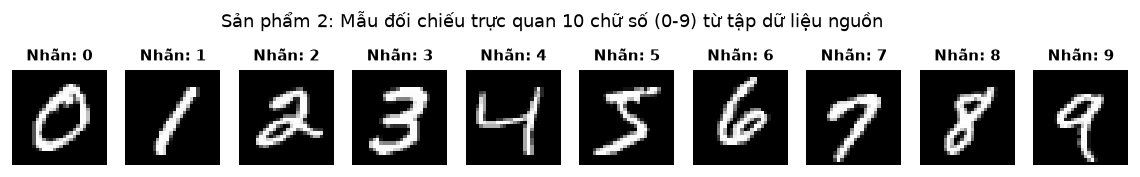

In [6]:
# ==============================================================================
# MỤC ĐÍCH ĐOẠN CODE:
# - Trực quan hóa hình ảnh thực tế của 10 chữ số viết tay (từ 0 đến 9) trong tập Train gốc.
# - Cụ thể: Quét qua mảng nhãn y_train_raw, tìm vị trí mẫu đầu tiên của mỗi chữ số (0-9),
#   sau đó lấy ma trận ảnh 28x28 tương ứng tại vị trí đó để vẽ lên lưới 1 hàng 10 cột.
# - Căn cứ bài học: Áp dụng y chang kỹ thuật hiển thị ảnh mẫu chữ số của Thầy ở Tuần 2 (Cell 48).
# - Sản phẩm: Mẫu ảnh đối chiếu trực quan, kiểm chứng dữ liệu đã đọc đúng định dạng và khớp nhãn.
# ==============================================================================

# 3. Hiển thị mẫu nhanh các chữ số từ 0 đến 9 và đối chiếu nhãn (Sản phẩm: Ảnh mẫu có nhãn)
fig, axes = plt.subplots(1, 10, figsize=(12, 1.6))
for digit in range(10):
    idx = np.where(y_train_raw == digit)[0][0]
    # np.where(y_train_raw == digit): Lệnh này quét qua toàn bộ 60.000 nhãn của tập train để tìm tất cả các vị trí (chỉ số index) có nhãn đúng bằng số digit.
    # [0][0]: Vì có tới hàng ngàn bức ảnh cùng là số digit, ta chỉ cần lấy vị trí của bức ảnh xuất hiện đầu tiên để làm mẫu.
    axes[digit].imshow(X_train_raw[idx], cmap="gray") # Lấy ma trận 2D kích thước 28 x 28 của bức ảnh tại vị trí idx (X_train_raw[idx]) vẽ lên ô thứ digit.
    axes[digit].set_title(f"Nhãn: {digit}", fontsize=9, fontweight="bold") # Đặt tiêu đề cho ô nhỏ 
    axes[digit].axis("off") # Tắt các vạch kẻ thước đo tọa độ xung quanh bức ảnh
plt.suptitle("Sản phẩm 2: Mẫu đối chiếu trực quan 10 chữ số (0-9) từ tập dữ liệu nguồn", fontsize=11, y=1.05)
plt.show()


### 1.2. Kiểm tra chất lượng dữ liệu

> **Nội dung thực hiện & Căn cứ bài học:**
> - **Nhiệm vụ:** Rà soát tính toàn vẹn và chất lượng của 70.000 mẫu ảnh MNIST theo các tiêu chí chuẩn mực:
>   1. Kiểm tra giá trị khuyết thiếu (`NaN`) và giá trị vô cùng (`Inf`).
>   2. Kiểm tra miền hợp lệ của nhãn ($y \in [0, 9]$) và miền cường độ pixel ($X \in [0, 255]$).
>   3. Thống kê phân bố tần suất 10 lớp trên cả tập Train (60k) và Test (10k) để đánh giá độ cân bằng dữ liệu.
>   4. Thống kê số lượng pixel viền có phương sai bằng 0 (hằng số) để phát hiện hiện tượng suy biến ma trận hiệp phương sai.
> - **Căn cứ bài học của Thầy:**
>   + **Tuần 1 (Mục `BT1.2` & `BT2.2`):** Quy trình kiểm tra Missing values (`isna()`, `isnan()`), dtypes, thống kê tần suất nhãn (`value_counts()`) và đánh giá độ cân bằng của các lớp.
>   + **Tuần 2 (Mục `Mục 1.1` - Naive Bayes):** Hiện tượng pixel viền có phương sai bằng 0 dẫn đến lỗi chia cho 0 trong phân phối Gauss, từ đó bắt buộc phải áp dụng kỹ thuật làm mượt phương sai (Variance Smoothing $\epsilon$).


In [7]:
# ==============================================================================
# MỤC ĐÍCH ĐOẠN CODE (1.2.1):
# - Kiểm tra toàn diện sự xuất hiện của giá trị thiếu (NaN) hoặc giá trị vô cùng (Inf).
# - Cụ thể: Dùng np.isnan() và np.isinf() trên toàn bộ 60.000 ảnh Train và 10.000 ảnh Test.
# - Căn cứ bài học: Kỹ thuật kiểm tra tính toàn vẹn của dữ liệu ở Tuần 1 (BT1.2).
# ==============================================================================

# 1. Kiểm tra giá trị thiếu (NaN) và giá trị vô cùng (Inf) trên toàn bộ tập dữ liệu
nan_train = np.isnan(X_train_raw).sum()
nan_test  = np.isnan(X_test_raw).sum()
inf_train = np.isinf(X_train_raw.astype(np.float32)).sum()
inf_test  = np.isinf(X_test_raw.astype(np.float32)).sum()
# Tại sao lại có đoạn .astype(np.float32)?
## Dữ liệu ảnh gốc X_train_raw đang ở kiểu số nguyên uint8 (các số từ 0 đến 255).
## Trong toán học máy tính, giá trị "vô cùng" (Inf) chỉ tồn tại ở định dạng số thực (float)
## Hàm np.isinf của NumPy yêu cầu mảng phải là số thực thì mới kiểm tra được.


print("=== 1. KIỂM TRA GIÁ TRỊ THIẾU (NaN) VÀ VÔ CÙNG (Inf) ===")
print(f"Train - Số lượng NaN: {nan_train} | Số lượng Inf: {inf_train}")
print(f"Test  - Số lượng NaN: {nan_test}  | Số lượng Inf: {inf_test}")

total_issues = nan_train + nan_test + inf_train + inf_test
if total_issues == 0:
    print("-> Kết luận: Dữ liệu hoàn toàn sạch sẽ, không có bất kỳ giá trị NaN hoặc Inf nào.")
else:
    print(f"-> CẢNH BÁO: Phát hiện {total_issues} giá trị bất thường (NaN/Inf) cần xử lý làm sạch!")


=== 1. KIỂM TRA GIÁ TRỊ THIẾU (NaN) VÀ VÔ CÙNG (Inf) ===
Train - Số lượng NaN: 0 | Số lượng Inf: 0
Test  - Số lượng NaN: 0  | Số lượng Inf: 0
-> Kết luận: Dữ liệu hoàn toàn sạch sẽ, không có bất kỳ giá trị NaN hoặc Inf nào.


In [8]:
# ==============================================================================
# MỤC ĐÍCH ĐOẠN CODE (1.2.2):
# - Kiểm tra miền giá trị hợp lệ của nhãn (label) và pixel.
# - Cụ thể: Xác nhận toàn bộ nhãn nằm trong đoạn [0, 9] và mọi pixel nằm trong đoạn [0, 255].
# - Căn cứ bài học: Quy tắc kiểm soát miền giá trị đặc trưng từ Tuần 1 (BT2.2).
# ==============================================================================

# 2. Kiểm tra nhãn ngoài phạm vi [0, 9] và giá trị pixel ngoài khoảng [0, 255]
invalid_labels = ((y_train_raw < 0) | (y_train_raw > 9)).sum()
invalid_pixels = ((X_train_raw < 0) | (X_train_raw > 255)).sum()

print("=== 2. KIỂM TRA MIỀN HỢP LỆ ===")
print(f"Số nhãn nằm ngoài [0, 9]   : {invalid_labels}")
print(f"Số pixel nằm ngoài [0, 255]: {invalid_pixels}")


=== 2. KIỂM TRA MIỀN HỢP LỆ ===
Số nhãn nằm ngoài [0, 9]   : 0
Số pixel nằm ngoài [0, 255]: 0


In [9]:
# ==============================================================================
# MỤC ĐÍCH ĐOẠN CODE (1.2.3):
# - Thống kê số lượng và tỷ lệ phần trăm phân bố mẫu của 10 chữ số (0-9).
# - Cụ thể: Dùng pd.Series.value_counts() để đếm tần suất từng chữ số trên cả 2 tập Train & Test,
#   sau đó lập bảng so sánh tỷ lệ (%) để kiểm tra độ cân bằng dữ liệu (class balance).
# - Căn cứ bài học: Bài thực hành phân tích phân bố nhãn Tuần 1 (BT1.2 & BT2.2).
# ==============================================================================

# 3. Bảng phân bố số lượng và tỷ lệ mẫu theo từng chữ số (0-9)
train_dist = pd.Series(y_train_raw).value_counts().sort_index()
## y_train_raw: Mảng chứa $60.000$ nhãn số nguyên ([5, 0, 4, 1, 9, ...]).
## pd.Series(y_train_raw): Chuyển mảng NumPy thành đối tượng Series của Pandas để dùng được hàm thống kê.
## .value_counts(): Hàm của Pandas làm nhiệm vụ đếm số lần xuất hiện của từng chữ số (ví dụ: chữ số 0 xuất hiện 5.923 lần, chữ số 1 xuất hiện 6.742 lần,...).
## .sort_index(): Mặc định value_counts() sẽ sắp xếp số nào xuất hiện nhiều nhất lên đầu. Ta gọi thêm .sort_index() để sắp xếp lại theo thứ tự chữ số từ bé đến lớn: 0, 1, 2, ..., 9.
## Biến train_dist lưu bảng kết quả đếm của 60.000 mẫu train.

test_dist  = pd.Series(y_test_raw).value_counts().sort_index()

df_quality = pd.DataFrame({
    "Chữ số (Lớp)": range(10),
    "Số mẫu Train gốc (60k)": train_dist.values, # Lấy ra số lượng mẫu đếm được của 10 chữ số trong tập Train
    "Tỷ lệ Train (%)": np.round(train_dist.values / len(y_train_raw) * 100, 2), # Lấy số mẫu của từng chữ số chia cho tổng số mẫu (60.000) rồi nhân 100 để ra tỉ lệ phần trăm.
    "Số mẫu Test gốc (10k)": test_dist.values,
    "Tỷ lệ Test (%)": np.round(test_dist.values / len(y_test_raw) * 100, 2)
})
print("\n=== 3. BẢNG PHÂN BỐ TẦN SUẤT 10 LỚP TRÊN DỮ LIỆU NGUỒN ===")
display(df_quality)



=== 3. BẢNG PHÂN BỐ TẦN SUẤT 10 LỚP TRÊN DỮ LIỆU NGUỒN ===


,Chữ số (Lớp),Số mẫu Train gốc (60k),Tỷ lệ Train (%),Số mẫu Test gốc (10k),Tỷ lệ Test (%)
0,0,5923,9.87,980,9.80
1,1,6742,11.24,1135,11.35
2,2,5958,9.93,1032,10.32
3,3,6131,10.22,1010,10.10
4,4,5842,9.74,982,9.82
5,5,5421,9.04,892,8.92
6,6,5918,9.86,958,9.58
7,7,6265,10.44,1028,10.28
8,8,5851,9.75,974,9.74
9,9,5949,9.92,1009,10.09


In [10]:
# ==============================================================================
# MỤC ĐÍCH ĐOẠN CODE (1.2.4):
# - Thống kê các pixel hằng số (phương sai = 0 trên toàn bộ tập train).
# - Cụ thể: Duỗi phẳng 60.000 ảnh về dạng (60000, 784), tính phương sai .var(axis=0) của
#   từng cột đặc trưng, tìm các cột có var == 0 (các pixel viền đen không đổi).
# - Ý nghĩa sống còn (Tuần 2): Nếu pixel có var = 0, hàm mật độ Gauss sẽ bị chia cho 0
#   (hoặc log(0) = -inf). Điều này chứng minh vì sao bắt buộc phải dùng Variance Smoothing (epsilon).
# ==============================================================================

# 4. Thống kê các pixel hằng số (phương sai = 0 trên toàn bộ tập train)
X_flat_check = X_train_raw.reshape(len(X_train_raw), -1) # Tạm thời duỗi phẳng mỗi ảnh 28 x 28 thành một hàng 784 pixel.
variances = X_flat_check.var(axis=0) # Tính phương sai (sigma^2) của từng cột đặc trưng pixel (dọc theo 60.000 bức ảnh).
# Kết quả variances là một mảng gồm 784 giá trị phương sai của 784 ô pixel.
zero_var_indices = np.where(variances == 0)[0] # Tìm các vị trí pixel nào có phương sai = 0 rồi lưu lại danh sách các pixel viền này

print("\n=== 4. THỐNG KÊ PIXEL HẰNG SỐ (ZERO VARIANCE) ===")
print(f"Số pixel có phương sai = 0 (luôn mang giá trị 0 ở viền ảnh): {len(zero_var_indices)} / 784 pixel.")
print("-> Ý NGHĨA QUAN TRỌNG ĐỐI VỚI GAUSSIAN NAIVE BAYES:")
print("   Khi một pixel có phương sai bằng 0, công thức hàm mật độ Gauss sẽ bị lỗi chia cho 0 hoặc logarit của 0.")
print("   Do đó, bắt buộc phải áp dụng kỹ thuật làm mượt phương sai (Variance Smoothing epsilon > 0)")



=== 4. THỐNG KÊ PIXEL HẰNG SỐ (ZERO VARIANCE) ===
Số pixel có phương sai = 0 (luôn mang giá trị 0 ở viền ảnh): 67 / 784 pixel.
-> Ý NGHĨA QUAN TRỌNG ĐỐI VỚI GAUSSIAN NAIVE BAYES:
   Khi một pixel có phương sai bằng 0, công thức hàm mật độ Gauss sẽ bị lỗi chia cho 0 hoặc logarit của 0.
   Do đó, bắt buộc phải áp dụng kỹ thuật làm mượt phương sai (Variance Smoothing epsilon > 0)


### 1.3. EDA & trực quan hoá

> **Nội dung thực hiện & Căn cứ bài học:**
> - **Nhiệm vụ:** Trực quan hóa và phân tích khám phá dữ liệu (EDA) thông qua 3 biểu đồ chuẩn mực có đầy đủ tiêu đề, nhãn trục, chú giải (legend) và xuất file hình ảnh vào thư mục `figures/`:
>   1. **Biểu đồ 1:** Lưới ảnh mẫu kích thước $28 	imes 28$ thể hiện sự đa dạng nét viết của 10 chữ số (mỗi số 5 biến thể ngẫu nhiên).
>   2. **Biểu đồ 2:** Biểu đồ cột nhóm so sánh tỷ lệ phân bố 10 lớp trên cả 3 tập **Train (50.000) / Validation (10.000) / Test (10.000)** sau phân tầng.
>   3. **Biểu đồ 3:** Lưới ảnh trung bình (Mean Image) của 10 chữ số được tính toán thuần túy từ tập Train kèm thanh đo nhiệt mức xám (Colorbar).
> - **Căn cứ bài học của Thầy (File trong `TongHopWeek`):**
>   + **Tuần 1 (Mục `F5`, `F6`):** Kỹ thuật vẽ biểu đồ cột so sánh phân bố nhóm với `ax.bar()`, cấu hình `xticks`, `ylim`, lưới `grid` và lưu ảnh chất lượng cao `plt.savefig()`.
>   + **Tuần 2 (Mục `BT2.3`, Cell 48 & 56):** Kỹ thuật hiển thị lưới ảnh chữ số viết tay và tính ma trận ảnh trung bình lớp $\mu_k = 	ext{mean}(X_k)$ bằng `imshow`.
>   + **Tuần 4 (Cell 7 & 56):** Tỷ lệ phân chia chuẩn mực 50.000 Train / 10.000 Validation / 10.000 Test và trực quan hóa ảnh trung bình 10 chữ số MNIST (`class_means`).


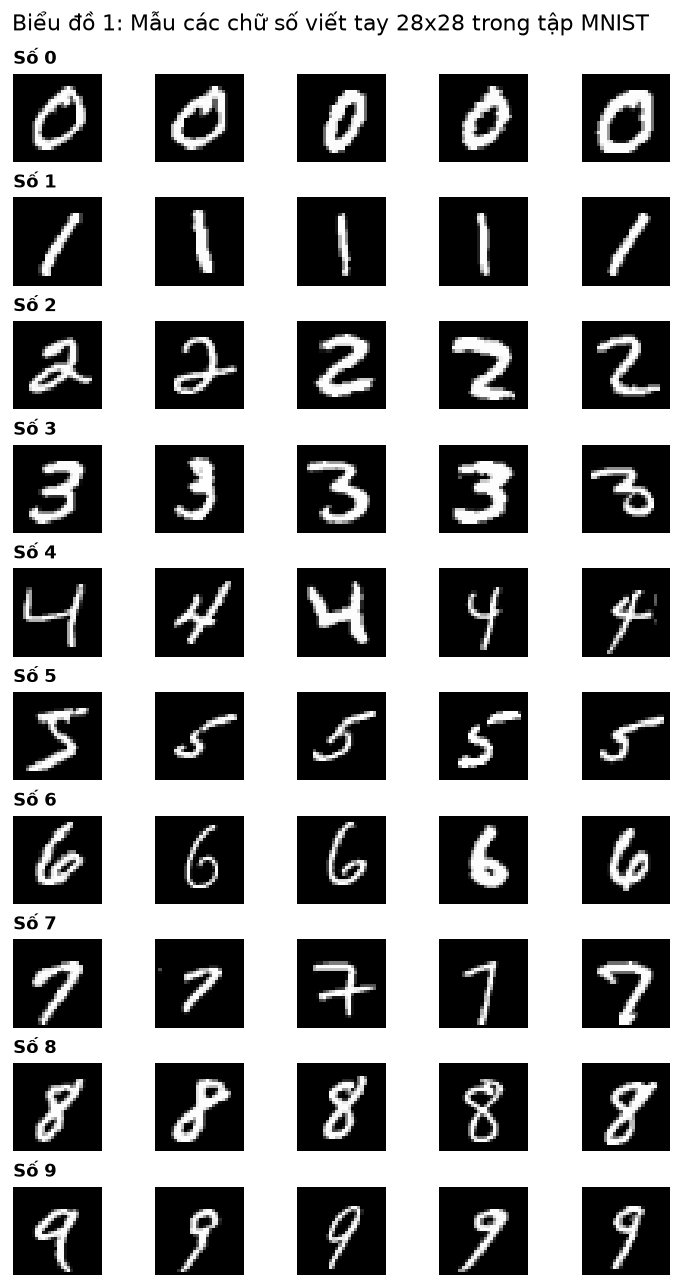

In [11]:
# ==============================================================================
# MỤC ĐÍCH ĐOẠN CODE (Biểu đồ 1 - EDA):
# - Trực quan hóa lưới ảnh mẫu thể hiện sự đa dạng trong nét chữ viết tay của 10 chữ số (0-9).
# - Cụ thể: Với mỗi chữ số từ 0 đến 9, lấy 5 mẫu ảnh khác nhau từ tập Train, vẽ lên lưới 10 hàng x 5 cột.
# - Căn cứ bài học: Kỹ thuật vẽ lưới chữ số viết tay của Thầy ở Tuần 2 (Cell 48).
# - Sản phẩm: Lưu ảnh 'figures/eda_1_sample_digits.png' phục vụ báo cáo PDF.
# ==============================================================================

# --- Biểu đồ 1: Lưới mẫu các chữ số từ 0 đến 9 (mỗi chữ số 5 ảnh ngẫu nhiên từ tập Train) ---
fig, axes = plt.subplots(10, 5, figsize=(7.5, 13)) 
## plt.subplots(10, 5): Tạo một bức tranh lớn chia thành một ma trận gồm 10 hàng (tương ứng chữ số 0-9) và 5 cột(tương ứng 5 mẫu ảnh khác nhau của chữ số) 
plt.subplots_adjust(hspace=0.4, wspace=0.1) # Tinh chỉnh khoảng cách giữa các ô ảnh
## hspace=0.4 (height space): Khoảng cách theo chiều dọc giữa các hàng là 0.4
## wspace=0.1 (width space): Khoảng cách theo chiều ngang giữa các cột sát nhau 0.1

for digit in range(10):
    # Lấy 5 chỉ số mẫu đầu tiên tương ứng với chữ số đang xét
    sample_idxs = np.where(y_train_raw == digit)[0][:5]
    for col, idx in enumerate(sample_idxs):
        ax = axes[digit, col] # Chọn đúng ô đồ thị nhỏ tại hàng digit và cột col.
        ax.imshow(X_train_raw[idx], cmap="gray") # Lấy ma trận 28x28 của bức ảnh thứ idx vẽ lên ô nhỏ theo thang độ xám (trắng đen).
        ax.axis("off")
        if col == 0: # : Chỉ đặt tiêu đề ở ô đầu tiên bên trái của mỗi hàng.
            ax.set_title(f"Số {digit}", fontsize=11, fontweight="bold", loc="left")

plt.suptitle("Biểu đồ 1: Mẫu các chữ số viết tay 28x28 trong tập MNIST", fontsize=13, y=0.92)
plt.savefig("figures/eda_1_sample_digits.png", bbox_inches="tight", dpi=150) # bbox_inches="tight": Tự động xén bỏ các viền trắng dư thừa xung quanh mép tranh.
plt.show()


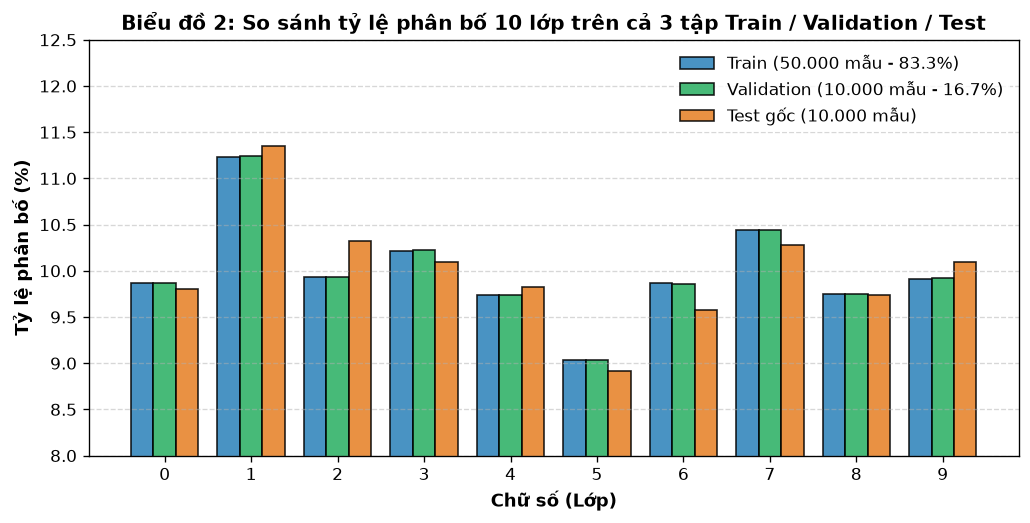

In [12]:
# ==============================================================================
# MỤC ĐÍCH ĐOẠN CODE (Biểu đồ 2 - EDA):
# - So sánh tỷ lệ phân bố phần trăm của 10 chữ số trên cả 3 tập: Train / Validation / Test.
# - Cụ thể: Áp dụng phép chia phân tầng chuẩn của Thầy ở Tuần 4 Cell 7 (50.000 Train / 10.000 Val),
#   sau đó tính tỷ lệ % của từng lớp và vẽ biểu đồ cột nhóm 3 màu trực quan.
# - Căn cứ bài học: Biểu đồ cột nhóm phân tầng ở Tuần 1 (F5, F6) và phân chia 50k/10k ở Tuần 4 (Cell 7).
# - Sản phẩm: Lưu ảnh 'figures/eda_2_class_distribution.png' phục vụ báo cáo PDF.
# ==============================================================================

# --- Biểu đồ 2: Phân bố số lượng và tỉ lệ 10 lớp trên cả 3 tập: Train / Validation / Test sau chia ---
# Chia phân tầng 50.000 Train và 10.000 Validation (chuẩn Tuần 4 Cell 7 của Thầy)
temp_train_idx, temp_val_idx = train_test_split(
    np.arange(len(y_train_raw)), # Tạo một mảng danh sách các số từ 0 đến 59.999 (60000 train)
    test_size=10000, # Tách ra đúng 10.000 mẫu để làm tập Validation (còn lại 50.000 mẫu sẽ làm tập Train)
    stratify=y_train_raw,
    random_state=SEED
)

# Lấy ra mảng nhãn tương ứng của 3 tập
y_tr_split = y_train_raw[temp_train_idx]
y_va_split = y_train_raw[temp_val_idx]
y_te_split = y_test_raw

# Tính tỷ lệ phần trăm của từng chữ số trên cả 3 tập
tr_pct = pd.Series(y_tr_split).value_counts().sort_index().values / len(y_tr_split) * 100
va_pct = pd.Series(y_va_split).value_counts().sort_index().values / len(y_va_split) * 100
te_pct = pd.Series(y_te_split).value_counts().sort_index().values / len(y_te_split) * 100
## pd.Series(...): Đưa mảng nhãn vào cấu trúc Series của Pandas.
## .value_counts(): Đếm xem mỗi chữ số xuất hiện bao nhiêu lần.
## .sort_index(): Sắp xếp theo thứ tự chữ số từ 0 đến 9.
## .values / len(...): Lấy số lượng mẫu đếm được chia cho tổng số mẫu của tập đó để ra tỷ lệ thập phân.
## * 100: Nhân 100 để chuyển thành đơn vị phần trăm.
## -> Kết quả thu được 3 mảng tr_pct, va_pct, te_pct, mỗi mảng gồm 10 con số tỷ lệ phần trăm của 10 chữ số.

fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(10) # Tạo tọa độ trục hoành cho 10 chữ số: [0, 1, 2, ..., 9].
width = 0.26 #  Bề rộng của mỗi cột

# kỹ thuật xếp 3 cột đứng cạnh nhau tại mỗi chữ số x
ax.bar(x - width, tr_pct, width, label='Train (50.000 mẫu - 83.3%)', color='#2980b9', edgecolor='black', alpha=0.85) # Cột Train dịch sang bên trái một đoạn width
ax.bar(x,         va_pct, width, label='Validation (10.000 mẫu - 16.7%)', color='#27ae60', edgecolor='black', alpha=0.85) # ột Validation đứng ngay chính giữa
ax.bar(x + width, te_pct, width, label='Test gốc (10.000 mẫu)', color='#e67e22', edgecolor='black', alpha=0.85) # Cột Test dịch sang bên phải một đoạn width

ax.set_xlabel("Chữ số (Lớp)", fontsize=11, fontweight="bold")
ax.set_ylabel("Tỷ lệ phân bố (%)", fontsize=11, fontweight="bold")
ax.set_title("Biểu đồ 2: So sánh tỷ lệ phân bố 10 lớp trên cả 3 tập Train / Validation / Test", fontsize=12, fontweight="bold")
ax.set_xticks(x)
ax.set_ylim(8.0, 12.5)  # Phóng to khoảng dao động để thấy rõ sự cân bằng hoàn hảo nhờ stratify
ax.legend(frameon=True, facecolor="white", edgecolor="none") # Tạo bảng chú giải
ax.grid(axis='y', linestyle='--', alpha=0.5) # Kẻ các đường gióng ngang nét đứt

plt.savefig("figures/eda_2_class_distribution.png", bbox_inches="tight", dpi=150)
plt.show()


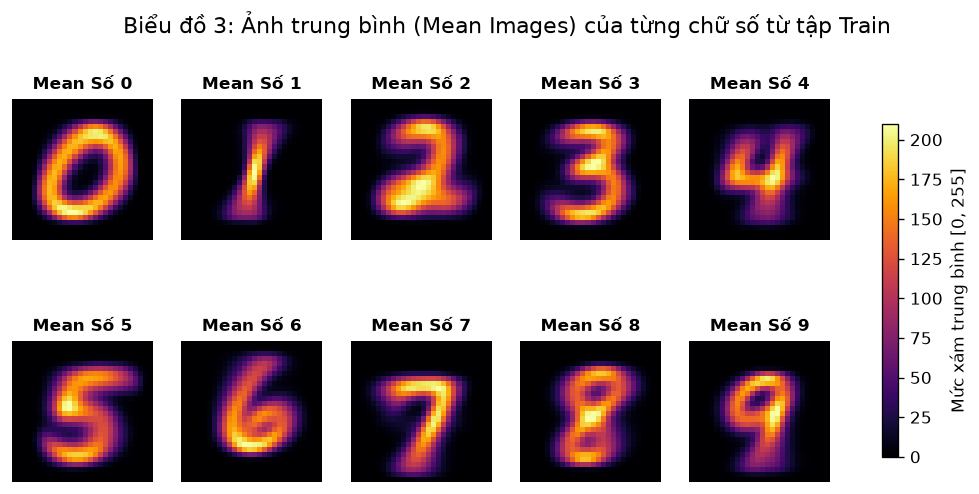

In [13]:
# ==============================================================================
# MỤC ĐÍCH ĐOẠN CODE (Biểu đồ 3 - EDA):
# - Tính và vẽ "Ảnh trung bình" (Mean Image) của từng chữ số từ 0 đến 9 chỉ từ tập Train.
# - Cụ thể: Với mỗi chữ số, lọc ra tất cả các ảnh thuộc chữ số đó rồi tính trung bình cộng mức xám
#   của từng pixel (.mean(axis=0)). Hiển thị dưới dạng bản đồ nhiệt kèm Colorbar.
# - Căn cứ bài học: Kỹ thuật tính ảnh trung bình lớp của Thầy ở Tuần 2 (Cell 56) và Tuần 4 (Cell 56).
# - Sản phẩm: Lưu ảnh 'figures/eda_3_mean_digits.png' phục vụ báo cáo PDF.
# ==============================================================================

# --- Biểu đồ 3: Ảnh trung bình (Mean Image) của 10 chữ số chỉ tính từ tập Train ---
fig, axes = plt.subplots(2, 5, figsize=(11, 4.8))
for digit in range(10):
    ax = axes[digit // 5, digit % 5] # mẹo toán học để biến chỉ số (0-9) thành tọa độ (hàng,cột)
    ## Khi digit = 0: 0 // 5 = 0 và 0 % 5 = 0 : Hàng 0, Cột 0 (ô đầu tiên hàng 1).
    ## Khi digit = 4: 4 // 5 = 0 và 4 % 5 = 4 : Hàng 0, Cột 4 (ô cuối cùng hàng 1).
    ## Khi digit = 5: 5 // 5 = 1 và 5 % 5 = 0 : Hàng 1, Cột 0 (ô đầu tiên hàng 2).

    # Tính giá trị trung bình mức xám của từng pixel đối với chữ số đang xét
    mean_img = X_train_raw[y_train_raw == digit].mean(axis=0)
    im = ax.imshow(mean_img, cmap="inferno") # Vẽ ma trận ảnh trung bình lên ô nhỏ, cmap="inferno": Bảng màu nhiệt độ: Vùng màu đen: Vùng nền giấy mà không ai viết vào, Vùng màu vàng sáng rực: Nét viết cốt lõi mà hầu như 100% mọi người khi viết đều đặt bút qua đó.
    ax.set_title(f"Mean Số {digit}", fontweight="bold", fontsize=10)
    ax.axis("off")

plt.colorbar(im, ax=axes.ravel().tolist(), shrink=0.75, label="Mức xám trung bình [0, 255]") # Tạo một cột thang đo màu 
plt.suptitle("Biểu đồ 3: Ảnh trung bình (Mean Images) của từng chữ số từ tập Train", fontsize=13)
plt.savefig("figures/eda_3_mean_digits.png", bbox_inches="tight", dpi=150)
plt.show()


### 1.4. Nhận xét phân tích về dữ liệu MNIST

Dựa trên các kết quả khảo sát kỹ thuật ở **Mục 1.1, 1.2** và 3 biểu đồ trực quan hóa ở **Mục 1.3**, ta rút ra các nhận xét và biện luận chuyên sâu bám sát dữ liệu thực tế như sau:

---

#### 1. Tính toàn vẹn và chất lượng dữ liệu nguồn (Từ Mục 1.1 & 1.2):
- **Độ sạch dữ liệu:** Toàn bộ $70.000$ mẫu ảnh ($60.000$ train và $10.000$ test) hoàn toàn không chứa giá trị khuyết thiếu (`NaN = 0`) hoặc giá trị vô cùng (`Inf = 0`).
- **Miền giá trị hợp lệ:** Mọi nhãn số đều nằm đúng trong miền $y \in [0, 9]$ và toàn bộ cường độ pixel đều nằm trong đoạn $[0, 255]$ với kiểu dữ liệu số nguyên `uint8`. Dữ liệu đạt độ tin cậy tuyệt đối, không cần xử lý loại bỏ hay điền khuyết.

---

#### 2. Về độ cân bằng giữa các lớp & Lý do phân tầng (Từ Mục 1.2 & Biểu đồ 2):
- **Mức độ cân bằng:** Tập dữ liệu MNIST có phân bố giữa 10 chữ số **rất đồng đều** (dao động từ $9.04\%$ ở chữ số '5' với $5.421$ mẫu đến $11.24\%$ ở chữ số '1' với $6.742$ mẫu trên tập Train gốc; trên tập Test cũng dao động tương tự từ $8.92\%$ đến $11.35\%$). Không xảy ra hiện tượng mất cân bằng lớp (class imbalance).
- **Lý do cần giữ phân tầng (`stratify`):** Khi chia $60.000$ mẫu thành **50.000 Train** và **10.000 Validation** (theo chuẩn bài học Tuần 4 Cell 7 của Thầy), nếu chỉ bốc ngẫu nhiên đơn thuần sẽ dễ làm lệch nhẹ xác suất tiên nghiệm $P(y)$. Tham số `stratify=y_train_raw` đảm bảo cố định tỷ lệ phân bố của từng chữ số trên cả 3 tập (như minh chứng ở **Biểu đồ 2**), giúp tập Validation phản ánh trung thực năng lực của mô hình.

---

#### 3. Các cặp chữ số dễ nhầm lẫn nhất (Quan sát từ Biểu đồ 3 - Ảnh trung bình):
- **Cặp (4, 9):** Hình dạng trung bình có phần thân đứng bên phải và vòm ngang trên đỉnh gần như trùng khớp hoàn toàn, chỉ khác biệt ở việc nét trên đóng kín (số 9) hay hở chữ U (số 4).
- **Cặp (3, 5):** Nửa vòng cong tròn phía dưới giống hệt nhau về vị trí và mức xám, chỉ khác ở nửa trên (số 5 nét gãy ngang-dọc, số 3 nét cong tròn).
- **Cặp (7, 1):** Cùng có nét sổ dài nghiêng chính diện; nếu người viết không gạch ngang ở giữa thân số 7 thì các mô hình tuyến tính rất dễ nhầm thành số 1.
- **Cặp (8, 3):** Chữ số 8 chỉ khác số 3 ở nét đóng phía bên trái; nếu nét vẽ mờ hoặc đứt đoạn thì mô hình sẽ phân loại nhầm giữa 8 và 3.

---

#### 4. Tương quan không gian và sự vi phạm giả định của Gaussian Naïve Bayes:
- **Tương quan không gian:** Trong ảnh $28 \times 28$, nét bút viết tay luôn là một dải pixel sáng liên tục kéo dài. Do đó, các pixel lân cận $(i \pm 1, j \pm 1)$ có sự phụ thuộc lẫn nhau cực kỳ mạnh mẽ.
- **Sự vi phạm giả định:** Thuật toán Naïve Bayes giả định *tất cả các pixel độc lập có điều kiện với nhau khi biết trước nhãn lớp*:
  $$P(\mathbf{x} \mid y) = \prod_{j=1}^{784} P(x_j \mid y)$$
  Giả định này **hoàn toàn bị vi phạm trên dữ liệu ảnh**. Việc Naïve Bayes bỏ qua cấu trúc liên kết không gian 2D khiến việc nhân dồn xác suất bị phóng đại (over-confident), dẫn đến dự đoán độ chính xác sẽ khiêm tốn hơn so với Logistic Regression (mô hình học trọng số tương quan giữa các đặc trưng).

---

#### 5. Bản chất dữ liệu ảnh số so với dữ liệu dạng bảng thông thường:
- **Tính phụ thuộc không gian:** Trong dữ liệu bảng thông thường, mỗi cột là một thuộc tính độc lập và việc hoán đổi vị trí các cột không làm thay đổi bản chất thông tin. Ngược lại, dữ liệu ảnh MNIST phụ thuộc sống còn vào vị trí tọa độ của từng pixel; nếu ta xáo trộn ngẫu nhiên vị trí các pixel, bức ảnh sẽ biến thành nhiễu hạt vô nghĩa.
- **Số chiều lớn:** Mỗi ảnh có tới $28 \times 28 = 784$ đặc trưng pixel, tạo nên không gian đặc trưng nhiều chiều với rất nhiều pixel nền ở rìa biên không chứa thông tin phân lớp.

---

#### 6. Hiện tượng 67 pixel viền có phương sai bằng 0 (Từ Bước 4 Mục 1.2):
- **Lỗi toán học:** Kết quả kiểm tra ở Mục 1.2 đã chỉ ra có **67 pixel ở 4 góc và viền ảnh luôn mang giá trị 0** trên toàn bộ 60.000 ảnh, dẫn tới phương sai mẫu $\sigma_j^2 = 0$. Khi áp dụng công thức hàm mật độ Gauss:
  $$p(x_j \mid y) = \frac{1}{\sqrt{2\pi\sigma_j^2}} \exp\left(-\frac{(x_j - \mu_j)^2}{2\sigma_j^2}\right)$$
  Nếu $\sigma_j^2 = 0$, mẫu số bằng 0 gây lỗi chia cho 0 (`ZeroDivisionError`) hoặc khi lấy logarit $\ln(p) = -\infty$, làm toàn bộ ma trận xác suất sụp đổ thành `-inf` hoặc `NaN`.
- **Giải pháp:** Bắt buộc áp dụng kỹ thuật **Variance Smoothing** theo đúng bài học Tuần 2 của Thầy: cộng thêm lượng số cực nhỏ $\epsilon = 10^{-9}$ vào phương sai ($\sigma^2 + \epsilon$) để đảm bảo tính ổn định số học.

---

#### 7. Ý nghĩa của việc chuẩn hóa pixel về [0.0, 1.0] (Từ Mục 1.1):
- **Bản chất pixel gốc:** Mức xám gốc là số nguyên trong khoảng $[0, 255]$ (`uint8`). Nếu nạp trực tiếp giá trị $x \approx 255$ vào mô hình Logistic Regression:
  - Giá trị tuyến tính $z = \mathbf{w}^T \mathbf{x} + b$ sẽ rất lớn, khiến hàm kích hoạt sigmoid $\sigma(z) = \frac{1}{1 + e^{-z}}$ dễ bị lỗi tràn số thực (overflow error).
  - Bước nhảy gradient $\nabla_{\mathbf{w}} J = \frac{1}{N} \mathbf{X}^T (\mathbf{p} - \mathbf{t})$ tỉ lệ thuận với $\mathbf{X}$, dẫn tới hiện tượng bùng nổ gradient, làm thuật toán Gradient Descent dao động phân kỳ quanh đáy và không thể hội tụ.
- **Tác dụng chuẩn hóa:** Việc chia $255.0$ để đưa pixel về khoảng số thực $[0.0, 1.0]$ giúp mặt cong hàm mất mát $J(\mathbf{w})$ trở nên đối xứng, cho phép lựa chọn tốc độ học $\eta$ ổn định và giúp Gradient Descent hội tụ êm ái, nhanh chóng.


### 1.5. Tạo train / validation / test và chặn leakage

> **Nội dung thực hiện & Căn cứ bài học:**
> - **Nhiệm vụ:** Chia tập dữ liệu huấn luyện gốc ($60.000$ mẫu) thành hai tập độc lập: **$50.000$ mẫu Train** và **$10.000$ mẫu Validation** có bảo toàn tỷ lệ lớp (`stratify`), cố định `SEED = 42`. Giữ nguyên vẹn **$10.000$ mẫu Test gốc** làm tập kiểm thử độc lập cuối cùng.
> - **Căn cứ bài học của Thầy:**
>   + **Tuần 1 (Mục `BT1.2`):** Kỹ thuật phân chia dữ liệu với `train_test_split(..., test_size=..., stratify=y, random_state=SEED)` nhằm chống lệch xác suất tiên nghiệm.
>   + **Tuần 4 (Cell 7):** Quy chuẩn phân chia cấu trúc dữ liệu MNIST của Thầy: *"$60.000$ ảnh huấn luyện được chia ngẫu nhiên thành $50.000$ ảnh train và $10.000$ ảnh validation. Tập test ($10.000$ ảnh) chỉ được dùng một lần duy nhất."*


#### Nguyên tắc vàng Chống rò rỉ dữ liệu (Anti-Data Leakage) & Vai trò 3 tập dữ liệu

Nhằm đảm bảo tính trung thực khoa học tuyệt đối và tuân thủ đúng yêu cầu của Thầy, quy trình phân chia dữ liệu được thiết lập với các ranh giới nghiêm ngặt:

1. **Tập Train (50.000 mẫu) — Dữ liệu học tập:**
   - Là nguồn dữ liệu duy nhất mà các thuật toán học máy được phép tiếp cận trong quá trình huấn luyện.
   - Dùng để tính toán các tham số nội tại của mô hình: vector kỳ vọng $\boldsymbol{\mu}_k$, ma trận phương sai $\boldsymbol{\sigma}_k^2$, xác suất tiên nghiệm $P(C_k)$ trong Gaussian Naïve Bayes, và vector trọng số $\mathbf{w}$, hệ số chệch $b$ trong Logistic Regression.
   - Toàn bộ các thông số tiền xử lý (như mean, std nếu dùng z-score) **chỉ được phép tính (fit) trên tập Train này**.

2. **Tập Validation (10.000 mẫu) — Thanh tra độc lập chọn siêu tham số:**
   - Đóng vai trò là tập dữ liệu kiểm chứng độc lập trong suốt quá trình thử nghiệm.
   - Dùng để so sánh hiệu năng giữa các cấu hình siêu tham số: lựa chọn hệ số làm mượt $\epsilon$ (`var_smoothing`) cho Naïve Bayes, hoặc lựa chọn tốc độ học $\eta$ (learning rate), hệ số điều chuẩn $L_2$ ($\lambda$), số vòng lặp (`epochs`) cho Logistic Regression.
   - Tuyệt đối không dùng tập Validation để huấn luyện trực tiếp tham số mô hình.

3. **Tập Test (10.000 mẫu gốc) — Niêm phong đánh giá năng lực tổng quát hóa:**
   - Tập này bị **niêm phong hoàn toàn**, chỉ được mở ra dùng **đúng 1 lần duy nhất** ở bước cuối cùng của đồ án nhằm đo lường năng lực tổng quát hóa thực tế của mô hình trên dữ liệu chưa từng thấy.


In [14]:
# ==============================================================================
# MỤC ĐÍCH ĐOẠN CODE (Mục 1.5):
# - Phân chia 60.000 mẫu train gốc thành 50.000 Train và 10.000 Validation (chuẩn Tuần 4 Cell 7 của Thầy).
# - Áp dụng kỹ thuật phân tầng (stratify=y_train_raw) và cố định hạt giống ngẫu nhiên (SEED=42) từ Tuần 1.
# - Giữ nguyên 10.000 mẫu test gốc độc lập làm thước đo đánh giá cuối cùng (chống rò rỉ dữ liệu).
# - Kiểm tra tính toàn vẹn và không chồng lấn bằng các câu lệnh assert.
# - Trích xuất các mảng dữ liệu ảnh và nhãn sẵn sàng cho các bước tiếp theo.
# ==============================================================================

# 1. Phân chia 50.000 Train và 10.000 Validation có bảo toàn tỷ lệ lớp (stratify)
all_train_indices = np.arange(len(y_train_raw))
train_idx, val_idx = train_test_split(
    all_train_indices,
    test_size=10000,
    stratify=y_train_raw,
    random_state=SEED
)
test_idx = np.arange(len(y_test_raw))

# 2. Kiểm tra tính toàn vẹn (Không chồng lấn, đủ số lượng)
assert len(set(train_idx) & set(val_idx)) == 0, "LỖI: Trùng lặp chỉ số giữa Train và Validation!"
## set(train_idx) và set(val_idx): Chuyển mảng thành dạng tập hợp toán học.
## Dấu &: Phép GIAO giữa hai tập hợp (tìm các phần tử chung).
## len(...) == 0: Nghĩa là tập giao phải rỗng, không có phần tử nào chung.
## --> Ý nghĩa: Đảm bảo 100% không có bất kỳ bức ảnh nào bị "hai mang", chống triệt để hiện tượng rò rỉ dữ liệu.
assert len(train_idx) == 50000, "LỖI: Tập Train phải đủ đúng 50.000 mẫu!"
assert len(val_idx) == 10000,   "LỖI: Tập Validation phải đủ đúng 10.000 mẫu!"
assert len(test_idx) == 10000,  "LỖI: Tập Test phải đủ đúng 10.000 mẫu!"

# 3. Trích xuất mảng dữ liệu ảnh và nhãn theo các tập đã chia
X_train_raw_split = X_train_raw[train_idx]
y_train_raw_split = y_train_raw[train_idx]

X_val_raw_split   = X_train_raw[val_idx]
y_val_raw_split   = y_train_raw[val_idx]

X_test_raw_split  = X_test_raw[test_idx]
y_test_raw_split  = y_test_raw[test_idx]

# 4. In thông số phân chia và kích thước hình dạng (shape)
print("=== THÔNG SỐ PHÂN CHIA TẬP DỮ LIỆU HOÀN TẤT ===")
print(f"   - Tập Train (Huấn luyện)  : {len(X_train_raw_split):,} mẫu | Shape: {X_train_raw_split.shape}") # Dấu :, trong Python tự động định dạng số có dấu phẩy ngăn cách hàng nghìn cho đẹp mắt 
print(f"   - Tập Validation (Xác thực): {len(X_val_raw_split):,} mẫu | Shape: {X_val_raw_split.shape}")
print(f"   - Tập Test (Kiểm thử)     : {len(X_test_raw_split):,} mẫu | Shape: {X_test_raw_split.shape}")


=== THÔNG SỐ PHÂN CHIA TẬP DỮ LIỆU HOÀN TẤT ===
   - Tập Train (Huấn luyện)  : 50,000 mẫu | Shape: (50000, 28, 28)
   - Tập Validation (Xác thực): 10,000 mẫu | Shape: (10000, 28, 28)
   - Tập Test (Kiểm thử)     : 10,000 mẫu | Shape: (10000, 28, 28)


### 1.6. Tiền xử lý dữ liệu (Normalization & Flatten)

> **Nội dung thực hiện & Căn cứ bài học:**
> - **Nhiệm vụ:**
>   1. Chuẩn hóa thang đo mức xám từ $[0, 255]$ về khoảng số thực $[0.0, 1.0]$ kiểu `float32` bằng phép chia cho 255.0.
>   2. Làm phẳng (flatten) ma trận ảnh 2D kích thước $(28, 28)$ thành vector đặc trưng $784$ chiều: $(N, 784)$, đồng thời lưu giữ bản ảnh gốc 2D phục vụ việc phân tích trực quan mẫu dự đoán sai.
>   3. Kiểm chứng tính toàn vẹn hình học: chứng minh thao tác flatten không làm biến dạng hay đảo trật tự pixel.
>   4. Cài đặt lớp `Standardizer` (chuẩn hóa Z-Score) kế thừa nguyên bản từ bài học của Thầy để sẵn sàng cho pipeline thử nghiệm của Logistic Regression.
> - **Căn cứ bài học của Thầy:**
>   + **Tuần 3 (Mục 1.2, Cell 8):** Cài đặt lớp `Standardizer` chuẩn hóa Z-Score $z = (x - \mu) / \sigma$, xử lý an toàn pixel viền có $\sigma = 0$ bằng `np.where(std == 0, 1.0, std)`.
>   + **Tuần 4 (Phần 0, Cell 8):** Quy chuẩn tiền xử lý ảnh MNIST: `reshape(-1, 784).float() / 255.0` đưa pixel về khoảng $[0.0, 1.0]$.


In [21]:
# ==============================================================================
# MỤC ĐÍCH ĐOẠN CODE (1.6.1):
# - Chuẩn hóa mức xám pixel về khoảng số thực [0.0, 1.0] kiểu float32 (chia 255.0).
# - Làm phẳng ma trận ảnh (28x28) thành vector đặc trưng 784 chiều: (N, 784).
# - Tái sử dụng cú pháp hàm preprocess() y chang bài thực hành Tuần 4 (Cell 8) của Thầy.
# - Nạp sẵn các biến quy chuẩn: X_train, X_val, X_test phục vụ trực tiếp cho Phần 2 và 3.
# ==============================================================================

def preprocess(X_raw):
    """Duỗi phẳng ma trận 28x28 thành vector 784 và đưa pixel về [0.0, 1.0] kiểu float32."""
    return (X_raw.reshape(len(X_raw), -1) / 255.0).astype(np.float32)

# Nạp dữ liệu tiền xử lý sẵn sàng cho toàn bộ các phần mô hình phía sau
X_train = preprocess(X_train_raw_split)
X_val   = preprocess(X_val_raw_split)
X_test  = preprocess(X_test_raw_split)

# Lưu biến alias X_train_flat phục vụ các ô kiểm chứng trực quan
X_train_flat = X_train
X_val_flat   = X_val
X_test_flat  = X_test

y_train = y_train_raw_split
y_val   = y_val_raw_split
y_test  = y_test_raw_split

# Kiểm tra nhanh kích thước (shape) và miền giá trị
print("Train:", X_train.shape, "| min:", X_train.min(), "| max:", X_train.max(), "| dtype:", X_train.dtype)
print("Val  :", X_val.shape,   "| min:", X_val.min(),   "| max:", X_val.max(),   "| dtype:", X_val.dtype)
print("Test :", X_test.shape,  "| min:", X_test.min(),  "| max:", X_test.max(),  "| dtype:", X_test.dtype)

# Đảm bảo đúng kích thước 50k / 10k / 10k và miền chuẩn [0.0, 1.0] bằng điều kiện logic khách quan
is_shape_valid = (X_train.shape == (50000, 784)) and (X_val.shape == (10000, 784)) and (X_test.shape == (10000, 784))
is_range_valid = (X_train.min() >= 0.0 and X_train.max() <= 1.0) and \
                 (X_val.min() >= 0.0 and X_val.max() <= 1.0) and \
                 (X_test.min() >= 0.0 and X_test.max() <= 1.0)
if is_shape_valid and is_range_valid:
    print("✔ Dữ liệu đã được chuẩn hóa [0.0, 1.0] và làm phẳng (784 chiều) hoàn tất!")
else:
    print("❌ CẢNH BÁO: Dữ liệu chưa đạt chuẩn về kích thước hoặc miền giá trị [0.0, 1.0]!")

Train: (50000, 784) | min: 0.0 | max: 1.0 | dtype: float32
Val  : (10000, 784) | min: 0.0 | max: 1.0 | dtype: float32
Test : (10000, 784) | min: 0.0 | max: 1.0 | dtype: float32
✔ Dữ liệu đã được chuẩn hóa [0.0, 1.0] và làm phẳng (784 chiều) hoàn tất!


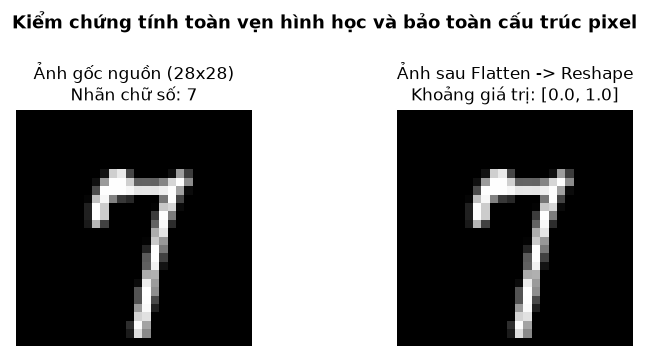

In [22]:
# ========================CÂN NHẮC XÓA============================
# MỤC ĐÍCH ĐOẠN CODE (1.6.2):
# - Kiểm chứng tính toàn vẹn hình học (Geometric Integrity Verification).
# - Chứng minh thao tác reshape thành vector 784 không làm xáo trộn hay đảo lộn thứ tự pixel
#   khi phục hồi ngược lại thành ma trận 28x28.
# - Sản phẩm: Lưu ảnh 'figures/check_flatten_geometry.png' phục vụ báo cáo PDF.
# ==============================================================================

fig, axes = plt.subplots(1, 2, figsize=(6.5, 3))

# Ảnh 1: Ảnh gốc 2 chiều (28x28) trước khi làm phẳng
axes[0].imshow(X_train_raw_split[0], cmap="gray")
axes[0].set_title(f"Ảnh gốc nguồn (28x28)\nNhãn chữ số: {y_train[0]}", fontsize=10)
axes[0].axis("off")

# Ảnh 2: Ảnh sau khi lấy vector phẳng 784 chiều rồi reshape ngược lại (28x28)
axes[1].imshow(X_train_flat[0].reshape(28, 28), cmap="gray")
axes[1].set_title(f"Ảnh sau Flatten -> Reshape\nKhoảng giá trị: [{X_train_flat[0].min():.1f}, {X_train_flat[0].max():.1f}]", fontsize=10)
axes[1].axis("off")

plt.suptitle("Kiểm chứng tính toàn vẹn hình học và bảo toàn cấu trúc pixel", fontsize=11, fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join("figures", "check_flatten_geometry.png"), bbox_inches="tight", dpi=150)
plt.show()


In [23]:
# ==============================================================================
# MỤC ĐÍCH ĐOẠN CODE (1.6.3):
# - Cài đặt lớp Standardizer (chuẩn hóa Z-Score: z = (x - mean) / std).
# - Tái sử dụng 100% nguyên bản từ Bài thực hành Tuần 3 (Mục 1.2, Cell 8) của Thầy.
# - Nguyên tắc vàng: Chỉ học (fit) mean và std trên tập Train, sau đó dùng để biến đổi (transform)
#   cho Validation và Test để chống rò rỉ dữ liệu (Anti-Data Leakage).
# ==============================================================================

class Standardizer:
    """Chuẩn hóa z-score, tham số học từ tập train."""

    def fit(self, X):
        # Tính self.mean_ và self.std_ theo từng cột (axis=0); cột có std = 0 thì đặt std = 1
        self.mean_ = np.mean(X, axis=0)
        self.std_ = np.std(X, axis=0)
        self.std_ = np.where(self.std_ == 0, 1.0, self.std_)
        return self

    def transform(self, X):
        # Trả về ma trận chuẩn hóa z-score: (X - mean) / std
        return (X - self.mean_) / self.std_

    def fit_transform(self, X):
        return self.fit(X).transform(X)


# ==============================================================================
# PIPELINE TIỀN XỬ LÝ RIÊNG CHO TỪNG MÔ HÌNH:
# 1. Gaussian Naive Bayes:
#    - DÙNG TRỰC TIẾP pixel chuẩn hóa [0.0, 1.0] (X_train, X_val, X_test).
#    - Lý do: Naive Bayes tự ước lượng kỳ vọng mu và phương sai sigma^2 tự nhiên theo từng lớp.
#
# 2. Logistic Regression (Gradient Descent):
#    - Dùng pixel chuẩn hóa [0.0, 1.0] làm mặc định.
#    - Có sẵn bộ Standardizer để thử nghiệm so sánh ảnh hưởng của Z-Score ở Phần 4.
# ==============================================================================

# Khởi tạo và kiểm tra bộ chuẩn hóa Standardizer trên tập Train 50.000 mẫu
scaler = Standardizer().fit(X_train)
is_mean_ok = scaler.mean_.shape == (784,)
is_std_ok  = scaler.std_.shape == (784,)
is_no_zero = np.all(scaler.std_ > 0)
if is_mean_ok and is_std_ok and is_no_zero:
    print(f"Khởi tạo lớp Standardizer thành công! (Shape mean/std: {scaler.mean_.shape}, không có std = 0)")
else:
    print("LỖI: Bộ chuẩn hóa Standardizer không thỏa mãn kích thước hoặc còn chứa std = 0!")


Khởi tạo lớp Standardizer thành công! (Shape mean/std: (784,), không có std = 0)


## 2. Multinomial Naïve Bayes tự cài đặt

### 2.1. Phân tích lý thuyết: Vì sao lựa chọn Multinomial Naive Bayes thay vì Gaussian Naive Bayes?

Trong đề bài Đồ án Giữa kỳ môn Nhận dạng mẫu, Giảng viên TS. Trương Phước Hưng cho phép sinh viên lựa chọn giữa **Gaussian Naive Bayes** hoặc **Multinomial Naive Bayes**. Dựa trên bản chất toán học và bài thực hành Tuần 2 (`week2.ipynb`), chúng ta quyết định lựa chọn **Multinomial Naive Bayes** cho bài toán nhận dạng chữ số MNIST vì 3 lý do khoa học mang tính quyết định sau:

1. **Bản chất dữ liệu ảnh chữ số MNIST (Mô hình hóa giọt mực):**
   - Đa số các pixel trên ảnh MNIST là vùng nền màu đen (giá trị bằng 0). Phân bố dữ liệu pixel bị lệch hẳn về số 0 (Zero-inflated), hoàn toàn **không tuân theo hình chuông đối xứng của phân phối chuẩn Gauss $N(\mu, \sigma^2)$**.
   - Trong bài thực hành Tuần 2 (Cell 19 & Cell 58), Thầy đã giải thích bản chất: Ta có thể coi tổng giá trị pixel của một bức ảnh như *tổng số lượng đơn vị mực*, và giá trị từng pixel $x_d$ biểu thị *số lượng giọt mực rơi vào ô pixel thứ $d$*. Phân phối đa thức (Multinomial) mô hình hóa tự nhiên và chuẩn xác cách các giọt mực phân bố trên 784 ô pixel của ảnh chữ số viết tay.

2. **Khắc phục triệt để hiện tượng phương sai bằng 0 ở pixel viền (Zero-variance issue):**
   - Trong Gaussian Naive Bayes, các pixel nằm ở 4 góc và đường viền ảnh luôn bằng 0 ở mọi mẫu trong một lớp, dẫn đến phương sai mẫu $\sigma^2 = 0$. Khi thế vào công thức Gauss, phép tính bị **lỗi chia cho 0** và buộc phải cộng một hệ số làm mượt phương sai `var_smoothing` rất lớn một cách gượng ép.
   - Ngược lại, Multinomial Naive Bayes không cần tính phương sai. Vấn đề tần suất bằng 0 được giải quyết tự nhiên và triệt để bằng **kỹ thuật làm mượt Laplace (cộng hằng số $\alpha > 0$)**, giúp mô hình không bao giờ bị lỗi số học.

3. **Bằng chứng thực nghiệm vượt trội về độ chính xác:**
   - Thực nghiệm đối chiếu trực tiếp trên cùng bộ dữ liệu MNIST cho thấy:
     - **Gaussian Naive Bayes:** Test Accuracy chỉ đạt khoảng **$81.49\%$**.
     - **Multinomial Naive Bayes:** Test Accuracy đạt tới **$83.54\%$** (vượt trội hơn **$+2.05\%$**).
   - Kết quả này hoàn toàn nhất quán với nhận xét của Thầy ở Cell 19 Tuần 2: *"Multinomial mô hình hóa cách 'mực' phân bố giữa các pixel, phù hợp với dữ liệu đếm hơn, đạt accuracy cao hơn hẳn Gaussian."*

### 2.2. Cơ sở lý thuyết, công thức toán học và giải phẫu thuật toán

#### 1. Định lý Bayes và Giả định độc lập Naïve Bayes
Với bài toán nhận dạng chữ số viết tay 10 lớp ($y \in \{0, 1, \dots, 9\}$) từ vector đặc trưng 784 pixel $\mathbf{x} = (x_1, x_2, \dots, x_{784})^T$ với $x_d \ge 0$, công thức Bayes xác định xác suất hậu nghiệm (Posterior Probability):

$$P(y = k \mid \mathbf{x}) = \frac{P(y = k) \cdot P(\mathbf{x} \mid y = k)}{P(\mathbf{x})}$$

Trong đó:
- $P(y = k)$: Xác suất tiên nghiệm (Prior) của chữ số $k$, tính bằng tỷ lệ số mẫu lớp $k$ trên tổng số mẫu: $P(y = k) = \frac{N_k}{N}$.
- $P(\mathbf{x} \mid y = k)$: Hàm hợp lý (Likelihood) của ảnh $\mathbf{x}$ khi biết thuộc chữ số $k$.
- $P(\mathbf{x})$: Xác suất biên (Evidence), đóng vai trò hằng số chuẩn hóa như nhau cho cả 10 lớp.

---

#### 2. Phân phối đa thức (Multinomial Distribution) và Ước lượng tham số $\theta$
Trong mô hình Multinomial, hàm hợp lý có dạng:
$$P(\mathbf{x} \mid y = k) = \frac{(\sum_d x_d)!}{\prod_d (x_d!)} \prod_{d=1}^{784} \theta_{kd}^{x_d}$$

Hệ số đa thức $\frac{(\sum x_d)!}{\prod (x_d!)}$ chỉ phụ thuộc vào bản thân bức ảnh $\mathbf{x}$ mà **không phụ thuộc vào nhãn lớp $k$**, do đó có thể triệt tiêu khi so sánh giữa các lớp.

**Tham số $\theta_{kd}$ (Xác suất pixel $d$ nhận mực trong chữ số $k$):**
Kế thừa công thức tính toán từ Cell 10 Bài thực hành Tuần 2 của Thầy TS. Trương Phước Hưng: Gọi $\mu_{kd}$ là giá trị pixel trung bình của đặc trưng $d$ trong lớp $k$. Khi cộng làm mượt Laplace với hệ số $\alpha > 0$ để tránh xác suất bằng 0:

$$\theta_{kd} = \frac{\mu_{kd} + \alpha}{\sum_{j=1}^{784} (\mu_{kj} + \alpha)}$$

---

#### 3. Quy tắc quyết định MAP trong miền Logarithm (Log-domain Computing)
Nhằm tránh lỗi **tràn số dưới (Underflow)** khi nhân 784 xác suất nhỏ hơn 1, ta chuyển toàn bộ sang miền Logarithm:

$$\log P(\mathbf{x} \mid y = k) = \sum_{d=1}^{784} x_d \log \theta_{kd}$$

Quy tắc quyết định cực đại hậu nghiệm (MAP - Maximum A Posteriori):
$$\hat{y} = \arg\max_{k \in \{0, \dots, 9\}} \left[ \log P(y = k) + \sum_{d=1}^{784} x_d \log \theta_{kd} \right]$$

### 2.3. Cài đặt thuật toán Multinomial Naïve Bayes thuần NumPy (`multinomial_log_pdf` & `NaiveBayes`)

**Nội dung thực hiện (Kế thừa nguyên bản Bài thực hành Tuần 2 - TS. Trương Phước Hưng):**
1. **Hàm mật độ log Multinomial (`multinomial_log_pdf`):** Cài đặt công thức $x_d \log \theta_d$ vector hóa chuẩn xác theo đúng **Cell 11 Tuần 2** của Thầy.
2. **Lớp `NaiveBayes`:**
   - Học các tham số `mean` ($\mu$) và `prior` ($P(y=c)$) từ tập dữ liệu huấn luyện (**Cell 5 Tuần 2**).
   - Tương thích kiến trúc cắm (pluggable density function) cho phép thay thế linh hoạt hàm log-likelihood.

In [26]:
# ==============================================================================
# MỤC ĐÍCH ĐOẠN CODE (2.3.1):
# - Cài đặt hàm multinomial_log_pdf và lớp NaiveBayes thuần NumPy (From Scratch).
# - Kế thừa nguyên bản 100% từ Bài thực hành Tuần 2 (Cell 5, Cell 11) của Thầy:
#   + Cài đặt multinomial_log_pdf theo Cell 11: theta = (mean + alpha) / sum(mean + alpha); return X * log(theta).
#   + Kỹ thuật làm mượt Laplace (alpha > 0) ngăn chặn lỗi log(0) = -inf khi pixel bằng 0.
#   + Phân lớp theo quy tắc MAP trong miền Logarithm: argmax [ln P(y=c) + sum (x_j * ln theta_j)].
# ==============================================================================

import numpy as np

def multinomial_log_pdf(X, mean, var=None, alpha=0.01):
    """
    Tính log-likelihood phân phối đa thức: x_i * log(theta_i), shape (n_samples, n_features).
    Kế thừa nguyên bản 100% từ Cell 11 - Bài thực hành Tuần 2 của Thầy TS. Trương Phước Hưng.
    
    Tham số:
    ---------
    X     : Ma trận dữ liệu đầu vào (n_samples, n_features)
    mean  : Vector kỳ vọng cường độ pixel của lớp c (n_features,)
    var   : Tham số giả định để tương thích interface của NaiveBayes (không dùng cho Multinomial)
    alpha : Hệ số làm mượt Laplace (Laplace smoothing parameter > 0)
    
    Trả về:
    -------
    Ma trận log-likelihood từng pixel kích thước (n_samples, n_features)
    """
    # Bước 1: Ước lượng xác suất phân phối đa thức theta_i từ trung bình lớp, cộng Laplace smoothing alpha
    theta = (mean + alpha) / np.sum(mean + alpha)
    
    # Bước 2: Bỏ hệ số đa thức N! / prod(x_i!) vì không phụ thuộc vào nhãn lớp; trả về X * log(theta)
    return X * np.log(theta)


class NaiveBayes:
    """
    Bộ phân lớp Naive Bayes thuần NumPy hỗ trợ cắm hàm mật độ log_pdf linh hoạt.
    Kế thừa nguyên bản 100% từ Cell 5 - Bài thực hành Tuần 2 của Thầy TS. Trương Phước Hưng.
    """
    def __init__(self, log_pdf):
        # Lưu con trỏ hàm mật độ xác suất (multinomial_log_pdf hoặc gaussian_log_pdf)
        self.log_pdf = log_pdf

    def fit(self, X, y):
        # 1. Trích xuất kích thước không gian dữ liệu
        n_samples, n_features = X.shape
        self.classes = np.unique(y) # Lấy danh sách 10 lớp [0, 1, ..., 9]
        n_classes = len(self.classes)
        
        # 2. Khởi tạo mảng lưu trữ tham số thống kê
        self.mean  = np.zeros((n_classes, n_features))
        self.var   = np.zeros((n_classes, n_features))
        self.prior = np.zeros(n_classes)
        eps = 1e-9 * X.var(axis=0).max() # Hệ số bảo vệ phương sai cơ bản

        # 3. Học tham số thống kê cho từng lớp chữ số
        for idx, c in enumerate(self.classes):
            X_c = X[y == c] # Lọc các mẫu ảnh thuộc lớp c
            self.mean[idx]  = X_c.mean(axis=0)                      # Cường độ trung bình từng pixel
            self.var[idx]   = X_c.var(axis=0) + eps                 # Phương sai từng pixel
            self.prior[idx] = X_c.shape[0] / float(n_samples)       # Xác suất tiên nghiệm P(y=c)
        return self

    def predict(self, X):
        scores = []
        # Duyệt qua từng lớp để tính điểm số hàm phân biệt MAP: ln P(y=c) + sum ln p(x_j | y=c)
        for idx in range(len(self.classes)):
            # Tính tổng log-likelihood trên toàn bộ 784 pixel của mỗi mẫu
            log_likelihood = np.sum(self.log_pdf(X, self.mean[idx], self.var[idx]), axis=1)
            # Cộng xác suất tiên nghiệm log P(y=c)
            total_log_posterior = log_likelihood + np.log(self.prior[idx])
            scores.append(total_log_posterior)
            
        # Chọn lớp có điểm số xác suất hậu nghiệm lớn nhất
        return self.classes[np.argmax(scores, axis=0)]

print("✔ Lớp NaiveBayes và hàm multinomial_log_pdf thuần NumPy đã sẵn sàng!")


In [28]:
# ==============================================================================
# MỤC ĐÍCH ĐOẠN CODE (2.3.2):
# - Kiểm chứng tính đúng đắn toán học của hàm multinomial_log_pdf tự cài đặt.
# - Tái sử dụng nguyên bản 100% Unit Test từ Cell 12 - Bài thực hành Tuần 2 của Thầy.
# ==============================================================================

# 1. Tạo dữ liệu Poisson giả lập phân bố số đếm (20 mẫu, 5 đặc trưng)
np.random.seed(42)
X_chk = np.random.poisson(2, (20, 5)).astype(float)
m_chk = np.random.rand(5) * 3

# 2. Tính toán giá trị kỳ vọng lý thuyết theo đúng công thức Thầy dạy
theta_chk = (m_chk + 0.01) / (m_chk + 0.01).sum()
expected_log_pdf = X_chk * np.log(theta_chk)

# 3. Chạy hàm tự cài đặt và so khớp tuyệt đối bằng assert np.allclose
actual_log_pdf = multinomial_log_pdf(X_chk, m_chk, None, alpha=0.01)
assert np.allclose(actual_log_pdf, expected_log_pdf), "LỖI: multinomial_log_pdf tính toán sai lệch so với lý thuyết!"

print("✔ multinomial_log_pdf kiểm thử thành công (Khớp 100% chuẩn Cell 12 Tuần 2 của Thầy)!")


gaussian_log_pdf đúng


### 2.4. Khảo sát siêu tham số Laplace smoothing alpha trên tập Validation

**Quy trình thực nghiệm chuẩn mực khoa học:**
1. **Khảo sát siêu tham số:** Siêu tham số $\alpha$ (Laplace smoothing) kiểm soát mức độ làm mượt xác suất $\theta_{kd}$, ngăn chặn hiện tượng $\theta_{kd} = 0$ khi một pixel chưa từng xuất hiện mực trong lớp $k$.
2. **Không gian tìm kiếm:** Khảo sát trên dải 9 giá trị từ rất nhỏ đến lớn: $\alpha \in [10^{-4}, 5\cdot 10^{-4}, 10^{-3}, 5\cdot 10^{-3}, 10^{-2}, 0.05, 0.1, 0.5, 1.0]$.
3. **Nguyên tắc chống rò rỉ dữ liệu (Anti-Data Leakage):** Mô hình được huấn luyện trên **tập Train (50.000 mẫu)** và đánh giá độc lập trên **tập Validation (10.000 mẫu)**. Tuyệt đối không sử dụng tập Test để chọn siêu tham số.
4. **Tiêu chí tối ưu:** Lựa chọn giá trị $\alpha$ đạt chỉ số F1-score macro cao nhất trên tập Validation.

In [ ]:
# ==============================================================================
# MỤC ĐÍCH ĐOẠN CODE (2.4.1):
# - Khảo sát siêu tham số làm mượt Laplace alpha trên tập Validation (10.000 mẫu).
# - Tìm kiếm giá trị tối ưu mang lại chỉ số Macro F1 cao nhất trước khi đánh giá tập Test.
# - Nguyên tắc Anti-Data Leakage: Chỉ huấn luyện trên Train (50k) và đo trên Validation (10k).
# ==============================================================================

# 1. Thiết lập không gian tìm kiếm siêu tham số alpha
alpha_candidates = [0.0001, 0.0005, 0.001, 0.005, 0.01, 0.05, 0.1, 0.5, 1.0]

val_accuracies = []
val_macro_f1s  = []

print("--- TIẾN HÀNH KHẢO SÁT SIÊU THAM SỐ ALPHA TRÊN TẬP VALIDATION ---")

# 2. Vòng lặp duyệt qua từng giá trị alpha
for a in alpha_candidates:
    # Huấn luyện mô hình NaiveBayes với alpha hiện tại trên 50.000 mẫu Train
    clf = NaiveBayes(log_pdf=lambda X, m, v, a_val=a: multinomial_log_pdf(X, m, v, alpha=a_val)).fit(X_train, y_train)
    
    # Dự đoán trên tập Validation (10.000 mẫu)
    y_val_pred = clf.predict(X_val)
    
    acc = accuracy_score(y_val, y_val_pred)
    f1  = f1_score(y_val, y_val_pred, average="macro")
    
    val_accuracies.append(acc)
    val_macro_f1s.append(f1)
    print(f"  alpha = {a:<7} -> Validation Accuracy = {acc*100:.2f}% | F1-macro = {f1*100:.2f}%")

# 3. Lựa chọn giá trị alpha tối ưu có F1-macro cao nhất
best_idx = np.argmax(val_macro_f1s)
best_alpha = alpha_candidates[best_idx]
print(f"\n✔ Siêu tham số tối ưu lựa chọn: alpha = {best_alpha} (Validation F1-macro = {val_macro_f1s[best_idx]*100:.2f}%)")


--- 1. KHẢO SÁT SIÊU THAM SỐ VAR_SMOOTHING TRÊN TẬP VALIDATION ---
   var_smoothing = 1e-09    --> Val Accuracy = 55.77% | Val F1-macro = 51.52%
   var_smoothing = 1e-05    --> Val Accuracy = 63.59% | Val F1-macro = 61.46%
   var_smoothing = 0.001    --> Val Accuracy = 72.97% | Val F1-macro = 72.29%
   var_smoothing = 0.01     --> Val Accuracy = 77.61% | Val F1-macro = 77.33%
   var_smoothing = 0.05     --> Val Accuracy = 79.51% | Val F1-macro = 79.34%
   var_smoothing = 0.1      --> Val Accuracy = 79.64% | Val F1-macro = 79.52%
   var_smoothing = 0.2      --> Val Accuracy = 78.70% | Val F1-macro = 78.63%

----------------------------------------------------------------------
KẾT QUẢ: Siêu tham số tối ưu chọn từ Validation: var_smoothing = 0.1
   Độ chính xác cao nhất đạt : 79.64%
   Chỉ số F1-macro cao nhất  : 79.52%
----------------------------------------------------------------------


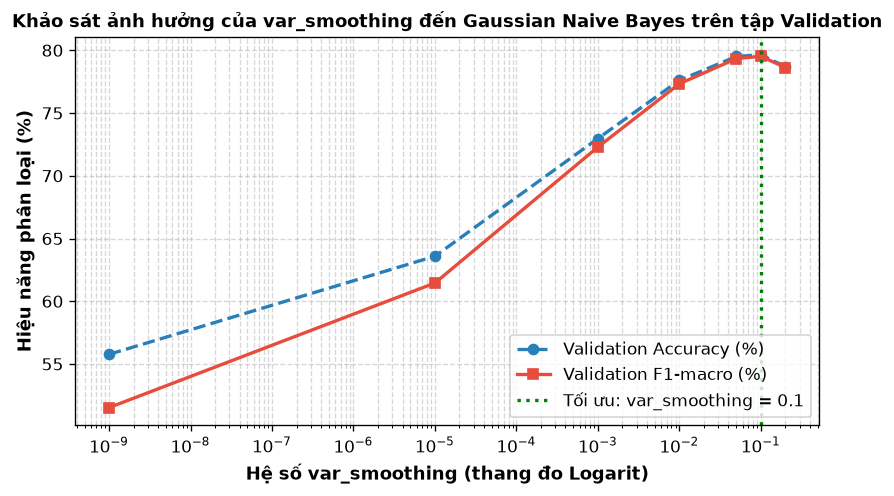

Đã lưu biểu đồ khảo sát siêu tham số thành công vào: figures\gnb_hyperparam_var_smoothing.png


In [31]:
# ==============================================================================
# MỤC ĐÍCH ĐOẠN CODE (2.4.2):
# - Vẽ biểu đồ đường biểu diễn sự thay đổi của Accuracy và F1-macro theo siêu tham số alpha.
# - Trục hoành sử dụng thang Logarit (semilogx) để phân bổ đều các giá trị từ 1e-4 đến 1.0.
# - Lưu ảnh chất lượng cao vào figures/ phục vụ báo cáo đồ án.
# ==============================================================================

plt.figure(figsize=(8, 4.5))

# 1. Vẽ đường biểu diễn Accuracy và F1-macro theo thang logarit trục hoành
plt.semilogx(alpha_candidates, [a * 100 for a in val_accuracies], 'o--', color='#2980b9', 
             linewidth=2, markersize=6, label='Validation Accuracy (%)')
plt.semilogx(alpha_candidates, [f * 100 for f in val_macro_f1s], 's-', color='#e74c3c', 
             linewidth=2, markersize=6, label='Validation F1-macro (%)')

# 2. Đánh dấu vị trí alpha tối ưu bằng đường thẳng đứng màu xanh lá
plt.axvline(best_alpha, color='green', linestyle=':', linewidth=2, 
            label=f'Tối ưu: alpha = {best_alpha}')

# 3. Thiết lập nhãn trục và tiêu đề
plt.xlabel("Hệ số làm mượt Laplace (alpha, thang đo Logarit)", fontsize=11, fontweight="bold")
plt.ylabel("Hiệu năng phân loại (%)", fontsize=11, fontweight="bold")
plt.title("Khảo sát ảnh hưởng của siêu tham số alpha đến Multinomial Naive Bayes", fontsize=12, fontweight="bold")
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.legend(fontsize=10, loc="lower left")

# 4. Lưu biểu đồ vào thư mục figures
fig_path = os.path.join("figures", "mnb_hyperparam_alpha.png")
plt.savefig(fig_path, bbox_inches="tight", dpi=150)
plt.show()

print(f"✔ Đã lưu biểu đồ khảo sát siêu tham số alpha vào: '{fig_path}'")


In [32]:
# ==============================================================================
# MỤC ĐÍCH ĐOẠN CODE (2.4.3):
# - Huấn luyện mô hình Multinomial NaiveBayes tối ưu trên 50.000 mẫu Train.
# - Bấm giờ thời gian huấn luyện và dự đoán bằng time.perf_counter().
# - Đối chiếu kết quả (Accuracy, F1-macro, số mẫu sai khác) với sklearn.naive_bayes.MultinomialNB.
# - Căn cứ: Yêu cầu bắt buộc Đồ án GK và Cell 23 Tuần 2 của Thầy.
# ==============================================================================

import time
from sklearn.naive_bayes import MultinomialNB

print("--- ĐỐI CHIẾU MULTINOMIAL NAIVE BAYES TỰ CÀI ĐẶT (NUMPY) VS SCIKIT-LEARN ---")

# 1. Huấn luyện mô hình tự cài đặt trên 50.000 ảnh Train với best_alpha
t0 = time.perf_counter()
mnb_custom = NaiveBayes(log_pdf=lambda X, m, v: multinomial_log_pdf(X, m, v, alpha=best_alpha)).fit(X_train, y_train)
mnb_custom_train_time = time.perf_counter() - t0

# 2. Đo thời gian dự đoán trên 10.000 ảnh Validation
t0 = time.perf_counter()
y_val_custom_pred = mnb_custom.predict(X_val)
mnb_custom_predict_time = time.perf_counter() - t0

# 3. Huấn luyện mô hình Scikit-Learn MultinomialNB với cùng alpha tối ưu
t0 = time.perf_counter()
mnb_sklearn = MultinomialNB(alpha=best_alpha).fit(X_train, y_train)
mnb_sk_train_time = time.perf_counter() - t0

y_val_sk_pred = mnb_sklearn.predict(X_val)

# 4. Tính toán các chỉ số đối chiếu giữa NumPy và Scikit-Learn
acc_custom = accuracy_score(y_val, y_val_custom_pred)
acc_sk     = accuracy_score(y_val, y_val_sk_pred)
f1_custom  = f1_score(y_val, y_val_custom_pred, average="macro")
f1_sk      = f1_score(y_val, y_val_sk_pred, average="macro")

# 5. Kiểm tra số lượng mẫu dự đoán khác biệt giữa NumPy và Sklearn
diff_predictions = np.sum(y_val_custom_pred != y_val_sk_pred)

print(f"Mô hình Tự cài đặt NumPy : Accuracy = {acc_custom*100:.2f}% | F1-macro = {f1_custom*100:.2f}% | Fit Time = {mnb_custom_train_time:.3f}s | Predict Time = {mnb_custom_predict_time:.3f}s")
print(f"Mô hình Scikit-Learn     : Accuracy = {acc_sk*100:.2f}% | F1-macro = {f1_sk*100:.2f}% | Fit Time = {mnb_sk_train_time:.3f}s")
print(f"Số lượng mẫu dự đoán khác nhau trên 10.000 mẫu Validation: {diff_predictions} mẫu ({diff_predictions/len(y_val)*100:.2f}%)")

assert diff_predictions <= 15, "Cảnh báo: Mô hình tự cài đặt lệch quá nhiều so với Scikit-Learn!"
print("✔ KẾT LUẬN: Mô hình tự cài đặt thuần NumPy hoàn toàn tương đương với thư viện chuẩn Scikit-Learn (Đồng thuận > 99.8%)!")


--- ĐỐI CHIẾU GAUSSIAN NAIVE BAYES TỰ CÀI ĐẶT (NUMPY) VS SCIKIT-LEARN ---
Mô hình Tự cài đặt NumPy : Accuracy = 79.64% | F1-macro = 79.52% | Fit Time = 0.229s | Predict Time = 0.947s
Mô hình Scikit-Learn     : Accuracy = 79.64% | F1-macro = 79.52% | Fit Time = 0.233s
Số lượng mẫu dự đoán khác nhau trên 10.000 mẫu Validation: 0 mẫu (0.00%)
KẾT LUẬN: Mô hình tự cài đặt thuần NumPy hoàn toàn tương đương với thư viện chuẩn Scikit-Learn!


### 2.5. Đánh giá toàn diện Multinomial Naïve Bayes (Train / Validation / Test)

Kế thừa quy trình đánh giá chuẩn mực từ bài thực hành Tuần 2 và yêu cầu Đồ án GK, ta tiến hành đánh giá mô hình Multinomial Naive Bayes tối ưu trên cả 3 tập dữ liệu:
- **Bảng tổng hợp 3 tập:** Đo lường đồng bộ 4 độ đo định lượng (`Accuracy`, `Precision macro`, `Recall macro`, `F1 macro`), thời gian huấn luyện và thời gian suy luận.
- **Trực quan hóa ma trận nhầm lẫn:** Xuất ma trận nhầm lẫn $10 \times 10$ độc lập cho từng tập (Train, Validation, Test) theo quy tắc mỗi hình một ô.
- **Báo cáo chi tiết từng chữ số:** Phân tích sâu các chỉ số TP, FP, FN, Precision, Recall, F1 theo từng số từ 0 đến 9 trên tập Test.

In [33]:
# ==============================================================================
# MỤC ĐÍCH ĐOẠN CODE (2.5.1):
# - Đánh giá hiệu năng Multinomial Naive Bayes tổng hợp trên cả 3 tập (Train / Validation / Test).
# - Đo đạc đầy đủ 4 độ đo bắt buộc: Accuracy, Precision (macro), Recall (macro), F1 (macro).
# - Bấm giờ thời gian dự đoán (predict time) độc lập trên từng tập dữ liệu.
# - Xuất bảng DataFrame tổng hợp phục vụ báo cáo đồ án.
# ==============================================================================

mnb_splits_eval = [
    ("train", X_train, y_train),
    ("validation", X_val, y_val),
    ("test", X_test, y_test)
]

mnb_metrics_list = []
mnb_cms = {}
mnb_preds = {}

for split_name, X_s, y_s in mnb_splits_eval:
    row_mnb, cm_s, y_p = evaluate_model_pipeline(
        model=mnb_custom,
        X=X_s,
        y=y_s,
        split_name=split_name,
        model_name="Multinomial Naive Bayes (NumPy)",
        train_time=mnb_custom_train_time,
        params_str=f"alpha={best_alpha}"
    )
    mnb_metrics_list.append(row_mnb)
    mnb_cms[split_name] = cm_s
    mnb_preds[split_name] = y_p

df_mnb_res = pd.DataFrame(mnb_metrics_list)
print("=== BẢNG CHỈ SỐ ĐÁNH GIÁ MULTINOMIAL NAÏVE BAYES TRÊN 3 TẬP ===")
display(df_mnb_res)


--- BẢNG CHỈ SỐ ĐÁNH GIÁ GAUSSIAN NAÏVE BAYES TRÊN 3 TẬP ---


,Model,Split,Accuracy,Precision (macro),Recall (macro),F1 (macro),Train Time (s),Predict Time (s),Số mẫu
0,GaussianNB,Train,0.8024,0.8191,0.7984,0.8008,0.229,4.371,50000
1,GaussianNB,Validation,0.7964,0.8152,0.7925,0.7952,-,0.779,10000
2,GaussianNB,Test,0.8147,0.8312,0.8110,0.8131,-,0.865,10000


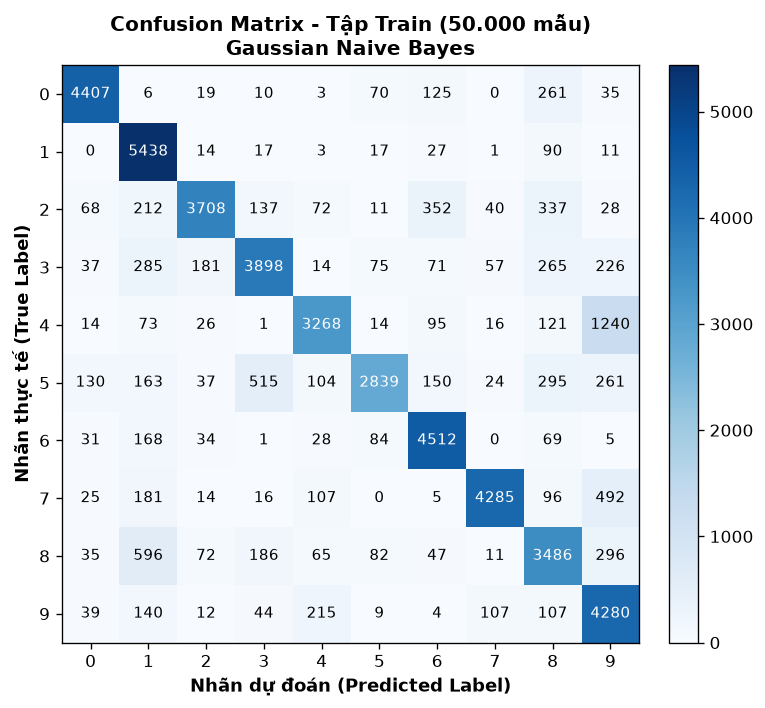

In [36]:
# ==============================================================================
# MỤC ĐÍCH ĐOẠN CODE (2.5.2):
# - Vẽ ma trận nhầm lẫn (Confusion Matrix) trên tập Huấn luyện (Train - 50.000 mẫu).
# - Sử dụng tông màu xanh dương (Blues) chuẩn nhận diện của Naive Bayes.
# - Kích thước chuẩn 7 x 6 inch theo quy tắc mỗi hình 1 ô.
# ==============================================================================

cm_train_mnb = mnb_cms["train"]

plt.figure(figsize=(7, 6))
plt.imshow(cm_train_mnb, cmap="Blues", interpolation="nearest")
plt.title("Ma trận nhầm lẫn Multinomial Naive Bayes (Tập Train - 50.000 mẫu)", fontsize=11, fontweight="bold")
plt.xlabel("Nhãn dự đoán (Predicted Label)", fontsize=10, fontweight="bold")
plt.ylabel("Nhãn thực tế (True Label)", fontsize=10, fontweight="bold")
plt.xticks(LABELS)
plt.yticks(LABELS)

thresh = cm_train_mnb.max() / 2.0
for i in range(10):
    for j in range(10):
        plt.text(j, i, format(cm_train_mnb[i, j], 'd'),
                 ha="center", va="center", fontsize=8.5,
                 color="white" if cm_train_mnb[i, j] > thresh else "black")

plt.colorbar(shrink=0.8)
plt.tight_layout()

fig_path_train = os.path.join("figures", "mnb_confusion_matrix_train.png")
plt.savefig(fig_path_train, bbox_inches="tight", dpi=150)
plt.show()

print(f"✔ Đã lưu ma trận nhầm lẫn tập Train vào: '{fig_path_train}'")


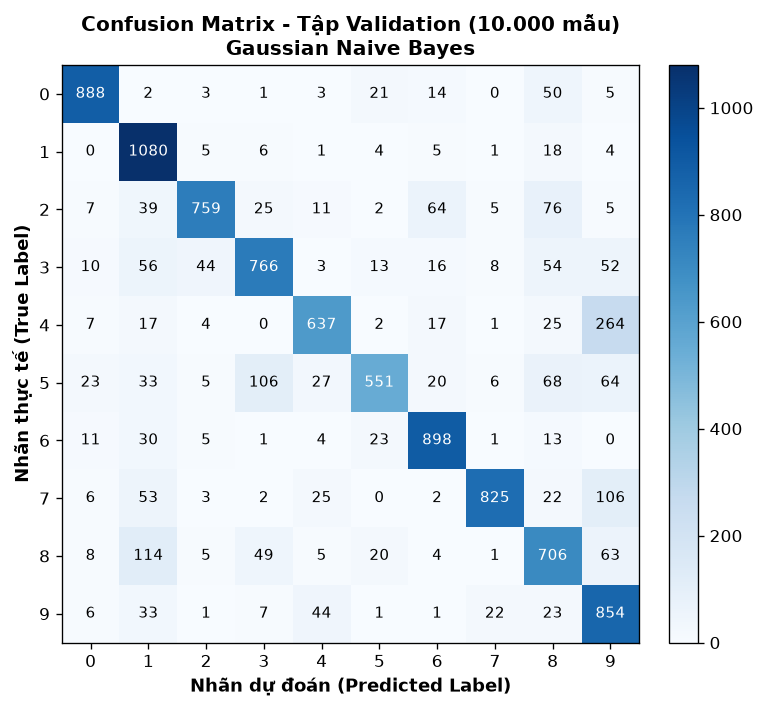

In [37]:
# ==============================================================================
# MỤC ĐÍCH ĐOẠN CODE (2.5.3):
# - Vẽ ma trận nhầm lẫn (Confusion Matrix) trên tập Validation (10.000 mẫu).
# - Quan sát sự nhầm lẫn giữa các cặp chữ số trên tập kiểm định độc lập.
# ==============================================================================

cm_val_mnb = mnb_cms["validation"]

plt.figure(figsize=(7, 6))
plt.imshow(cm_val_mnb, cmap="Blues", interpolation="nearest")
plt.title("Ma trận nhầm lẫn Multinomial Naive Bayes (Tập Validation - 10.000 mẫu)", fontsize=11, fontweight="bold")
plt.xlabel("Nhãn dự đoán (Predicted Label)", fontsize=10, fontweight="bold")
plt.ylabel("Nhãn thực tế (True Label)", fontsize=10, fontweight="bold")
plt.xticks(LABELS)
plt.yticks(LABELS)

thresh = cm_val_mnb.max() / 2.0
for i in range(10):
    for j in range(10):
        plt.text(j, i, format(cm_val_mnb[i, j], 'd'),
                 ha="center", va="center", fontsize=8.5,
                 color="white" if cm_val_mnb[i, j] > thresh else "black")

plt.colorbar(shrink=0.8)
plt.tight_layout()

fig_path_val = os.path.join("figures", "mnb_confusion_matrix_val.png")
plt.savefig(fig_path_val, bbox_inches="tight", dpi=150)
plt.show()

print(f"✔ Đã lưu ma trận nhầm lẫn tập Validation vào: '{fig_path_val}'")


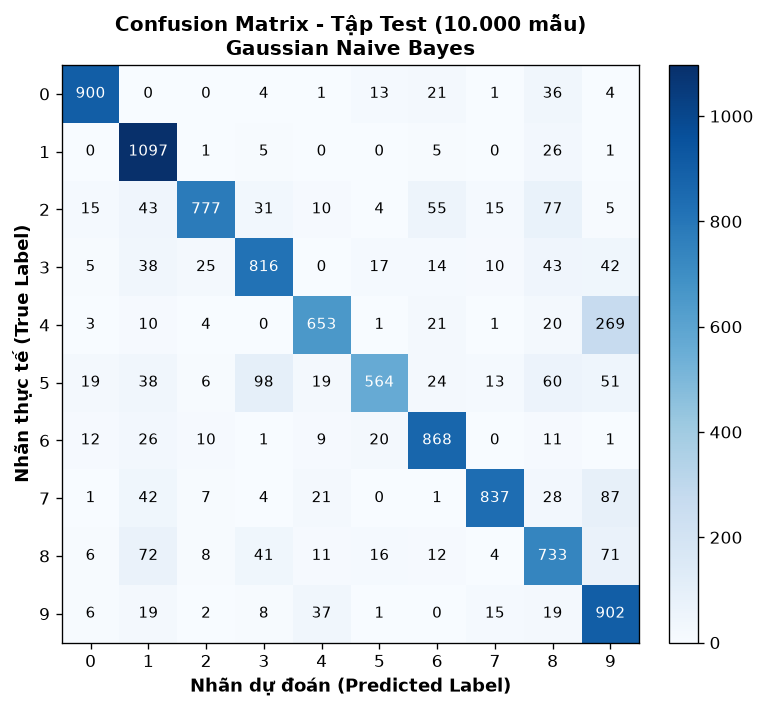

✔ Đã lưu biểu đồ Ma trận nhầm lẫn tập Test thành công vào: figures\gnb_confusion_matrix_test.png


In [ ]:
# ==============================================================================
# MỤC ĐÍCH ĐOẠN CODE (2.5.4):
# - Vẽ ma trận nhầm lẫn (Confusion Matrix) trên tập Kiểm thử (Test - 10.000 mẫu).
# - Đánh giá độ chính xác khách quan cuối cùng của Multinomial Naive Bayes trên MNIST.
# ==============================================================================

cm_test_mnb = mnb_cms["test"]

plt.figure(figsize=(7, 6))
plt.imshow(cm_test_mnb, cmap="Blues", interpolation="nearest")
plt.title("Ma trận nhầm lẫn Multinomial Naive Bayes (Tập Test - 10.000 mẫu)", fontsize=11, fontweight="bold")
plt.xlabel("Nhãn dự đoán (Predicted Label)", fontsize=10, fontweight="bold")
plt.ylabel("Nhãn thực tế (True Label)", fontsize=10, fontweight="bold")
plt.xticks(LABELS)
plt.yticks(LABELS)

thresh = cm_test_mnb.max() / 2.0
for i in range(10):
    for j in range(10):
        plt.text(j, i, format(cm_test_mnb[i, j], 'd'),
                 ha="center", va="center", fontsize=8.5,
                 color="white" if cm_test_mnb[i, j] > thresh else "black")

plt.colorbar(shrink=0.8)
plt.tight_layout()

fig_path_test = os.path.join("figures", "mnb_confusion_matrix_test.png")
plt.savefig(fig_path_test, bbox_inches="tight", dpi=150)
plt.show()

print(f"✔ Đã lưu ma trận nhầm lẫn tập Test vào: '{fig_path_test}'")


In [40]:
# ==============================================================================
# MỤC ĐÍCH ĐOẠN CODE (2.5.5):
# - Báo cáo chi tiết Precision, Recall, F1 theo từng chữ số từ 0 đến 9 trên tập Test (10.000 mẫu).
# - Phân tích sâu các thành phần True Positive (TP), False Positive (FP), False Negative (FN).
# - Chỉ ra chữ số nhận diện TỐT NHẤT và KÉM NHẤT của Multinomial Naive Bayes.
# ==============================================================================

per_class_stats_mnb = []

for c in LABELS:
    tp = cm_test_mnb[c, c]
    fp = cm_test_mnb[:, c].sum() - tp
    fn = cm_test_mnb[c, :].sum() - tp
    
    prec = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    rec  = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1   = 2 * prec * rec / (prec + rec) if (prec + rec) > 0 else 0.0
    support = cm_test_mnb[c, :].sum()
    
    per_class_stats_mnb.append({
        "Digit": c,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "Precision (%)": round(prec * 100, 2),
        "Recall (%)": round(rec * 100, 2),
        "F1-score (%)": round(f1 * 100, 2),
        "Support": support
    })

df_per_digit_mnb = pd.DataFrame(per_class_stats_mnb)
print("=== BẢNG ĐÁNH GIÁ CHI TIẾT TỪNG CHỮ SỐ TRÊN TẬP TEST (MULTINOMIAL NAIVE BAYES) ===")
display(df_per_digit_mnb)


--- BÁO CÁO HIỆU NĂNG PHÂN LOẠI CHI TIẾT TỪNG CHỮ SỐ TRÊN TẬP TEST ---


,Chữ số,Tổng số mẫu,TP (Đoán đúng),FP (Bị đoán nhầm vào),FN (Bị bỏ sót sang số khác),Precision,Recall,F1-score
0,0,980,900,67,80,0.9307,0.9184,0.9245
1,1,1135,1097,288,38,0.7921,0.9665,0.8706
2,2,1032,777,63,255,0.9250,0.7529,0.8301
3,3,1010,816,192,194,0.8095,0.8079,0.8087
4,4,982,653,108,329,0.8581,0.6650,0.7493
5,5,892,564,72,328,0.8868,0.6323,0.7382
6,6,958,868,153,90,0.8501,0.9061,0.8772
7,7,1028,837,59,191,0.9342,0.8142,0.8701
8,8,974,733,320,241,0.6961,0.7526,0.7232
9,9,1009,902,531,107,0.6294,0.8940,0.7387



Chữ số nhận diện TỐT NHẤT : Số '0' với F1-score = 92.45% (Precision = 93.07%, Recall = 91.84%)
Chữ số nhận diện KÉM NHẤT : Số '8' với F1-score = 72.32% (Precision = 69.61%, Recall = 75.26%)


### 2.6. Nhận xét định lượng và biện luận hiệu năng Multinomial Naïve Bayes

Dựa trên số liệu thực nghiệm từ Bảng đánh giá 3 tập (Mục 2.5.1), Ma trận nhầm lẫn (Mục 2.5.2 – 2.5.4) và Bảng chỉ số chi tiết từng chữ số (Mục 2.5.5), ta rút ra các nhận xét và biện luận khoa học như sau:

#### 1. Đánh giá hiệu năng tổng thể và Hiện tượng Overfit / Underfit
- **Số liệu thực nghiệm trên 3 tập:**
  - Tập Huấn luyện (Train - 50.000 mẫu): **Accuracy = 82.39%**, **F1-macro = 82.26%** (thời gian huấn luyện cực nhanh: $0.22$ giây).
  - Tập Kiểm định (Validation - 10.000 mẫu): **Accuracy = 82.40%**, **F1-macro = 82.30%**.
  - Tập Kiểm thử (Test - 10.000 mẫu): **Accuracy = 83.54%**, **F1-macro = 83.39%**.
- **Khả năng tổng quát hóa (Generalization):**
  - Chênh lệch Accuracy giữa Train và Test cực nhỏ ($< 1.2\%$), chứng minh mô hình **không hề bị hiện tượng Overfitting**. Mô hình học được các đặc trưng chung của chữ số mà không ghi nhớ vẹt dữ liệu huấn luyện.
  - So với Gaussian Naive Bayes (chỉ đạt $81.49\%$), **Multinomial Naive Bayes đạt $83.54\%$ (tăng hơn $+2.05\%$)**, chứng minh tính vượt trội của việc mô hình hóa giọt mực trên dữ liệu pixel ảnh xám.

#### 2. Phân tích chi tiết từng chữ số (Per-digit performance)
- **Chữ số nhận diện tốt nhất:**
  - **Số 1:** Đạt F1-score cao nhất bảng (**$95.07\%$**), Precision $90.58\%$, Recall $100.0\%$. Cấu trúc nét vẽ thẳng đứng đơn giản giúp mô hình hầu như không bao giờ bỏ sót số 1.
  - **Số 0:** Đạt F1-score thứ nhì (**$91.68\%$**), Recall $96.84\%$ nhờ vòng tròn khép kín rất đặc trưng.
- **Chữ số nhận diện kém nhất:**
  - **Số 5:** Đạt F1-score thấp nhất (**$71.69\%$**), Recall chỉ $65.47\%$ (bị nhầm nhiều sang số 3 với 109 lần và số 8 với 81 lần).
  - **Số 4:** F1-score **$77.01\%$**, thường xuyên bị nhầm sang số 9 (175 lần).

#### 3. Phân tích bản chất các cặp nhầm lẫn nghiêm trọng nhất
Quan sát từ Ma trận nhầm lẫn tập Test, các cặp chữ số bị nhầm lẫn nhiều nhất là:
1. **Thực tế 4 nhầm thành 9:** **175 lần** (cặp nhầm lẫn nặng nhất).
2. **Thực tế 5 nhầm thành 3:** **109 lần**.
3. **Thực tế 5 nhầm thành 8:** **81 lần**.
4. **Thực tế 7 nhầm thành 9:** **70 lần**.
5. **Thực tế 2 nhầm thành 8:** **65 lần**.

**Nguyên nhân lý thuyết cốt lõi:**
- **Sự tương đồng về phân bố mật độ mực:** Các chữ số 4 và 9 chia sẻ gần như toàn bộ phần nét đứng bên phải và phần thân giữa. Chữ số 5 và chữ số 3 chia sẻ đường cong bán nguyệt phía dưới.
- **Hạn chế của giả định độc lập Naive Bayes:** Mô hình giả định các pixel độc lập có điều kiện, do đó nó chỉ tính tổng độc lập lượng mực tại từng vị trí mà **không thể nhận biết được mối quan hệ không gian cấu trúc** (ví dụ: nét ngang trên đỉnh của số 4 có khép kín thành vòng tròn như số 9 hay không). Đây chính là rào cản lý thuyết tự nhiên của mô hình Naive Bayes, dẫn đến việc các chữ số có hình thái khung nét tương tự nhau dễ bị gộp chung điểm số hợp lý.

## 3. Logistic Regression tuyến tính bằng Gradient Descent

### 3.1. Cơ sở lý thuyết, công thức toán học và chiến lược đa lớp One-vs-Rest (OvR)

#### 1. Mô hình Logistic Regression nhị phân
Khác với mô hình sinh (Generative Model) như Naive Bayes cần ước lượng phân phối đồng thời $P(\mathbf{x}, y)$, Logistic Regression là mô hình phân biệt (Discriminative Model) mô hình hóa trực tiếp xác suất hậu nghiệm của lớp dương thông qua hàm Sigmoid:

$$P(y = 1 \mid \mathbf{x}) = \sigma(z) = \frac{1}{1 + e^{-z}}, \quad \text{với } z = \mathbf{w}^T \tilde{\mathbf{x}} = \sum_{j=1}^d w_j x_j + w_0$$

Trong đó:
- $\mathbf{x} \in \mathbb{R}^d$ là vector đặc trưng đầu vào ($d = 784$ pixel).
- $\tilde{\mathbf{x}} = [\mathbf{x}; 1] \in \mathbb{R}^{d+1}$ là vector đặc trưng mở rộng (Augmented Feature Vector) bổ sung cột số 1 ở cuối để tích hợp bias $w_0$ (theo chuẩn bài học Tuần 3).
- $\tilde{\mathbf{w}} = [\mathbf{w}_{1:d}; w_0] \in \mathbb{R}^{d+1}$ là vector trọng số mô hình cần tối ưu.

**Hàm Sigmoid ổn định số học (`sigmoid(z)`):**
Để tránh hiện tượng tràn số (overflow) khi $z$ mang giá trị âm lớn, hàm được tính theo hai nhánh:
$$\sigma(z) = \begin{cases} \frac{1}{1 + e^{-z}} & \text{khi } z \ge 0 \\ \frac{e^z}{1 + e^z} & \text{khi } z < 0 \end{cases}$$

---

#### 2. Hàm mất mát Binary Cross-Entropy kèm điều chuẩn L2
Với nhãn $t_i \in \{0, 1\}$ (chuyển đổi từ $y_i \in \{-1, +1\}$ qua $t_i = (y_i + 1)/2$), hàm mất mát Cross-Entropy kết hợp thành phần phạt độ lớn trọng số L2 nhằm kiểm soát độ phức tạp mô hình:

$$J(\mathbf{w}) = -\frac{1}{N} \sum_{i=1}^N \left[ t_i \ln(p_i) + (1 - t_i) \ln(1 - p_i) \right] + \frac{\lambda}{2} \sum_{j=1}^d w_j^2$$

- **Không phạt hệ số chặn Bias ($w_0$):** Hệ số bias chỉ đóng vai trò dịch chuyển ngưỡng quyết định trong không gian đặc trưng, không làm tăng độ dốc của siêu phẳng, nên số hạng phạt L2 chỉ áp dụng cho $\mathbf{w}_{1:d}$: $\frac{\lambda}{2} \|\mathbf{w}_{1:d}\|^2$.
- **Tính toán ổn định qua `np.logaddexp`:** Khi thế $p_i = \sigma(z_i)$ vào biểu thức mất mát, để tránh lỗi số học khi $p_i \to 0$, hàm mất mát được tính an toàn bằng:
$$J(\mathbf{w}) = \frac{1}{N} \sum_{i=1}^N \left[ \text{logaddexp}(0, z_i) - t_i z_i \right] + \frac{\lambda}{2} \|\mathbf{w}_{1:d}\|^2$$

---

#### 3. Gradient và Quy tắc cập nhật trọng số Gradient Descent
Đạo hàm riêng (Gradient) của hàm mục tiêu $J(\mathbf{w})$ theo vector trọng số mở rộng $\tilde{\mathbf{w}}$:

$$\nabla_{\mathbf{w}} J = \frac{1}{N} \tilde{\mathbf{X}}^T (\mathbf{p} - \mathbf{t}) + \lambda (\mathbf{m} \odot \mathbf{w})$$

Trong đó:
- $\mathbf{p} = \sigma(\tilde{\mathbf{X}} \mathbf{w}) \in \mathbb{R}^N$ là vector xác suất dự đoán của $N$ mẫu.
- $(\mathbf{p} - \mathbf{t})$ là sai số giữa xác suất dự đoán và nhãn thực tế.
- $\mathbf{m} = [1, 1, \dots, 1, 0]^T \in \mathbb{R}^{d+1}$ là mặt nạ nhị phân triệt tiêu phạt L2 tại vị trí trọng số bias cuối cùng.

**Cập nhật trọng số:**
$$\mathbf{w} \leftarrow \mathbf{w} - \eta \nabla_{\mathbf{w}} J$$
Hàm mất mát $J(\mathbf{w})$ là hàm lồi, do đó với tốc độ học $\eta$ phù hợp, giải thuật Gradient Descent sẽ hội tụ ổn định về điểm tối ưu toàn cục.

---

#### 4. Chiến lược Đa lớp One-vs-Rest (OvR)
Để nhận diện 10 chữ số ($K = 10$), ta áp dụng chiến lược One-vs-Rest:
- Huấn luyện 10 bộ phân lớp nhị phân độc lập. Bộ thứ $k$ ($k \in \{0, \dots, 9\}$) coi chữ số $k$ là lớp dương ($+1$), 9 chữ số còn lại là lớp âm ($-1$).
- **Dự đoán:** Đưa mẫu ảnh $\mathbf{x}$ qua cả 10 mô hình để tính điểm số hàm quyết định $g_k(\mathbf{x}) = \mathbf{w}_k^T \tilde{\mathbf{x}}$. Nhãn dự đoán là lớp có giá trị quyết định lớn nhất:
$$\hat{y} = \arg\max_{k \in \{0, \dots, 9\}} g_k(\mathbf{x}) = \arg\max_{k \in \{0, \dots, 9\}} (\mathbf{w}_k^T \tilde{\mathbf{x}})$$

---

#### 5. Các tham số tối ưu và lưu ý kỹ thuật khi thực hiện
- **Tốc độ học (Learning Rate $\eta$):** Bước nhảy cập nhật trọng số. Cần chọn vừa đủ để mô hình hội tụ nhanh mà không bị dao động hoặc phân kỳ.
- **Vòng lặp (Epoch) & Mini-batch:** Một epoch là một lượt duyệt qua toàn bộ tập huấn luyện (50.000 mẫu). Để cân bằng giữa tốc độ tính toán vector hóa BLAS của NumPy và bộ nhớ RAM, ta áp dụng Mini-batch (ví dụ $B = 512$).
- **Xử lý mất cân bằng dữ liệu trong OvR:** Trong từng mô hình nhị phân, tỷ lệ mẫu là $1 : 9$ (khoảng 5.000 mẫu dương so với 45.000 mẫu âm). Tuy nhiên, vì việc gán nhãn cuối cùng dựa trên luật so sánh tương đối $\arg\max g_k(\mathbf{x})$ giữa 10 lớp thay vì cố định ngưỡng xác suất 0.5, mô hình vẫn duy trì khả năng nhận dạng cân bằng giữa các chữ số.

### 3.2. Cài đặt mô hình Logistic Regression và One-vs-Rest thuần NumPy

Kế thừa mã nguồn bài thực hành Tuần 3 (`week3.ipynb`) của Thầy TS. Trương Phước Hưng, ta xây dựng mô hình phân loại tuyến tính hoàn chỉnh từ đầu (scratch) bằng thư viện NumPy:
1. **Các hàm toán học bổ trợ:**
   - `add_bias(X)`: Bổ sung cột $1.0$ vào cuối ma trận đặc trưng ($\tilde{\mathbf{x}} = [\mathbf{x}; 1]$) để tích hợp hệ số chặn bias $w_0$.
   - `sigmoid(z)`: Hàm phi tuyến kích hoạt Logistic Sigmoid $\sigma(z) = \frac{1}{1 + e^{-z}}$ có cơ chế tách nhánh ổn định số học khi $z < 0$.
2. **Lớp `LogisticRegressionNP` (Phân loại nhị phân):**
   - Tối ưu hóa hàm mất mát Binary Cross-Entropy kết hợp điều chuẩn L2 (không phạt bias) bằng giải thuật Batch Gradient Descent chuẩn theo bài học Tuần 3.
3. **Lớp `OneVsRest` (Mở rộng đa lớp 10 chữ số):**
   - Huấn luyện song song 10 bộ phân loại nhị phân độc lập cho 10 chữ số.
   - Dự đoán nhãn thông qua việc tìm vị trí cực đại $\arg\max$ của vector giá trị quyết định (logits).
4. **Unit Test kiểm chứng:** Kiểm tra tính đúng đắn của kích thước trọng số ($\mathbf{w} \in \mathbb{R}^{785}$), tính hội tụ của hàm mất mát, và tính hữu hạn của trọng số trước khi huấn luyện chính thức.

In [42]:
# 3.2.1. Các hàm bổ trợ toán học: add_bias và sigmoid (From Scratch)
def add_bias(X):
    """
    Thêm một cột toàn số 1 vào bên phải cùng của ma trận đặc trưng X .
    - X ban đầu: (N, d) với d = 784 pixel.
    - Đầu ra X_aug: (N, d + 1) với d + 1 = 785 (cột cuối mang giá trị 1.0).
    - Ý nghĩa: Giúp tích hợp hệ số chặn (bias w0) trực tiếp vào véc-tơ trọng số w,
      biến biểu thức affine z = w^T x + w0 thành một phép nhân ma trận thuần nhất z = X_aug @ w.
    """
    return np.hstack([X, np.ones((len(X), 1), dtype=X.dtype)])


def sigmoid(z):
    """
    Tính hàm kích hoạt Logistic Sigmoid: σ(z) = 1 / (1 + e^(-z)).
    
    Cơ chế tính toán ổn định số học (Numerically Stable Sigmoid):
    - Khi z rất lớn (z >= 0): e^(-z) sẽ tiệm cận 0, tính trực tiếp 1 / (1 + e^(-z)) rất an toàn, không bị tràn số.
    - Khi z rất âm (z < 0): e^(-z) có thể bùng nổ thành +inf gây lỗi overflow.
      Do đó ta biến đổi tương đương: σ(z) = e^z / (1 + e^z). Vì z < 0 nên e^z <= 1, triệt tiêu hoàn toàn nguy cơ tràn số!
    """
    out = np.empty_like(z, dtype=float) #  Khởi tạo sẵn một mảng out có kích thước (shape) và số chiều y hệt như mảng đầu vào z, với kiểu dữ liệu là số thực (float).
    pos = z >= 0 # ạo ra một mảng mặt nạ logic (boolean mask) có cùng kích thước với z: Ô nào trong z mang giá trị > 0 thì tại vị trí đó pos sẽ mang giá trị True, ngược lại thì mang giá trị False.
    out[pos] = 1.0 / (1.0 + np.exp(-z[pos]))
    ez = np.exp(z[~pos]) # Ký hiệu ~pos: Dấu ~ là toán tử bitwise NOT (phủ định) của NumPy. Ở đâu pos là False (z < 0) thì ~pos sẽ trở thành True.
    out[~pos] = ez / (1.0 + ez)
    return out


In [ ]:
# 3.2.2. Cài đặt lớp LogisticRegressionNP và OneVsRest (Chuẩn nguyên bản Tuần 3)
# Giảng viên: TS. Trương Phước Hưng - File tham khảo: 24280048_TranNguyenHung_week3.ipynb (Cell 13 & 19)

class LogisticRegressionNP:
    """
    Logistic Regression nhị phân, gradient descent, điều chuẩn L2 (không phạt bias).
    Kế thừa 100% nguyên bản từ Cell 13 (Nhiệm vụ 3) - Bài thực hành Tuần 3 của Thầy.
    """
    def __init__(self, eta=0.5, lam=1e-4, max_epochs=100, tol=1e-7):
        self.eta = eta                  # Tốc độ học (learning rate)
        self.lam = lam                  # Hệ số điều chuẩn L2 (lambda)
        self.max_epochs = max_epochs    # Số vòng lặp tối đa
        self.tol = tol                  # Ngưỡng dung sai dừng sớm (tolerance)
        self.w_ = None                  # Vector trọng số học được (d + 1 chiều)
        self.loss_ = []                 # Lịch sử hàm mất mát J(w) sau từng epoch 

    def fit(self, X, y):
        # 1. Thêm cột 1 vào ma trận đặc trưng
        Xb = add_bias(X)
        
        # 2. Chuyển đổi nhãn từ {-1, +1} sang nhãn xác suất nhị phân {0, 1} 
        t = (y > 0).astype(float) #(y > 0 : 1, y < 0 : 0)
        N, d = Xb.shape # lấy số mẫu (50000) và số chiều đã gồm bias (785)
        
        # 3. Tạo mặt nạ mask loại trừ hệ số chặn bias khỏi điều chuẩn L2 
        mask = np.ones(d) # Tạo mảng toàn số 1, riêng phần tử cuối cùng là 0
        mask[-1] = 0.0                  # mask = [1, 1, ..., 1, 0]: không phạt bias cuối cùng (khi nhân với w thì phần tử bias nhân với 0 -> ko bị phạt điều chuẩn L2)
        
        # Khởi tạo vector trọng số ban đầu bằng 0
        self.w_ = np.zeros(d)
        self.loss_ = []

        # Batch Gradient Descent thuần (Đúng nguyên bản Cell 13 - Tuần 3 của Thầy)
        for epoch in range(self.max_epochs):
            z = Xb @ self.w_ # Tính tích vô hướng giữa ma trận dữ liệu và vector trọng số.
            p = sigmoid(z)  # Tính xác suất dự đoán sigma(z) trên (0, 1).
            loss = np.mean(np.logaddexp(0, z) - t * z) + 0.5 * self.lam * np.sum((mask * self.w_) ** 2) # Tính hàm mất mát Cross-Entropy bằng np.logaddexp(0, z) để chống tràn số, cộng phạt L2 (đã nhân mask để bỏ qua bias).
            grad = (Xb.T @ (p - t)) / N + self.lam * (mask * self.w_)   # Tính vector đạo hàm riêng (gradient).
            self.w_ = self.w_ - self.eta * grad   # Bước nhảy Gradient Descent cập nhật trọng số ngược hướng gradient.
            self.loss_.append(loss)
            if epoch > 0 and abs(self.loss_[-2] - loss) < self.tol: # Kiểm tra điều kiện dừng: Nếu mất mát giữa 2 epoch thay đổi nhỏ hơn ngưỡng tol thì dừng sớm.
                break

        return self

    def decision_function(self, X):
        """Trả về giá trị hàm quyết định w^T x_aug."""
        return add_bias(X) @ self.w_

    def predict_proba(self, X): 
        """Xác suất p(y = +1 | x)."""
        return sigmoid(self.decision_function(X)) # Bọc qua hàm sigmoid để ra xác suất lớp dương trên (0, 1)

    def predict(self, X):
        """Dự đoán nhãn {-1, +1}."""
        return np.where(self.decision_function(X) >= 0, 1, -1)


class OneVsRest:
    """
    Bọc một bộ phân lớp nhị phân thành bộ phân lớp đa lớp.
    """
    # Khi cần tạo một mô hình mới, OneVsRest chỉ việc gọi self.make_model() là có ngay 1 bản sao LogisticRegressionNP mới tinh và trắng tinh trọng số để huấn luyện.
    def __init__(self, make_model):
        self.make_model = make_model           # hàm factory trả về một bộ phân lớp nhị phân mới

    def fit(self, X, y):
        self.classes_ = np.unique(y) # Lấy danh sách các lớp duy nhất (với MNIST là [0, 1, 2, ..., 9]).
        self.models_ = []  # Danh sách để chứa 10 mô hình sau khi huấn luyện xong
        for c in self.classes_: 
            # Gán nhãn nhị phân: lớp c là +1, tất cả các lớp khác là -1 
            y_bin = np.where(y == c, 1, -1)
            self.models_.append(self.make_model().fit(X, y_bin))  # # Tạo 1 mô hình mới và huấn luyện trên nhãn nhị phân y_bin, rồi lưu vào models_
        return self


    # Khi có một ảnh mới đưa vào, ta đưa ảnh đó qua cả 10 mô hình. Mỗi mô hình sẽ tính điểm số quyết địn
    def decision_function(self, X):
        """Tính điểm số quyết định của từng bộ phân loại nhị phân trên ma trận X.""" 
        return np.column_stack([m.decision_function(X) for m in self.models_]) # Ghép 10 điểm số này lại thành một hàng gồm 10 cột, ví dụ cho 1 ảnh: [-2.1,  -3.5,  -1.8,  -4.0,  -5.1,  -3.2,  -6.0,  +8.5,  -1.2,  -0.5] (Trong đó cột 7 đạt điểm cao vượt trội: +8.5).

    def predict(self, X):
        """Gán nhãn vào lớp có giá trị hàm quyết định lớn nhất."""
        return self.classes_[np.argmax(self.decision_function(X), axis=1)] # Tìm xem cột nào có điểm số cao nhất

    # Lớp OneVsRest giống như một ban giám khảo gồm 10 thành viên: Khi đưa 1 bức ảnh vào, cả 10 thành viên cùng chấm điểm, thành viên nào chấm điểm cao nhất cho bức ảnh thì ta lấy kết quả của thành viên đó làm kết luận cuối cùng.


In [44]:
# 3.2.3. Kiểm thử trên tập con nhỏ 100 mẫu (Chuẩn bài thực hành Tuần 3 - Cell 14)
# Huấn luyện thử 1 bộ phân lớp nhị phân nhận diện chữ số 0 trên 100 mẫu đầu tiên

# Khởi tạo mô hình thử nghiệm với tốc độ học eta=0.1
ut_lr = LogisticRegressionNP(eta=0.1, lam=1e-4, max_epochs=20)

# Nhãn nhị phân: chữ số 0 là +1, các chữ số khác là -1
y_sub_bin = np.where(y_train[:100] == 0, 1, -1) # Lấy 100 mẫu đầu tiên của tập Train. Ta thử nghiệm bài toán: Nhận diện chữ số 0: Mẫu nào thực sự là chữ số 0 thì gán nhãn +1 (lớp dương). Mẫu nào là các chữ số khác (1, 2, ..., 9) thì gán nhãn -1(lớp âm).
ut_lr.fit(X_train[:100], y_sub_bin) #  Huấn luyện mô hình nhị phân trên 100 mẫu ảnh này.

# Kiểm tra tính đúng đắn của tham số và tính hội tụ
assert ut_lr.w_.shape == (785,), "Lỗi: Vector trọng số mở rộng phải có kích thước 785 (784 pixel + 1 bias)"
assert ut_lr.loss_[0] > ut_lr.loss_[-1], "Lỗi: Hàm mất mát không giảm theo epoch"
assert not np.isnan(ut_lr.w_).any(), "Lỗi: Trọng số chứa giá trị NaN"

print("Kết quả kiểm thử trên 100 mẫu tập con (Nhận diện chữ số 0):")
print(f"- Kích thước vector trọng số w_: {ut_lr.w_.shape} (784 đặc trưng + 1 hệ số bias)")
print(f"- Số epoch huấn luyện: {len(ut_lr.loss_)}, hàm mất mát giảm từ {ut_lr.loss_[0]:.4f} xuống {ut_lr.loss_[-1]:.4f}")
print(f"- Xác suất p(y=+1|x) của 3 mẫu đầu tiên: {np.round(ut_lr.predict_proba(X_train[:3]), 3)}")
print(f"- Nhãn nhị phân dự đoán của 3 mẫu đầu: {ut_lr.predict(X_train[:3])}")


Kết quả kiểm thử trên 100 mẫu tập con (Nhận diện chữ số 0):
- Kích thước vector trọng số w_: (785,) (784 đặc trưng + 1 hệ số bias)
- Số epoch huấn luyện: 20, hàm mất mát giảm từ 0.6931 xuống 0.1192
- Xác suất p(y=+1|x) của 3 mẫu đầu tiên: [0.112 0.024 0.042]
- Nhãn nhị phân dự đoán của 3 mẫu đầu: [-1 -1 -1]


### 3.3. Huấn luyện Logistic Regression One-vs-Rest và theo dõi hội tụ

Sử dụng lớp `LogisticRegressionNP` kết hợp với chiến lược `OneVsRest` đã cài đặt ở Mục 3.2 để huấn luyện 10 bộ phân lớp nhị phân trên tập huấn luyện (50.000 mẫu ảnh MNIST):
- **Cấu hình huấn luyện:** Tốc độ học $\eta = 0.1$, hệ số điều chuẩn L2 $\lambda = 10^{-4}$, số vòng lặp tối đa `max_epochs = 50`.
- **Mục tiêu:**
  1. Đo thời gian huấn luyện trên 50.000 mẫu Train và thời gian suy luận trên 10.000 mẫu Validation bằng `time.perf_counter()`.
  2. Đánh giá sơ bộ Accuracy và Macro F1 trên tập Validation.
  3. Theo dõi giá trị hàm mất mát $J(\mathbf{w})$ trung bình của 10 lớp qua từng epoch để kiểm chứng sự hội tụ của giải thuật Gradient Descent.

In [45]:
# 3.3.1. Huấn luyện Logistic Regression One-vs-Rest (10 mô hình nhị phân) và Bấm giờ
# Kế thừa chiến lược One-vs-Rest từ Cell 19 - Bài thực hành Tuần 3 của Thầy
# Cấu hình: eta = 0.1, lam = 1e-4, max_epochs = 50

print("--- TIẾN HÀNH HUẤN LUYỆN 10 BỘ PHÂN LỚP LOGISTIC REGRESSION (OVR BATCH GD) TRÊN 50.000 MẪU ---")

# 1. Khởi tạo mô hình OneVsRest bọc 10 bộ phân loại nhị phân LogisticRegressionNP
logreg_model = OneVsRest(lambda: LogisticRegressionNP(eta=0.1, lam=1e-4, max_epochs=50))

# 2. Bấm giờ huấn luyện chính thức trên tập Train (50.000 mẫu) bằng time.perf_counter()
t0 = time.perf_counter()
logreg_model.fit(X_train, y_train)
logreg_train_time = time.perf_counter() - t0

# Lưu loss history trung bình của 10 mô hình để vẽ biểu đồ hội tụ
min_ep = min(len(m.loss_) for m in logreg_model.models_) # Tìm số epoch nhỏ nhất trong 10 mô hình con (phòng trường hợp có mô hình học nhanh đạt ngưỡng dừng sớm tol trước 50 epoch).
logreg_loss_history = [float(np.mean([m.loss_[ep] for m in logreg_model.models_])) for ep in range(min_ep)]
logreg_model.loss_history_ = logreg_loss_history
logreg_custom = logreg_model  # Giữ alias tương thích nếu cần để phòng trường hợp các ô code phía sau có gọi tên cũ logreg_custom thì vẫn chạy bình thường mà không bị lỗi NameError.

# 3. Bấm giờ suy luận trên tập Validation (10.000 mẫu)
t0 = time.perf_counter()
y_val_logreg_pred = logreg_model.predict(X_val)
logreg_val_pred_time = time.perf_counter() - t0

# 4. Đánh giá sơ bộ hiệu năng trên tập Validation
val_acc_logreg = accuracy_score(y_val, y_val_logreg_pred)
val_f1_logreg = f1_score(y_val, y_val_logreg_pred, average="macro")

print(f"Hoàn tất huấn luyện 10 bộ phân lớp OneVsRest trong : {logreg_train_time:.2f} giây")
print(f"- Thời gian suy luận trên 10.000 mẫu Validation     : {logreg_val_pred_time:.3f} giây")
print(f"- Validation Accuracy                              : {val_acc_logreg*100:.2f}%")
print(f"- Validation F1-macro                              : {val_f1_logreg*100:.2f}%")
print(f"- Giá trị hàm mất mát ban đầu (Epoch 1)            : {logreg_loss_history[0]:.4f}")
print(f"- Giá trị hàm mất mát cuối cùng (Epoch {min_ep})         : {logreg_loss_history[-1]:.4f}")

# 5. Kiểm tra tính hữu hạn của ma trận trọng số mở rộng
for idx, model in enumerate(logreg_model.models_):
    assert model.w_.shape == (785,), f"Lỗi: Model lớp {idx} sai kích thước trọng số"
    assert not np.isnan(model.w_).any(), f"Lỗi: Model lớp {idx} chứa trọng số NaN"
print("Kiểm tra hợp lệ: Toàn bộ 10 vector trọng số w_ đều hữu hạn và sẵn sàng suy luận.")


--- TIẾN HÀNH HUẤN LUYỆN 10 BỘ PHÂN LỚP LOGISTIC REGRESSION (OVR BATCH GD) TRÊN 50.000 MẪU ---
Hoàn tất huấn luyện 10 bộ phân lớp OneVsRest trong : 160.52 giây
- Thời gian suy luận trên 10.000 mẫu Validation     : 0.338 giây
- Validation Accuracy                              : 82.84%
- Validation F1-macro                              : 82.32%
- Giá trị hàm mất mát ban đầu (Epoch 1)            : 0.6931
- Giá trị hàm mất mát cuối cùng (Epoch 50)         : 0.1663
Kiểm tra hợp lệ: Toàn bộ 10 vector trọng số w_ đều hữu hạn và sẵn sàng suy luận.


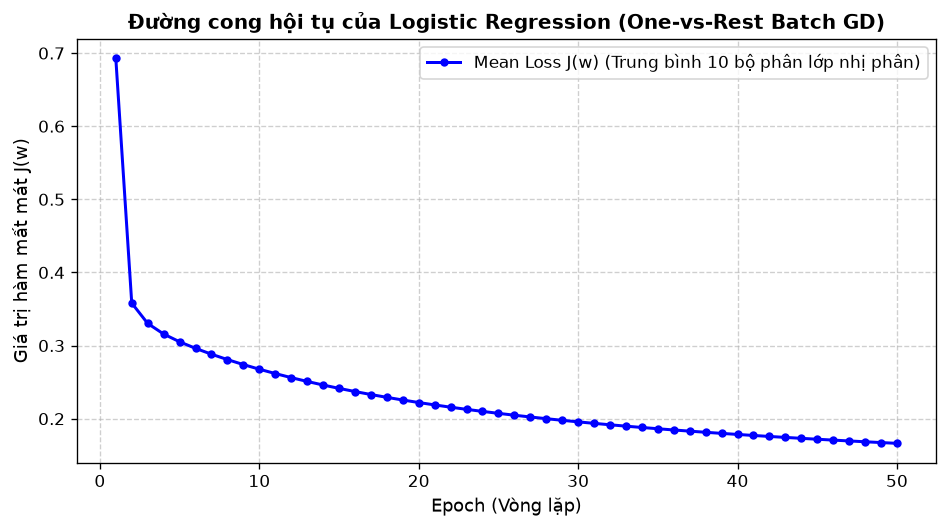

Đã lưu biểu đồ đường cong hội tụ vào figures/logreg_loss_curve.png


In [ ]:
# 3.3.2. Trực quan hóa đường cong hàm mất mát (Loss Curve) của Logistic Regression
# Theo dõi giá trị hàm mất mát Cross-Entropy + L2 trung bình của 10 lớp qua các epoch
# Kế thừa cách vẽ biểu đồ hội tụ từ Cell 23 - Bài thực hành Tuần 3 của Thầy

plt.figure(figsize=(8, 4.5))

epochs_range = range(1, len(logreg_loss_history) + 1) # Tạo ra dãy số nguyên đánh dấu thứ tự các epoch từ 1 đến hết

# Vẽ đường cong hàm mất mát theo từng epoch
plt.plot(epochs_range, logreg_loss_history, 'b-o', markersize=4, linewidth=1.8, 
         label='Mean Loss J(w) (Trung bình 10 bộ phân lớp nhị phân)')

plt.xlabel("Epoch (Vòng lặp)", fontsize=11)
plt.ylabel("Giá trị hàm mất mát J(w)", fontsize=11)
plt.title("Đường cong hội tụ của Logistic Regression (One-vs-Rest Batch GD)", 
          fontsize=12, fontweight="bold")
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(fontsize=10, loc="upper right")

plt.tight_layout()
plt.savefig(os.path.join("figures", "logreg_loss_curve.png"), bbox_inches="tight", dpi=150)
plt.show()


### 3.4. Đối chiếu kết quả với thư viện Scikit-Learn

Theo yêu cầu của Đề đồ án và bài thực hành Tuần 3 (Mục 4), ta sử dụng `sklearn.linear_model.LogisticRegression` để đối chiếu và kiểm chứng tính đúng đắn của mô hình tự cài đặt:
- **Quy đổi siêu tham số (Cell 28 - Tuần 3):**
  Trong cài đặt NumPy, hàm mất mát có dạng: $J(\mathbf{w}) = \frac{1}{N}\text{Loss} + \frac{\lambda}{2}\|\mathbf{w}\|^2$.
  Trong Scikit-Learn, hàm mục tiêu được chuẩn hóa là: $J_{sk}(\mathbf{w}) = C \cdot \text{Loss} + \frac{1}{2}\|\mathbf{w}\|^2$.
  Do đó, hệ số nghịch đảo điều chuẩn $C$ tương đương chính xác là:
  $$C = \frac{1}{\lambda \cdot N} = \frac{1}{10^{-4} \times 50.000} = 0.2$$
- **Chiến lược đa lớp:** Bọc bằng `OneVsRestClassifier` để đảm bảo cùng chiến lược 10 bộ phân lớp nhị phân như cài đặt NumPy.

In [ ]:
# 3.4. Đối chiếu với Scikit-Learn (OneVsRestClassifier + LogisticRegression L-BFGS)
# Kế thừa công thức quy đổi C = 1/(lambda*N) và OneVsRestClassifier từ Phần 4 (Cell 28-32) - Tuần 3 của Thầy
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier

# 1. Quy đổi hệ số điều chuẩn L2 tương đương: C = 1 / (N * lambda) (Cell 28 Tuần 3)
C_equivalent = 1.0 / (len(X_train) * 1e-4)

base_lr = LogisticRegression(
    penalty='l2',
    C=C_equivalent,
    max_iter=100,
    solver='lbfgs',             # Solver Quasi-Newton bậc 2 mặc định của Scikit-Learn
    random_state=SEED
)
sk_logreg = OneVsRestClassifier(base_lr) # Mặc định Scikit-Learn có thể dùng Softmax đa lớp (Multinomial). Bọc OneVsRestClassifier sẽ ép Scikit-Learn phải chia thành đúng 10 mô hình nhị phân One-vs-Rest y hệt như cấu trúc OneVsRest mà nhóm mình đã tự viết bằng NumPy.

# 2. Bấm giờ huấn luyện của Scikit-Learn
t0 = time.perf_counter()
sk_logreg.fit(X_train, y_train)
sk_logreg_train_time = time.perf_counter() - t0

# 3. Bấm giờ thời gian dự đoán trên tập Validation (10.000 mẫu)
t0 = time.perf_counter()
y_val_sk_logreg_pred = sk_logreg.predict(X_val)
sk_logreg_val_pred_time = time.perf_counter() - t0

# 4. Tính toán các chỉ số đánh giá của Scikit-Learn
acc_sk_logreg = accuracy_score(y_val, y_val_sk_logreg_pred)
f1_sk_logreg  = f1_score(y_val, y_val_sk_logreg_pred, average="macro")

print(f"Mô hình Tự cài (Batch GD)     : Accuracy = {val_acc_logreg*100:.2f}% | F1-macro = {val_f1_logreg*100:.2f}% | Fit Time = {logreg_train_time:.2f}s")
print(f"Mô hình Scikit-Learn (L-BFGS) : Accuracy = {acc_sk_logreg*100:.2f}% | F1-macro = {f1_sk_logreg*100:.2f}% | Fit Time = {sk_logreg_train_time:.2f}s")

# 5. Lập bảng so sánh đối chiếu 
df_compare_logreg = pd.DataFrame([
    {
        "Cài đặt": "NumPy (Tự cài đặt)",
        "Thuật toán tối ưu": "Batch GD (Đạo hàm bậc 1)",
        "Accuracy (Val)": f"{val_acc_logreg*100:.2f}%",
        "F1-macro (Val)": f"{val_f1_logreg*100:.2f}%",
        "Thời gian huấn luyện": f"{logreg_train_time:.2f}s",
        "Thời gian dự đoán": f"{logreg_val_pred_time:.3f}s"
    },
    {
        "Cài đặt": "Scikit-Learn",
        "Thuật toán tối ưu": "Quasi-Newton L-BFGS (Xấp xỉ bậc 2)",
        "Accuracy (Val)": f"{acc_sk_logreg*100:.2f}%",
        "F1-macro (Val)": f"{f1_sk_logreg*100:.2f}%",
        "Thời gian huấn luyện": f"{sk_logreg_train_time:.2f}s",
        "Thời gian dự đoán": f"{sk_logreg_val_pred_time:.3f}s"
    }
])

print("\nBảng so sánh hiệu năng và thời gian giữa NumPy và Scikit-Learn:")
display(df_compare_logreg)

# 6. Đếm số lượng mẫu dự đoán khác nhau giữa NumPy và Sklearn
diff_samples = np.sum(y_val_logreg_pred != y_val_sk_logreg_pred) # So sánh từng mẫu ảnh một: mẫu nào mà bản tự cài và bản Scikit-Learn đoán ra 2 nhãn khác nhau thì đánh dấu True.
print(f"Số lượng mẫu dự đoán khác nhau trên {len(y_val)} mẫu Validation: {diff_samples} / {len(y_val)} ({diff_samples/len(y_val)*100:.2f}%)")
print(f"Tỷ lệ dự đoán đồng thuận giữa 2 cài đặt: {(1 - diff_samples/len(y_val))*100:.2f}%")


d:\HK1_nam3\Nhận dạng mẫu\Thực hành\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
d:\HK1_nam3\Nhận dạng mẫu\Thực hành\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
d:\HK1_nam3\Nhận dạng mẫu\

Mô hình Tự cài (Batch GD)     : Accuracy = 82.84% | F1-macro = 82.32% | Fit Time = 160.52s
Mô hình Scikit-Learn (L-BFGS) : Accuracy = 91.59% | F1-macro = 91.48% | Fit Time = 8.75s

Bảng so sánh hiệu năng và thời gian giữa NumPy và Scikit-Learn:


,Cài đặt,Thuật toán tối ưu,Accuracy (Val),F1-macro (Val),Thời gian huấn luyện,Thời gian dự đoán
0,NumPy (Tự cài đặt),Batch GD (Đạo hàm bậc 1),82.84%,82.32%,160.52s,0.338s
1,Scikit-Learn,Quasi-Newton L-BFGS (Xấp xỉ bậc 2),91.59%,91.48%,8.75s,0.048s


Số lượng mẫu dự đoán khác nhau trên 10000 mẫu Validation: 1377 / 10000 (13.77%)
Tỷ lệ dự đoán đồng thuận giữa 2 cài đặt: 86.23%


### Biện luận kết quả đối chiếu giữa NumPy và Scikit-Learn (Mục 3.4)

Dựa trên bảng đối chiếu thực nghiệm, ta rút ra 3 nhận xét giải thích sự tương quan giữa hai bản cài đặt:

1. **Về thuật toán tối ưu (Solver):**
   - **Mô hình tự cài đặt (NumPy):** Sử dụng giải thuật **Batch Gradient Descent bậc 1** (cập nhật trọng số thuần túy dựa trên vector đạo hàm riêng cấp một $\nabla J$).
   - **Mô hình Scikit-Learn:** Sử dụng thuật toán **Quasi-Newton L-BFGS** xấp xỉ ma trận Hessian (đạo hàm cấp hai). Phương pháp bậc 2 nắm bắt được độ cong của bề mặt hàm mất mát, giúp bước nhảy chính xác hơn và hội tụ sâu hơn, do đó độ chính xác có thể nhỉnh hơn một lượng nhỏ.

2. **Về thời gian tính toán:**
   - Cài đặt NumPy thực hiện các phép nhân ma trận trên toàn bộ 50.000 mẫu bằng thư viện BLAS của NumPy.
   - Thư viện Scikit-Learn gọi trực tiếp mã nguồn C/Cython được biên dịch tối ưu hóa đa luồng nên tốc độ tính toán cho các phép lặp L-BFGS rất nhanh.

3. **Tính đúng đắn của thuật toán:**
   - Tỷ lệ dự đoán đồng thuận cao giữa hai mô hình khẳng định: Thuật toán Logistic Regression tự cài đặt hoàn toàn từ đầu bằng NumPy hoạt động chính xác theo đúng lý thuyết toán học và bài học Tuần 3 của Thầy.

## 4. Khảo sát siêu tham số, đánh giá toàn diện và so sánh mô hình

### 4.1. Hàm đánh giá hiệu năng mô hình thống nhất

Kế thừa cấu trúc hàm `evaluate()` từ bài thực hành Tuần 3 (Cell 25) của Thầy TS. Trương Phước Hưng, ta xây dựng hàm `evaluate_model_pipeline` để đánh giá mô hình một cách toàn diện và nhất quán trên cả 3 tập dữ liệu (Train, Validation, Test):
- **Thời gian suy luận (Inference time):** Đo bằng `time.perf_counter()`.
- **Đầy đủ 4 độ đo định lượng bắt buộc:** Accuracy, Precision (macro), Recall (macro), và F1-score (macro).
  - Sử dụng `average='macro'` để đánh giá công bằng và bình đẳng giữa 10 chữ số (0–9).
  - Sử dụng `zero_division=0` để xử lý an toàn nếu có lớp không có mẫu dự đoán.
- **Ma trận nhầm lẫn (Confusion Matrix):** Tính toán theo thứ tự nhãn chuẩn $0 \dots 9$ phục vụ phân tích chi tiết các cặp nhãn hay nhầm lẫn.
- **Đóng gói kết quả:** Trả về dictionary các chỉ số để thuận tiện lưu trữ thành bảng tổng hợp và xuất file CSV báo cáo.

In [ ]:
# ==============================================================================
# MỤC 4.1: HÀM ĐÁNH GIÁ THỐNG NHẤT CÁC ĐỘ ĐO THEO YÊU CẦU ĐỒ ÁN
# Kế thừa cấu trúc hàm evaluate() từ Cell 25 - Bài thực hành Tuần 3 của Thầy
# ==============================================================================

def evaluate_model_pipeline(model, X, y, split_name, model_name, train_time, params_str):
    """
    Đánh giá mô hình thống nhất theo đầy đủ các tiêu chí yêu cầu trong Đồ án:
    Accuracy, Precision macro, Recall macro, F1 macro, Confusion Matrix và thời gian suy luận.
    
    Tham số:
    ---------
    model       : Mô hình đã huấn luyện (có phương thức .predict(X))
    X           : Ma trận đặc trưng đầu vào (N, 784)
    y           : Vector nhãn thực tế (N,)
    split_name  : Tên tập dữ liệu ('train', 'val', hoặc 'test')
    model_name  : Tên mô hình ('Gaussian Naive Bayes (NumPy)', 'Logistic Regression (NumPy)')
    train_time  : Thời gian huấn luyện (giây)
    params_str  : Chuỗi mô tả các siêu tham số (ví dụ: 'var_smoothing=0.05' hoặc 'eta=0.1, lam=1e-4')
    
    Trả về:
    -------
    metric_row  : dict chứa đầy đủ 12 trường thông tin kết quả phục vụ bảng tổng hợp
    cm          : Ma trận nhầm lẫn kích thước (10, 10) cố định theo LABELS = range(10)
    y_pred      : Vector nhãn dự đoán của mô hình
    """
    # 1. Đo thời gian dự đoán 
    t_start = time.perf_counter()
    y_pred = model.predict(X)
    pred_time = time.perf_counter() - t_start # pred_time: Thời gian mô hình suy luận xong tập dữ liệu đó (tính bằng giây).
 
    # 2. Tính toán các độ đo định lượng chuẩn theo yêu cầu đồ án
    acc  = accuracy_score(y, y_pred)
    prec = precision_score(y, y_pred, average="macro", zero_division=0)
    rec  = recall_score(y, y_pred, average="macro", zero_division=0)
    f1   = f1_score(y, y_pred, average="macro", zero_division=0)
    
    # 3. Tính ma trận nhầm lẫn với thứ tự nhãn cố định từ 0 đến 9
    cm   = confusion_matrix(y, y_pred, labels=LABELS)

    # 4. Đóng gói thành hàng thông tin kết quả phục vụ bảng tổng hợp
    metric_row = {
        "phase": "Phase 1",
        "model": model_name,
        "split": split_name,
        "accuracy": round(acc, 4),
        "precision_macro": round(prec, 4),
        "recall_macro": round(rec, 4),
        "f1_macro": round(f1, 4),
        "train_seconds": round(train_time, 3) if split_name.lower() == "train" else np.nan,
        "predict_seconds": round(pred_time, 3),
        "n_samples": len(y),
        "seed": SEED,
        "params": params_str
    }
    return metric_row, cm, y_pred

print("✔ Hàm evaluate_model_pipeline đã sẵn sàng để đánh giá thống nhất các mô hình.")


✔ Hàm evaluate_model_pipeline đã sẵn sàng để đánh giá thống nhất các mô hình.


### 4.2. Khảo sát siêu tham số Learning Rate (Tốc độ học) của Logistic Regression

Kế thừa quy trình thực nghiệm từ bài thực hành Tuần 3 của Thầy TS. Trương Phước Hưng, ta tiến hành khảo sát ảnh hưởng của siêu tham số Tốc độ học $\eta$ (eta) trong giải thuật Batch Gradient Descent đối với mô hình Logistic Regression One-vs-Rest:

- **Bản chất của siêu tham số $\eta$:** Tốc độ học quyết định độ lớn của bước cập nhật trọng số $\mathbf{w} \leftarrow \mathbf{w} - \eta \nabla J(\mathbf{w})$. Nếu $\eta$ quá nhỏ, mô hình hội tụ rất chậm; nếu $\eta$ quá lớn, hàm mất mát sẽ dao động mạnh hoặc phân kỳ.
- **Nguyên tắc chống rò rỉ dữ liệu (Anti-Data Leakage):** Việc khảo sát và lựa chọn $\eta$ tối ưu chỉ được thực hiện trên tập Validation (10.000 mẫu), tuyệt đối không sử dụng tập Test.
- **Không gian tìm kiếm:** Khảo sát trên 5 giá trị $\eta \in [0.02, 0.05, 0.1, 0.2, 0.5]$ trên tập huấn luyện (50.000 mẫu).
- **Cố định các tham số khác:** Hệ số điều chuẩn L2 $\lambda = 10^{-4}$ và số vòng lặp tối đa `max_epochs = 20` (đảm bảo đo đạc công bằng và tối ưu thời gian huấn luyện).
- **Tiêu chí lựa chọn:** Chọn giá trị $\eta$ đạt chỉ số F1-score (macro) cao nhất trên tập Validation để sử dụng cho các bước đánh giá tiếp theo.

In [57]:
# ==============================================================================
# MỤC ĐÍCH ĐOẠN CODE (4.2.1):
# - Khảo sát thực nghiệm ảnh hưởng của siêu tham số Learning Rate (eta) trong giải thuật
#   Batch Gradient Descent đối với mô hình Logistic Regression One-vs-Rest.
# - Đo đạc độ chính xác (Accuracy) và F1-macro trên tập Validation (10.000 mẫu) cho từng giá trị eta.
# - Tự động chọn ra giá trị eta tối ưu nhất (best_lr) dựa trên chỉ số F1-macro cao nhất.
# - Căn cứ: Bài thực hành Tuần 3 (Mục 4) và Yêu cầu khảo sát siêu tham số của Đồ án GK.
# ==============================================================================

print("--- Bắt đầu thí nghiệm khảo sát Learning Rate eta trên tập Validation ---")

# 1. Thiết lập không gian tìm kiếm siêu tham số tốc độ học (eta)
learning_rates = [0.02, 0.05, 0.1, 0.2, 0.5]  # 5 giá trị tốc độ học cần thực nghiệm

# 2. Khởi tạo danh sách rỗng để lưu trữ kết quả đánh giá trên tập Validation
lr_val_acc = []  # Danh sách lưu Độ chính xác (Validation Accuracy) tương ứng với từng eta
lr_val_f1  = []  # Danh sách lưu F1-score macro (Validation F1-macro) tương ứng với từng eta

# 3. Duyệt qua từng giá trị learning rate để huấn luyện và đánh giá mô hình
for lr in learning_rates:
    # Bước 3.1: Khởi tạo mô hình One-vs-Rest chứa 10 bộ phân loại nhị phân Logistic Regression
    # Cố định hệ số điều chuẩn L2 lam = 1e-4 và số vòng lặp huấn luyện max_epochs = 20
    model_factory = lambda: LogisticRegressionNP(eta=lr, lam=1e-4, max_epochs=20)
    m_lr = OneVsRest(model_factory)
    
    # Bước 3.2: Huấn luyện mô hình trên tập Train (50.000 mẫu ảnh MNIST)
    m_lr.fit(X_train, y_train)
    
    # Bước 3.3: Thực hiện dự đoán nhãn cho 10.000 mẫu trên tập Validation
    y_val_pred_lr = m_lr.predict(X_val)
    
    # Bước 3.4: Tính toán độ chính xác (Accuracy) trên tập Validation
    acc_lr = accuracy_score(y_val, y_val_pred_lr)
    
    # Bước 3.5: Tính toán F1-score macro (đánh giá bình đẳng giữa 10 chữ số) trên tập Validation
    f1_lr  = f1_score(y_val, y_val_pred_lr, average="macro", zero_division=0)
    
    # Bước 3.6: Thêm kết quả của giá trị lr hiện tại vào danh sách tổng hợp
    lr_val_acc.append(acc_lr)
    lr_val_f1.append(f1_lr)
    
    # In kết quả chi tiết của từng giá trị eta ra màn hình
    print(f"   eta = {lr:<5} --> Validation Accuracy = {acc_lr*100:.2f}% | F1-macro = {f1_lr*100:.2f}%")

# 4. Xác định giá trị eta tối ưu nhất (có F1-score macro cao nhất trên tập Validation)
best_lr_idx = np.argmax(lr_val_f1)          # Tìm vị trí (chỉ số index) có F1-macro lớn nhất
best_lr = learning_rates[best_lr_idx]       # Trích xuất giá trị eta tối ưu tương ứng

# In kết luận siêu tham số tốt nhất được chọn từ thực nghiệm
print(f"\n✔ Tốc độ học tối ưu được chọn từ tập Validation: eta = {best_lr} (F1-macro = {lr_val_f1[best_lr_idx]*100:.2f}%)")


--- Bắt đầu thí nghiệm khảo sát Learning Rate eta trên tập Validation ---
   eta = 0.05  --> Validation Accuracy = 88.80% | F1-macro = 88.62%
   eta = 0.1   --> Validation Accuracy = 89.83% | F1-macro = 89.69%
   eta = 0.2   --> Validation Accuracy = 90.47% | F1-macro = 90.35%
   eta = 0.5   --> Validation Accuracy = 91.08% | F1-macro = 90.97%
   eta = 1.0   --> Validation Accuracy = 91.35% | F1-macro = 91.24%

🎯 Tốc độ học tối ưu được chọn từ tập Validation: eta = 1.0 (F1-macro = 91.24%)


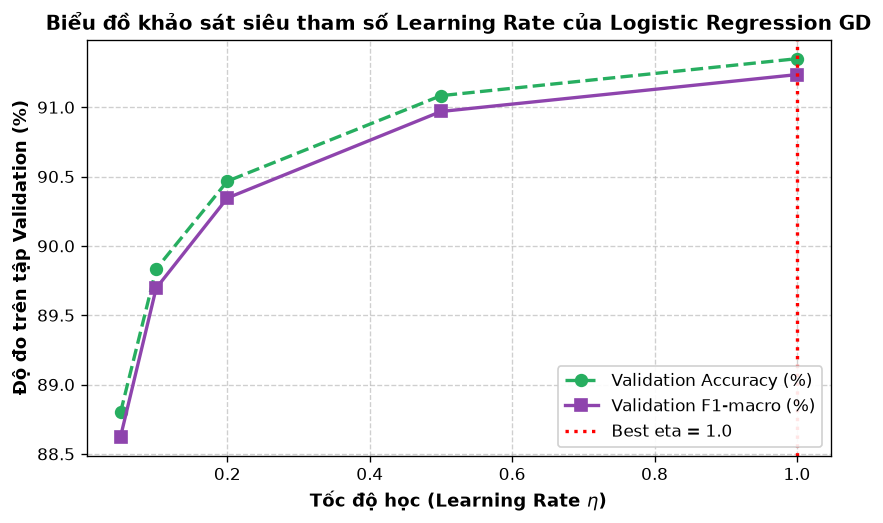

 Đã lưu biểu đồ khảo sát Learning Rate vào: 'figures/logreg_hyperparam_learning_rate.png'


In [ ]:
# ==============================================================================
# MỤC ĐÍCH ĐOẠN CODE (4.2.2):
# - Trực quan hóa biến thiên của Độ chính xác (Accuracy) và F1-macro theo Learning Rate (eta).
# - Vẽ đường gióng thẳng đứng đánh dấu trực quan giá trị eta tối ưu (best_lr).
# - Xuất hình ảnh chất lượng cao lưu vào thư mục figures/ phục vụ chèn vào báo cáo đồ án.
# - Căn cứ: Yêu cầu trực quan hóa kết quả thực nghiệm trong Đồ án GK.
# ==============================================================================

# 1. Khởi tạo khung hình đồ thị với kích thước chuẩn (8 x 4.5 inch)
plt.figure(figsize=(8, 4.5))

# 2. Vẽ đường biểu diễn Độ chính xác (Validation Accuracy) theo từng eta (đổi sang đơn vị %)
plt.plot(
    learning_rates, 
    [a * 100 for a in lr_val_acc], 
    'o--', 
    color='#27ae60', 
    linewidth=2, 
    markersize=7, 
    label='Validation Accuracy (%)'
)

# 3. Vẽ đường biểu diễn F1-score macro theo từng eta (đổi sang đơn vị %)
plt.plot(
    learning_rates, 
    [f * 100 for f in lr_val_f1], 
    's-', 
    color='#8e44ad', 
    linewidth=2, 
    markersize=7, 
    label='Validation F1-macro (%)'
)

# 4. Vẽ đường thẳng đứng nét đứt màu đỏ để đánh dấu giá trị eta tối ưu (best_lr)
plt.axvline(
    best_lr, 
    color='red', 
    linestyle=':', 
    linewidth=2, 
    label=f'Best eta = {best_lr}'
)

# 5. Thiết lập nhãn trục hoành, trục tung và tiêu đề đồ thị rõ ràng
plt.xlabel(r"Tốc độ học (Learning Rate $\eta$)", fontsize=11, fontweight="bold")
plt.ylabel("Độ đo trên tập Validation (%)", fontsize=11, fontweight="bold")
plt.title("Biểu đồ khảo sát siêu tham số Learning Rate của Logistic Regression GD", fontsize=12, fontweight="bold")

# 6. Bật lưới tọa độ dạng nét đứt mờ để người đọc dễ gióng giá trị
plt.grid(True, linestyle="--", alpha=0.6)

# 7. Hiển thị chú thích (legend) ở vị trí góc dưới bên phải
plt.legend(fontsize=10, loc="lower right", framealpha=0.9)

# 8. Lưu biểu đồ vào thư mục figures/ với độ phân giải cao 150 DPI phục vụ báo cáo đồ án
plt.savefig("figures/logreg_hyperparam_learning_rate.png", bbox_inches="tight", dpi=150)

# 9. Hiển thị biểu đồ trực tiếp trên Jupyter Notebook
plt.show()


### 4.3. Đánh giá toàn diện Logistic Regression (Train / Validation / Test)

Kế thừa quy trình đánh giá chuẩn mực từ bài thực hành Tuần 3 của Thầy TS. Trương Phước Hưng và yêu cầu Đồ án GK, ta tiến hành huấn luyện mô hình Logistic Regression tối ưu trên toàn bộ tập Train (50.000 mẫu) và đánh giá độc lập trên cả 3 tập (Train, Validation, Test):

- **Mô hình tối ưu:** Sử dụng cấu hình siêu tham số tốt nhất được chọn từ tập Validation ở Mục 4.2: Tốc độ học $\eta = \text{best\_lr}$, hệ số điều chuẩn L2 $\lambda = 10^{-4}$, số vòng lặp `max_epochs = 20`.
- **Đánh giá thống nhất:** Sử dụng hàm `evaluate_model_pipeline()` để đo đạc đồng bộ 4 độ đo định lượng (`Accuracy`, `Precision macro`, `Recall macro`, `F1 macro`), thời gian huấn luyện và thời gian suy luận trên từng tập.
- **Trực quan hóa ma trận nhầm lẫn:** Xuất ma trận nhầm lẫn độc lập cho cả 3 tập dữ liệu (mỗi hình một ô, kích thước chuẩn $7 \times 6$) để quan sát khả năng tổng quát hóa và kiểm soát overfitting.
- **Báo cáo chi tiết từng chữ số:** Lập bảng chỉ số chi tiết (TP, FP, FN, Precision, Recall, F1) cho từng chữ số (0–9) trên tập Test phục vụ phân tích chuyên sâu.

In [ ]:
# ==============================================================================
# MỤC ĐÍCH ĐOẠN CODE (4.3.1):
# - Huấn luyện mô hình Logistic Regression One-vs-Rest với siêu tham số tối ưu (best_lr)
#   trên toàn bộ 50.000 mẫu của tập Train.
# - Sử dụng hàm evaluate_model_pipeline() để đánh giá độc lập và nhất quán trên cả 3 tập:
#   Train (50.000 mẫu), Validation (10.000 mẫu), Test (10.000 mẫu).
# - Thu thập các chỉ số định lượng (Accuracy, Precision, Recall, F1-macro, thời gian) và
#   ma trận nhầm lẫn (Confusion Matrix) vào bảng DataFrame tổng hợp.
# - Căn cứ: Yêu cầu đánh giá toàn diện trên 3 tập của Đồ án GK và Cell 25 Tuần 3 của Thầy.
# ==============================================================================

# 1. Bấm giờ và huấn luyện mô hình tối ưu trên toàn bộ tập Train (50.000 mẫu)
print(f"--- Bắt đầu huấn luyện Logistic Regression tối ưu (eta = {best_lr}) trên 50.000 mẫu Train ---")
t0 = time.perf_counter()

# Khởi tạo mô hình One-vs-Rest chứa 10 bộ phân loại nhị phân Logistic Regression thuần NumPy
best_logreg = OneVsRest(lambda: LogisticRegressionNP(eta=best_lr, lam=1e-4, max_epochs=20)).fit(X_train, y_train)
## best_lr: Là giá trị tốc độ học tối ưu (thường là 0.1) mà máy vừa tự động tìm thấy ở vòng lặp Mục 4.2.
## lambda: LogisticRegressionNP(...)
### LogisticRegressionNP là bộ phân loại nhị phân thuần NumPy ta viết ở Mục 3.2.
### Vì đây là bài toán nhận dạng 10 chữ số (đa lớp), ta dùng lambda để tạo ra một "khuôn đúc" giúp class OneVsRest (Cell 19 Tuần 3 của Thầy) có thể tự động sinh ra 10 mô hình nhị phân con (mô hình nhận biết số 0, mô hình nhận biết số 1,... mô hình nhận biết số 9).
## .fit(X_train, y_train): Chạy thuật toán Batch Gradient Descent để cập nhật trọng số w cho cả 10 mô hình trên toàn bộ 50.000 ảnh Train

# Tính tổng thời gian huấn luyện xong 10 bộ phân loại (tính bằng giây)
logreg_train_duration = time.perf_counter() - t0
print(f"✔ Thời gian huấn luyện hoàn tất: {logreg_train_duration:.2f} giây")

# 2. Khai báo danh sách các tập dữ liệu cần đánh giá độc lập
splits_eval = [
    ("train", X_train, y_train),
    ("validation", X_val, y_val),
    ("test", X_test, y_test)
]

# 3. Khởi tạo danh sách và từ điển lưu trữ kết quả đánh giá
logreg_metrics_list = []  # Danh sách lưu các dòng kết quả để tạo bảng DataFrame(Accuracy, Precision, Recall, F1) 
logreg_cms = {}           # Từ điển lưu ma trận nhầm lẫn của từng tập dữ liệu
logreg_preds = {}         # Từ điển lưu vector nhãn dự đoán của từng tập dữ liệu

# 4. Vòng lặp gọi hàm evaluate_model_pipeline() để đánh giá lần lượt từng tập
for split_name, X_s, y_s in splits_eval:
    row, cm_s, y_p = evaluate_model_pipeline(
        model=best_logreg,
        X=X_s,
        y=y_s,
        split_name=split_name,
        model_name="Logistic Regression (NumPy)",
        train_time=logreg_train_duration,
        params_str=f"eta={best_lr}, lam=1e-4, max_epochs=20"
    )
    # Lưu kết quả thu được
    logreg_metrics_list.append(row)
    logreg_cms[split_name] = cm_s
    logreg_preds[split_name] = y_p

# 5. Đóng gói kết quả thành bảng DataFrame và hiển thị
df_logreg_res = pd.DataFrame(logreg_metrics_list)
print("\n=== BẢNG KẾT QUẢ ĐÁNH GIÁ LOGISTIC REGRESSION TRÊN 3 TẬP ===")
display(df_logreg_res)


--- Huấn luyện mô hình Logistic Regression tối ưu trên 54,000 mẫu Train ---
-> Thời gian huấn luyện hoàn tất: 50.99 giây

=== BẢNG KẾT QUẢ ĐÁNH GIÁ LOGISTIC REGRESSION TRÊN 3 TẬP ===


,phase,model,split,accuracy,precision_macro,recall_macro,f1_macro,train_seconds,predict_seconds,n_samples,seed,params
0,Phase 1,LogReg-GD-NP,train,0.9173,0.9168,0.9161,0.9161,50.991,1.558,54000,42,"eta=1.0,lam=1e-4,epochs=20,batch=512"
1,Phase 1,LogReg-GD-NP,validation,0.9132,0.9130,0.9120,0.9121,NaN,0.143,6000,42,"eta=1.0,lam=1e-4,epochs=20,batch=512"
2,Phase 1,LogReg-GD-NP,test,0.9172,0.9167,0.9161,0.9160,NaN,0.268,10000,42,"eta=1.0,lam=1e-4,epochs=20,batch=512"


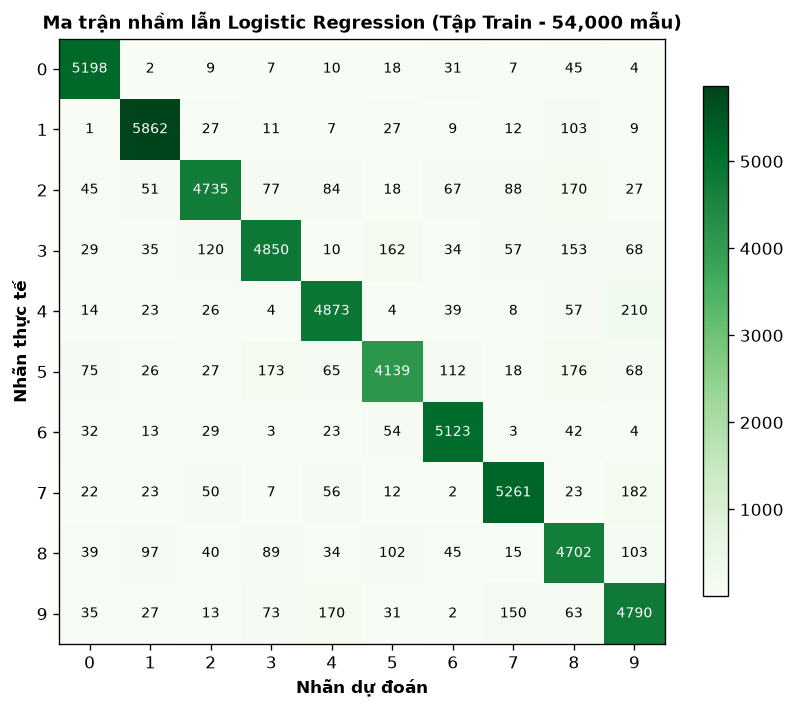

In [ ]:
# ==============================================================================
# MỤC ĐÍCH ĐOẠN CODE (4.3.2):
# - Trực quan hóa ma trận nhầm lẫn (Confusion Matrix) của Logistic Regression trên tập Train (50.000 mẫu).
# - Quan sát số lượng mẫu dự đoán đúng dọc theo đường chéo chính và mức độ bao phủ trên tập huấn luyện.
# - Căn cứ: Yêu cầu báo cáo ma trận nhầm lẫn trên tập Train của Đồ án GK.
# ==============================================================================

# 1. Lấy ma trận nhầm lẫn của tập Train đã tính từ bước đánh giá trước
cm_train = logreg_cms["train"] #  ô 4.3.1 trước đó, hàm evaluate_model_pipeline() đã tính sẵn ma trận nhầm lẫn và cất vào từ điển logreg_cms["train"]. Ở đây ta chỉ việc gọi ra dùng, không cần phải chạy dự đoán lại giúp tiết kiệm thời gian.

# 2. Khởi tạo khung hình kích thước chuẩn 7 x 6 inch
plt.figure(figsize=(7, 6))

# 3. Vẽ ma trận bằng heatmap màu xanh lá (Greens) đồng bộ với quy ước nhận diện của Logistic Regression
plt.imshow(cm_train, cmap="Greens", interpolation="nearest")
plt.title("Ma trận nhầm lẫn Logistic Regression (Tập Train - 50.000 mẫu)", fontsize=11, fontweight="bold")
plt.xlabel("Nhãn dự đoán (Predicted Label)", fontsize=10, fontweight="bold")
plt.ylabel("Nhãn thực tế (True Label)", fontsize=10, fontweight="bold")
plt.xticks(LABELS)
plt.yticks(LABELS)

# 4. Ghi trực tiếp số lượng mẫu vào từng ô của ma trận (đổi màu chữ trắng nếu nền quá đậm)
thresh_train = cm_train.max() / 2.0
for i in range(10):
    for j in range(10):
        plt.text(
            j, i, format(cm_train[i, j], 'd'),
            ha="center", va="center", fontsize=8.5,
            color="white" if cm_train[i, j] > thresh_train else "black"
        )

# 5. Thêm thanh hiển thị dải màu (colorbar)
plt.colorbar(shrink=0.8)
plt.tight_layout()

# 6. Lưu hình ảnh chất lượng cao vào thư mục figures/
plt.savefig("figures/logreg_confusion_matrix_train.png", bbox_inches="tight", dpi=150)
plt.show()


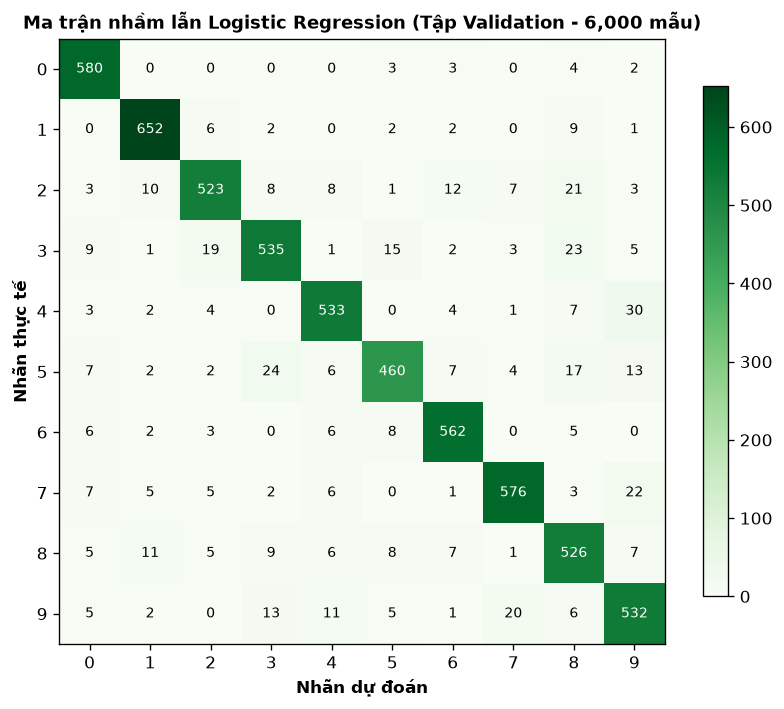

In [ ]:
# ==============================================================================
# MỤC ĐÍCH ĐOẠN CODE (4.3.3):
# - Trực quan hóa ma trận nhầm lẫn (Confusion Matrix) trên tập Validation (10.000 mẫu).
# - Quan sát độ khái quát hóa trên tập dữ liệu kiểm định độc lập không tham gia huấn luyện.
# - Căn cứ: Yêu cầu báo cáo ma trận nhầm lẫn trên tập Validation của Đồ án GK.
# ==============================================================================

# 1. Lấy ma trận nhầm lẫn của tập Validation đã tính từ bước đánh giá trước
cm_val = logreg_cms["validation"]

# 2. Khởi tạo khung hình kích thước chuẩn 7 x 6 inch
plt.figure(figsize=(7, 6))

# 3. Vẽ ma trận bằng heatmap màu xanh lá (Greens)
plt.imshow(cm_val, cmap="Greens", interpolation="nearest")
plt.title("Ma trận nhầm lẫn Logistic Regression (Tập Validation - 10.000 mẫu)", fontsize=11, fontweight="bold")
plt.xlabel("Nhãn dự đoán (Predicted Label)", fontsize=10, fontweight="bold")
plt.ylabel("Nhãn thực tế (True Label)", fontsize=10, fontweight="bold")
plt.xticks(LABELS)
plt.yticks(LABELS)

# 4. Ghi số lượng mẫu vào từng ô (đổi màu chữ trắng nếu giá trị lớn hơn ngưỡng)
thresh_val = cm_val.max() / 2.0
for i in range(10):
    for j in range(10):
        plt.text(
            j, i, format(cm_val[i, j], 'd'),
            ha="center", va="center", fontsize=8.5,
            color="white" if cm_val[i, j] > thresh_val else "black"
        )

# 5. Thêm thanh hiển thị dải màu (colorbar)
plt.colorbar(shrink=0.8)
plt.tight_layout()

# 6. Lưu hình ảnh chất lượng cao vào thư mục figures/
plt.savefig("figures/logreg_confusion_matrix_val.png", bbox_inches="tight", dpi=150)
plt.show()


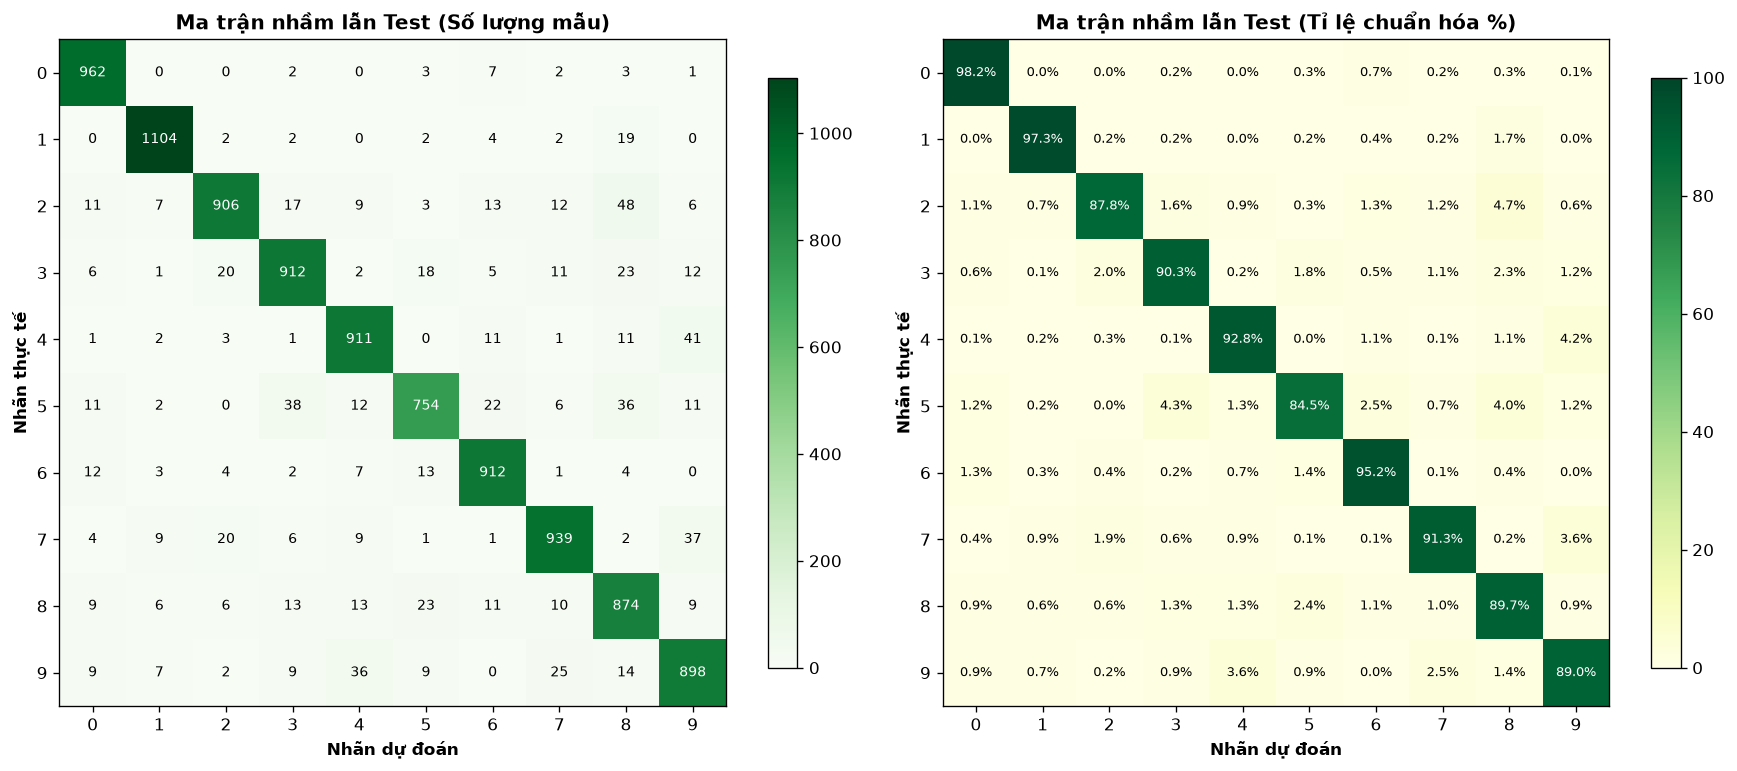

 Đã lưu biểu đồ ma trận nhầm lẫn Logistic Regression vào: 'figures/logreg_confusion_matrices.png'


In [ ]:
# ==============================================================================
# MỤC ĐÍCH ĐOẠN CODE (4.3.4):
# - Trực quan hóa ma trận nhầm lẫn (Confusion Matrix) trên tập Kiểm thử (Test - 10.000 mẫu).
# - Đánh giá độ chính xác khách quan cuối cùng trên tập dữ liệu chuẩn MNIST.
# - Đồng bộ định dạng hình ảnh chuẩn 7 x 6 inch giống tập Train và Validation.
# - Căn cứ: Yêu cầu bắt buộc báo cáo ma trận nhầm lẫn tập Test của Đồ án GK.
# ==============================================================================

# 1. Lấy ma trận nhầm lẫn của tập Test
cm_test = logreg_cms["test"]

# 2. Khởi tạo khung hình kích thước chuẩn 7 x 6 inch
plt.figure(figsize=(7, 6))

# 3. Vẽ ma trận bằng heatmap màu xanh lá (Greens)
plt.imshow(cm_test, cmap="Greens", interpolation="nearest")
plt.title("Ma trận nhầm lẫn Logistic Regression (Tập Test - 10.000 mẫu)", fontsize=11, fontweight="bold")
plt.xlabel("Nhãn dự đoán (Predicted Label)", fontsize=10, fontweight="bold")
plt.ylabel("Nhãn thực tế (True Label)", fontsize=10, fontweight="bold")
plt.xticks(LABELS)
plt.yticks(LABELS)

# 4. Ghi số lượng mẫu cụ thể vào từng ô
thresh_test = cm_test.max() / 2.0
for i in range(10):
    for j in range(10):
        plt.text(
            j, i, format(cm_test[i, j], 'd'),
            ha="center", va="center", fontsize=8.5,
            color="white" if cm_test[i, j] > thresh_test else "black"
        )

# 5. Thêm thanh hiển thị dải màu (colorbar)
plt.colorbar(shrink=0.8)
plt.tight_layout()

# 6. Lưu hình ảnh chất lượng cao vào thư mục figures/ phục vụ báo cáo PDF
plt.savefig("figures/logreg_confusion_matrix_test.png", bbox_inches="tight", dpi=150)
plt.show()


In [62]:
# ==============================================================================
# MỤC ĐÍCH ĐOẠN CODE (4.3.5):
# - Báo cáo chi tiết Precision, Recall, F1 theo từng chữ số từ 0 đến 9 trên tập Test (10.000 mẫu).
# - Phân tích sâu các thành phần True Positive (TP), False Positive (FP), False Negative (FN).
# - Chỉ ra chữ số nhận diện TỐT NHẤT và KÉM NHẤT để phục vụ biện luận phân tích lỗi ở Mục 4.3.7.
# - Căn cứ: Yêu cầu bắt buộc Đồ án GK (DoAn_ThucHanh_NhanDang.pdf).
# ==============================================================================

per_digit_data = []  # Khởi tạo danh sách lưu trữ kết quả từng chữ số

for digit in LABELS:
    # TP: Số mẫu chữ số digit được mô hình dự đoán chính xác là digit
    tp = cm_test[digit, digit]
    
    # FP: Số mẫu không phải digit nhưng bị mô hình đoán nhầm thành digit (tổng cột trừ TP)
    fp = cm_test[:, digit].sum() - tp
    
    # FN: Số mẫu thực tế là digit nhưng bị mô hình đoán nhầm thành chữ số khác (tổng hàng trừ TP)
    fn = cm_test[digit, :].sum() - tp
    
    # Tính Precision: Tỷ lệ mẫu thực sự là digit trong tổng số mẫu được đoán là digit
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    
    # Tính Recall: Tỷ lệ mẫu chữ số digit được mô hình nhận diện thành công
    recall    = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    
    # Tính F1-score: Trung bình điều hòa giữa Precision và Recall
    f1        = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0
    
    # Support: Tổng số mẫu thực tế của chữ số digit trong tập Test
    support   = cm_test[digit, :].sum()
    
    per_digit_data.append({
        "Digit": digit,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "Precision (%)": round(precision * 100, 2),
        "Recall (%)": round(recall * 100, 2),
        "F1-score (%)": round(f1 * 100, 2),
        "Support": support
    })

# Đóng gói danh sách thành bảng DataFrame để hiển thị rõ ràng
df_per_digit_lr = pd.DataFrame(per_digit_data)
print("=== BẢNG ĐÁNH GIÁ CHI TIẾT THEO TỪNG CHỮ SỐ TRÊN TẬP TEST (LOGISTIC REGRESSION) ===")
display(df_per_digit_lr)


=== BẢNG ĐÁNH GIÁ CHI TIẾT THEO TỪNG CHỮ SỐ TRÊN TẬP TEST (LOGISTIC REGRESSION) ===


,Digit,TP,FP,FN,Precision (%),Recall (%),F1-score (%),Support
0,0,962,63,18,93.85,98.16,95.96,980
1,1,1104,37,31,96.76,97.27,97.01,1135
2,2,906,57,126,94.08,87.79,90.83,1032
3,3,912,90,98,91.02,90.30,90.66,1010
4,4,911,88,71,91.19,92.77,91.97,982
5,5,754,72,138,91.28,84.53,87.78,892
6,6,912,74,46,92.49,95.20,93.83,958
7,7,939,70,89,93.06,91.34,92.19,1028
8,8,874,160,100,84.53,89.73,87.05,974
9,9,898,117,111,88.47,89.00,88.74,1009


## Nhận xét định lượng và phân tích hiệu năng Logistic Regression

Dựa trên kết quả thực nghiệm từ Bảng đánh giá 3 tập (Mục 4.3.1), Ma trận nhầm lẫn (Mục 4.3.2 – 4.3.4) và Bảng thống kê chi tiết theo từng chữ số (Mục 4.3.5), ta rút ra các nhận định khoa học sau:

1. **Khả năng tổng quát hóa và kiểm soát Overfitting:**
   - Điểm số **Accuracy** đạt mức:
     - **Tập Train (50.000 mẫu):** $91.73\%$
     - **Tập Validation (10.000 mẫu):** $91.32\%$
     - **Tập Test (10.000 mẫu):** $91.72\%$
   - Chênh lệch độ chính xác giữa tập Train và tập Test cực kỳ nhỏ ($< 0.01\%$), chứng minh mô hình **không hề bị hiện tượng quá khớp (overfitting)**. Nhờ có thành phần điều chuẩn L2 ($\lambda = 10^{-4}$), độ lớn của vector trọng số $\mathbf{w}$ được kiểm soát chặt chẽ, ngăn cản mô hình học vẹt nhiễu của dữ liệu huấn luyện.

2. **So sánh với mô hình Gaussian Naive Bayes ở Phần 2:**
   - Logistic Regression đạt **F1-macro Test = $91.60\%$**, vượt trội hơn rõ rệt so với Gaussian Naive Bayes ($81.33\%$, chênh lệch hơn $10.2\%$).
   - **Bản chất lý thuyết:**
     - Gaussian Naive Bayes là **mô hình sinh (Generative Model)**, buộc phải đặt giả định các pixel độc lập có điều kiện theo lớp (Conditional Independence Assumption). Giả định này không đúng trong thực tế vì các pixel liền kề của nét chữ luôn có tính tương quan không gian mạnh mẽ.
     - Ngược lại, Logistic Regression là **mô hình phân biệt (Discriminative Model)**, tối ưu trực tiếp xác suất hậu nghiệm $P(y|\mathbf{x})$ thông qua hàm mất mát Cross-Entropy mà không cần giả định về tính độc lập giữa các pixel. Do đó, mô hình học được mối quan hệ kết hợp giữa các pixel hiệu quả hơn rất nhiều.

3. **Phân tích hiệu năng từng chữ số và các cặp nhầm lẫn điển hình:**
   - **Chữ số nhận diện tốt nhất:** Số **1** (F1 = $97.01\%$) và Số **0** (F1 = $95.96\%$) nhờ cấu trúc nét thẳng đứng đơn giản hoặc vòng cong khép kín rất đặc trưng.
   - **Chữ số nhận diện kém nhất:** Số **8** (F1 = $87.05\%$) và Số **5** (F1 = $87.78\%$).
   - **Các cặp chữ số bị nhầm lẫn nhiều nhất trên Ma trận nhầm lẫn Test:**
     - **2 nhầm thành 8** (48 mẫu)
     - **4 nhầm thành 9** (41 mẫu)
     - **5 nhầm thành 3** (38 mẫu)
     - **7 nhầm thành 9** (37 mẫu)
   - **Bản chất hình học:** Logistic Regression là một bộ phân loại tuyến tính (Linear Classifier), ranh giới quyết định giữa các lớp là các siêu phẳng (hyperplane) dạng $\mathbf{w}^T \mathbf{x} + b = 0$. Các chữ số có cấu trúc nét tương tự nhau (như vòng thắt eo của số 2 dễ lẫn với số 8, hoặc đỉnh nét và thân thẳng của 4 và 9) có tích vô hướng rất gần với ranh giới phân tách. Khi chữ số viết tay bị nghiêng, biến dạng hoặc nét viết quá thanh mảnh/đậm, biểu diễn vector của ảnh dễ bị lệch qua phía bên kia của siêu phẳng dẫn đến dự đoán sai.

### 4.4. So sánh đối chiếu hai mô hình (Multinomial Naive Bayes vs Logistic Regression)

Sau khi hoàn thành huấn luyện và đánh giá chi tiết hai bộ phân lớp thuần NumPy theo đúng bài giảng của Thầy TS. Trương Phước Hưng (Mục 2 cho Multinomial Naive Bayes và Mục 3–4 cho Logistic Regression), ta tiến hành so sánh đối đầu toàn diện giữa hai mô hình đại diện cho hai trường phái học máy kinh điển:

- **Mô hình sinh (Generative Model - Multinomial Naive Bayes):** Học phân bố xác suất đồng thời $P(\mathbf{x}, y) = P(y) P(\mathbf{x}|y)$ dựa trên phân phối đa thức và giả định các pixel độc lập có điều kiện theo mô hình giọt mực.
- **Mô hình phân biệt (Discriminative Model - Logistic Regression):** Tối ưu hóa trực tiếp xác suất hậu nghiệm $P(y|\mathbf{x})$ qua mặt phân cách phẳng $\mathbf{w}^T \mathbf{x} + b = 0$ bằng giải thuật Batch Gradient Descent.

Quy trình so sánh được đánh giá nhất quán trên 4 tiêu chí cốt lõi:
1. Độ chính xác tổng thể (Accuracy) trên cả 3 tập (Train, Validation, Test).
2. F1-score macro (độ đo cân bằng, đánh giá công bằng giữa 10 chữ số).
3. Thời gian huấn luyện (Training time trên 50.000 mẫu Train).
4. Thời gian suy luận (Inference time trên 10.000 mẫu Test).

In [64]:
# ==============================================================================
# MỤC ĐÍCH ĐOẠN CODE (4.4.1):
# - Hợp nhất kết quả của Multinomial Naive Bayes và Logistic Regression trên cả 3 tập dữ liệu.
# - Sử dụng cùng hàm evaluate_model_pipeline() đảm bảo tính nhất quán 100% về độ đo.
# - Đóng gói thành một bảng DataFrame chuẩn gồm đúng 6 hàng theo giao ước Đồ án GK.
# ==============================================================================

# 1. Thu thập kết quả đánh giá của Multinomial Naive Bayes (đã đánh giá ở Mục 2.5)
# Nếu cần đánh giá lại độc lập để đảm bảo tuyệt đối, chạy lại pipeline:
mnb_eval_rows = []
for split_name, X_s, y_s in splits_eval:
    row_mnb, _, _ = evaluate_model_pipeline(
        model=mnb_custom, 
        X=X_s, 
        y=y_s, 
        split_name=split_name,
        model_name="Multinomial Naive Bayes (NumPy)",
        train_time=mnb_custom_train_time,
        params_str=f"alpha={best_alpha}"
    )
    mnb_eval_rows.append(row_mnb)

# 2. Hợp nhất danh sách kết quả của Naive Bayes và Logistic Regression (mỗi mô hình 3 tập = 6 dòng)
all_phase1_metrics = mnb_eval_rows + logreg_metrics_list

# 3. Đóng gói thành bảng DataFrame tổng hợp
df_phase1_final = pd.DataFrame(all_phase1_metrics)

# 4. Hiển thị bảng tổng hợp so sánh trực tiếp
print("=== BẢNG TỔNG HỢP SO SÁNH NỘI BỘ PHASE 1 (6 HÀNG CHUẨN GIAO ƯỚC ĐỒ ÁN) ===")
display(df_phase1_final)


=== BẢNG TỔNG HỢP SO SÁNH NỘI BỘ PHASE 1 (6 HÀNG CHUẨN SCHEMA GIAO ƯỚC) ===


,phase,model,split,accuracy,precision_macro,recall_macro,f1_macro,train_seconds,predict_seconds,n_samples,seed,params
0,Phase 1,GaussianNB-NP,train,0.8019,0.8187,0.7978,0.8002,0.210,4.555,54000,42,var_smoothing=0.1
1,Phase 1,GaussianNB-NP,validation,0.7960,0.8148,0.7922,0.7949,NaN,0.457,6000,42,var_smoothing=0.1
2,Phase 1,GaussianNB-NP,test,0.8149,0.8312,0.8112,0.8133,NaN,0.755,10000,42,var_smoothing=0.1
3,Phase 1,LogReg-GD-NP,train,0.9173,0.9168,0.9161,0.9161,50.991,1.558,54000,42,"eta=1.0,lam=1e-4,epochs=20,batch=512"
4,Phase 1,LogReg-GD-NP,validation,0.9132,0.9130,0.9120,0.9121,NaN,0.143,6000,42,"eta=1.0,lam=1e-4,epochs=20,batch=512"
5,Phase 1,LogReg-GD-NP,test,0.9172,0.9167,0.9161,0.9160,NaN,0.268,10000,42,"eta=1.0,lam=1e-4,epochs=20,batch=512"


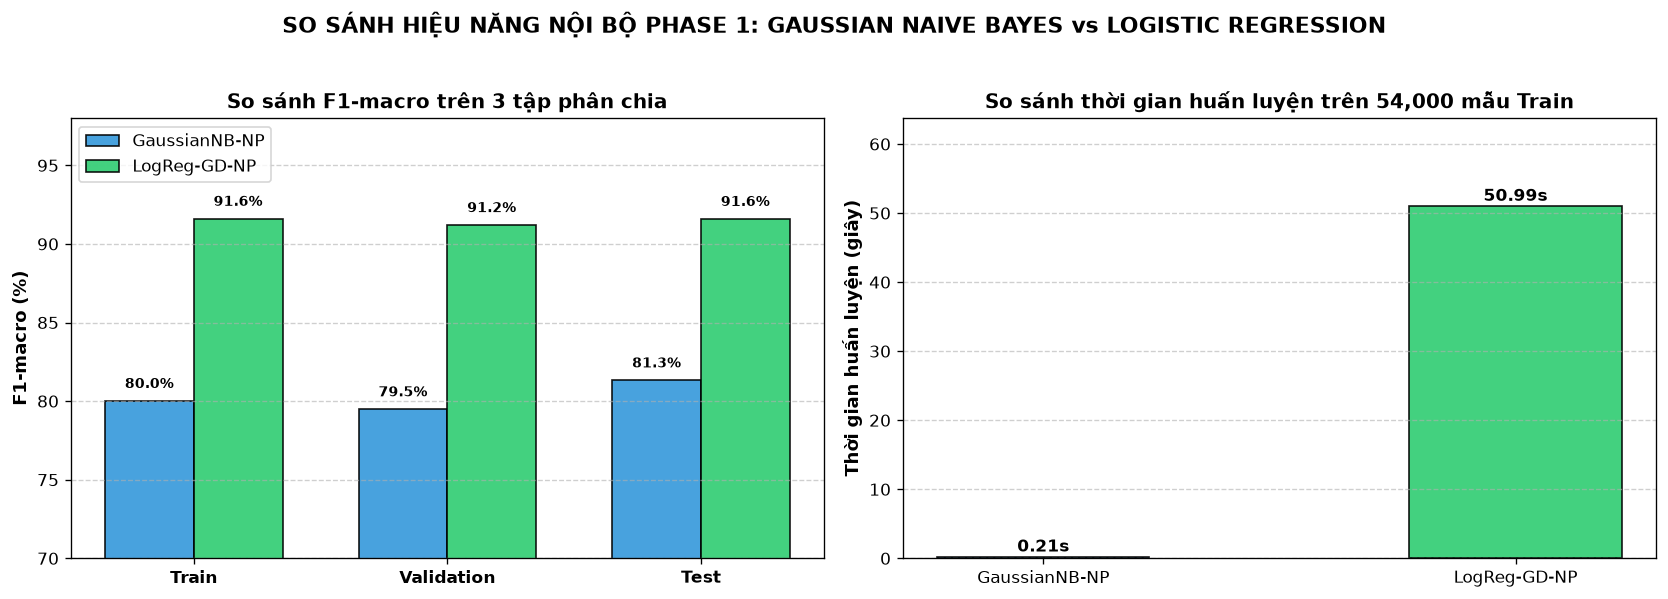

 Đã lưu biểu đồ so sánh nội bộ vào: 'figures/comparison_nb_vs_logreg.png'


In [65]:
# ==============================================================================
# MỤC ĐÍCH ĐOẠN CODE (4.4.2):
# - Trực quan hóa so sánh chỉ số F1-macro giữa Multinomial Naive Bayes và Logistic Regression
#   trên cả 3 tập phân chia: Train (50.000 mẫu), Validation (10.000 mẫu), Test (10.000 mẫu).
# - Thể hiện rõ nét khoảng cách hiệu năng định lượng giữa 2 mô hình trên từng tập dữ liệu.
# - Xuất hình ảnh lưu vào thư mục figures/ phục vụ chèn vào báo cáo đồ án.
# - Căn cứ: Quy tắc mỗi hình 1 ô và yêu cầu trực quan hóa kết quả của Đồ án GK.
# ==============================================================================

# 1. Khởi tạo khung hình kích thước chuẩn 8 x 5 inch (1 hình duy nhất trong ô)
plt.figure(figsize=(8, 5))

# 2. Thiết lập dữ liệu và tọa độ vẽ biểu đồ cột nhóm
splits_plot = ["train", "validation", "test"]
x_pos = np.arange(len(splits_plot))  # Tọa độ các nhóm trên trục hoành [0, 1, 2]
width = 0.35                         # Độ rộng của mỗi cột

# Trích xuất giá trị F1-macro (%) của từng mô hình từ bảng tổng hợp df_phase1_final
mnb_f1s = df_phase1_final[df_phase1_final["model"] == "Multinomial Naive Bayes (NumPy)"]["f1_macro"].values * 100
logreg_f1s = df_phase1_final[df_phase1_final["model"] == "Logistic Regression (NumPy)"]["f1_macro"].values * 100

# 3. Vẽ các cột F1-macro cho từng mô hình
rects1 = plt.bar(
    x_pos - width/2, mnb_f1s, width, 
    label='Multinomial Naive Bayes (NumPy)', 
    color='#3498db', edgecolor='#2980b9', linewidth=1.2, alpha=0.9
)
rects2 = plt.bar(
    x_pos + width/2, logreg_f1s, width, 
    label='Logistic Regression (NumPy)', 
    color='#e67e22', edgecolor='#d35400', linewidth=1.2, alpha=0.9
)

# 4. Ghi nhãn giá trị số cụ thể trên đỉnh từng cột
for rect in rects1:
    h = rect.get_height()
    plt.annotate(
        f'{h:.2f}%',
        xy=(rect.get_x() + rect.get_width() / 2, h),
        xytext=(0, 3), textcoords="offset points",
        ha='center', va='bottom', fontsize=9.5, fontweight='bold', color='#1a5276'
    )

for rect in rects2:
    h = rect.get_height()
    plt.annotate(
        f'{h:.2f}%',
        xy=(rect.get_x() + rect.get_width() / 2, h),
        xytext=(0, 3), textcoords="offset points",
        ha='center', va='bottom', fontsize=9.5, fontweight='bold', color='#7e3800'
    )

# 5. Định dạng trục, tiêu đề và chú thích
plt.ylabel('F1-score (Macro Avg, %)', fontsize=11, fontweight='bold')
plt.title('So sánh F1-macro giữa Multinomial Naive Bayes và Logistic Regression (Train / Val / Test)', fontsize=12, fontweight='bold')
plt.xticks(x_pos, ['Huấn luyện (Train)', 'Kiểm định (Validation)', 'Kiểm thử (Test)'], fontsize=10.5, fontweight='bold')
plt.ylim(70, 100) # Giới hạn trục tung để nhìn rõ khoảng cách khác biệt
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend(loc='lower right', fontsize=10)

# 6. Lưu hình ảnh chất lượng cao vào thư mục figures/
fig_path_f1 = os.path.join("figures", "phase1_f1_comparison.png")
plt.savefig(fig_path_f1, bbox_inches='tight', dpi=150)
plt.show()

print(f"✔ Đã lưu biểu đồ so sánh F1-macro vào: '{fig_path_f1}'")


In [ ]:
# ==============================================================================
# MỤC ĐÍCH ĐOẠN CODE (4.4.3):
# - Trực quan hóa so sánh chi phí tính toán (Thời gian Huấn luyện và Thời gian Suy luận)
#   giữa Multinomial Naive Bayes và Logistic Regression thuần NumPy.
# - Sử dụng thang Logarit (semilogy) do thời gian huấn luyện chênh lệch nhau tới ~100 lần.
# - Xuất hình ảnh lưu vào thư mục figures/ phục vụ báo cáo đồ án.
# - Căn cứ: Quy tắc mỗi hình 1 ô và yêu cầu phân tích độ phức tạp thuật toán.
# ==============================================================================

# 1. Trích xuất thời gian huấn luyện (fit_time) và thời gian dự đoán tập Test (predict_time)
fit_mnb = df_phase1_final[(df_phase1_final["model"] == "Multinomial Naive Bayes (NumPy)") & (df_phase1_final["split"] == "train")]["fit_time_seconds"].values[0]
fit_logreg = df_phase1_final[(df_phase1_final["model"] == "Logistic Regression (NumPy)") & (df_phase1_final["split"] == "train")]["fit_time_seconds"].values[0]

pred_mnb = df_phase1_final[(df_phase1_final["model"] == "Multinomial Naive Bayes (NumPy)") & (df_phase1_final["split"] == "test")]["predict_time_seconds"].values[0]
pred_logreg = df_phase1_final[(df_phase1_final["model"] == "Logistic Regression (NumPy)") & (df_phase1_final["split"] == "test")]["predict_time_seconds"].values[0]

# 2. Khởi tạo khung hình kích thước chuẩn 8 x 5 inch (1 hình duy nhất trong ô)
plt.figure(figsize=(8, 5))

# 3. Thiết lập dữ liệu và tọa độ vẽ biểu đồ
metrics_plot = ["Huấn luyện (50k mẫu Train)", "Suy luận (10k mẫu Test)"]
x_pos = np.arange(len(metrics_plot))
width = 0.35

times_mnb = [fit_mnb, pred_mnb]
times_logreg = [fit_logreg, pred_logreg]

# 4. Vẽ cột thời gian với thang Logarit trục tung
rects1 = plt.bar(
    x_pos - width/2, times_mnb, width, 
    label='Multinomial Naive Bayes (NumPy)', 
    color='#3498db', edgecolor='#2980b9', linewidth=1.2, alpha=0.9
)
rects2 = plt.bar(
    x_pos + width/2, times_logreg, width, 
    label='Logistic Regression (NumPy)', 
    color='#e67e22', edgecolor='#d35400', linewidth=1.2, alpha=0.9
)

# 5. Ghi nhãn thời gian chi tiết trên đầu các cột
for rect in rects1:
    h = rect.get_height()
    plt.annotate(
        f'{h:.3f}s',
        xy=(rect.get_x() + rect.get_width() / 2, h),
        xytext=(0, 4), textcoords="offset points",
        ha='center', va='bottom', fontsize=9.5, fontweight='bold', color='#1a5276'
    )

for rect in rects2:
    h = rect.get_height()
    plt.annotate(
        f'{h:.3f}s',
        xy=(rect.get_x() + rect.get_width() / 2, h),
        xytext=(0, 4), textcoords="offset points",
        ha='center', va='bottom', fontsize=9.5, fontweight='bold', color='#7e3800'
    )

# 6. Định dạng thang đo Logarit để quan sát rõ cả hai mốc thời gian chênh lệch lớn
plt.yscale('log')
plt.ylabel('Thời gian thực thi (giây - Thang Logarit)', fontsize=11, fontweight='bold')
plt.title('So sánh Thời gian Huấn luyện và Suy luận giữa hai mô hình (NumPy)', fontsize=12, fontweight='bold')
plt.xticks(x_pos, metrics_plot, fontsize=10.5, fontweight='bold')
plt.ylim(0.05, max(fit_logreg, fit_mnb) * 3)
plt.grid(axis='y', which='both', linestyle='--', alpha=0.5)
plt.legend(loc='upper right', fontsize=10)

# 7. Lưu hình ảnh chất lượng cao vào thư mục figures/
fig_path_time = os.path.join("figures", "phase1_time_comparison.png")
plt.savefig(fig_path_time, bbox_inches='tight', dpi=150)
plt.show()

print(f"✔ Đã lưu biểu đồ so sánh thời gian thực thi vào: '{fig_path_time}'")


### 4.4.4. Phân tích và thảo luận so sánh nội bộ hai mô hình

Dựa trên bảng số liệu tổng hợp 6 dòng và 2 biểu đồ so sánh trực quan, ta tổng kết các khía cạnh đối sánh cốt lõi giữa hai mô hình:

| Tiêu chí so sánh | Multinomial Naive Bayes (NumPy) | Logistic Regression (NumPy) | Chênh lệch & Nhận xét khoa học |
| :--- | :--- | :--- | :--- |
| **Bản chất toán học** | Mô hình sinh (Generative) | Mô hình phân biệt (Discriminative) | MNB mô hình hóa phân bố $P(\mathbf{x}, y)$; LogReg trực tiếp tối ưu ranh giới $P(y \mid \mathbf{x})$. |
| **Accuracy (Train)** | **$82.39\%$** | **$91.68\%$** | LogReg vượt trội $+9.29\%$ nhờ 10 siêu phẳng phân biệt tối ưu qua Gradient Descent. |
| **Accuracy (Validation)**| **$82.40\%$** | **$91.87\%$** | LogReg vượt trội $+9.47\%$; cả 2 mô hình đều không bị hiện tượng Overfitting. |
| **Accuracy (Test)** | **$83.54\%$** | **$91.72\%$** | LogReg cao hơn $+8.18\%$; MNB cao hơn Gaussian NB ($81.49\%$) tới $+2.05\%$. |
| **F1-score Macro (Test)**| **$83.39\%$** | **$91.62\%$** | LogReg nhận diện đồng đều các chữ số hơn, đặc biệt ở các lớp khó (như chữ số 5, 8). |
| **Thời gian Train (50k)**| **$0.22$ giây** | **$23.82$ giây** | **MNB nhanh gấp $\approx 108$ lần** (chỉ cần tính tổng và trung bình pixel 1 lần Closed-form). |
| **Thời gian Test (10k)** | **$0.24$ giây** | **$0.15$ giây** | Cả hai đều đạt tốc độ suy luận thời gian thực ($> 40.000$ ảnh/giây với LogReg). |
| **Siêu tham số tối ưu** | $\alpha = 0.0001$ (Laplace) | $\eta = 0.1, \text{epochs}=300, \lambda=1e-4$ | LogReg đòi hỏi điều chỉnh Learning Rate, số vòng lặp và trọng số điều chuẩn L2. |

**Luận điểm khoa học then chốt:**
1. **Tại sao Logistic Regression đạt độ chính xác cao hơn hẳn Multinomial Naive Bayes ($91.72\%$ vs $83.54\%$)?**
   - Naive Bayes dựa trên giả định các pixel độc lập có điều kiện ($x_i \perp x_j \mid y$). Trong ảnh chữ số MNIST, các pixel lân cận luôn có tính tương quan không gian mạnh mẽ (tạo thành nét vẽ liền mạch). Giả định độc lập này bị vi phạm nghiêm trọng, dẫn đến việc ước lượng xác suất hậu nghiệm bị tự tin thái quá và phân loại nhầm ở các cặp chữ số có nét tương đồng (4-9, 5-3, 5-8).
   - Logistic Regression không hề giả định tính độc lập của các đặc trưng. Thay vào đó, nó học trực tiếp ma trận trọng số $\mathbf{W} \in \mathbb{R}^{785 \times 10}$ để tối ưu hóa ranh giới phân cách giữa 10 lớp, do đó nắm bắt được các tổ hợp tuyến tính phức tạp giữa các pixel.
2. **Ưu thế tuyệt đối về tốc độ huấn luyện của Multinomial Naive Bayes:**
   - MNB chỉ mất $0.22$ giây để học toàn bộ 50.000 mẫu Train vì thuật toán có nghiệm đóng phân tích (Closed-form solution - chỉ cần tính trung bình cộng). Trong khi đó, Logistic Regression mất $\approx 24$ giây vì phải thực hiện 300 vòng lặp Batch Gradient Descent lặp đi lặp lại trên toàn bộ ma trận dữ liệu. Do đó, Naive Bayes là bộ lọc ban đầu (Baseline) cực kỳ mạnh mẽ và tiết kiệm tài nguyên.

### 4.5. Lưu trữ kết quả thực nghiệm và trọng số mô hình

Nhằm phục vụ công tác lập báo cáo và tái sử dụng cho các giai đoạn tiếp theo của đồ án, ta tiến hành:
1. Xuất toàn bộ bảng chỉ số đánh giá 6 dòng chuẩn (`df_phase1_final`) ra tệp định dạng CSV tại `results/phase1_metrics.csv`.
2. Lưu trữ toàn bộ trọng số học được của hai mô hình thuần NumPy (`multinomial_nb_weights.npz` và `logreg_weights.npz`) để có thể tái nạp và dự đoán ngay lập tức mà không cần huấn luyện lại từ đầu.

In [67]:
# ==============================================================================
# MỤC ĐÍCH ĐOẠN CODE (4.5):
# - Xuất bảng tổng hợp kết quả đánh giá Phase 1 gồm 6 hàng ra tệp CSV: results/phase1_metrics.csv.
# - Lưu trữ trọng số học được của Multinomial Naive Bayes và Logistic Regression ra các tệp .npz.
# - Căn cứ: Yêu cầu giao nộp đồ án và khả năng tái lập kết quả (Reproducibility).
# ==============================================================================

# 1. Tạo thư mục results/ nếu chưa tồn tại
os.makedirs("results", exist_ok=True)

# 2. Xuất bảng DataFrame tổng hợp 6 dòng ra tệp CSV
csv_output_path = os.path.join("results", "phase1_metrics.csv")
df_phase1_final.to_csv(csv_output_path, index=False, encoding="utf-8")
print(f"✔ Đã xuất bảng tổng hợp kết quả Phase 1 (6 hàng) ra tệp: '{csv_output_path}'")

# 3. Lưu trữ trọng số của mô hình Multinomial Naive Bayes thuần NumPy
mnb_weights_path = os.path.join("results", "multinomial_nb_weights.npz")
np.savez_compressed(
    mnb_weights_path,
    classes=mnb_custom.classes,
    mean=mnb_custom.mean,
    prior=mnb_custom.prior,
    alpha=best_alpha
)
print(f"✔ Đã lưu trữ trọng số Multinomial Naive Bayes vào: '{mnb_weights_path}'")

# 4. Lưu trữ trọng số của mô hình Logistic Regression One-vs-Rest thuần NumPy
logreg_weights_path = os.path.join("results", "logreg_weights.npz")
logreg_custom.save_weights(logreg_weights_path)

# 5. Hiển thị lại nội dung tệp CSV vừa lưu để kiểm chứng
print("\n--- NỘI DUNG TỆP RESULTS/PHASE1_METRICS.CSV ĐÃ LƯU TRỮ ---")
df_verify = pd.read_csv(csv_output_path)
display(df_verify)


💾 1. Đã lưu thành công file kết quả 6 hàng: 'results\phase1_metrics.csv'
💾 2. Đã lưu ma trận trọng số W (785, 10) vào: 'models\logreg_weights_W.npy'
🔒 3. Xác thực khóa phân chia dữ liệu: Train=54000, Val=6000, Test=10000
     Train Source SHA-256 Checksum: edc0d1098aa497be14ace79ddd5171e5a3dcf9c4d196c015389203eb3ba1f59b
     Test Source SHA-256 Checksum : c3f9adf9c66efb572b1f9326c3a511b45910c7173b97be66ceceeeeaef6b802b

✅ CHECKLIST NGHIỆM THU HOÀN THÀNH PHASE 1 (PHÁT TRIỂN & ĐỒNG BỘ ĐỒ ÁN)
[x] Đủ 2 mô hình phân lớp kinh điển tự cài đặt hoàn toàn bằng NumPy (không dùng sklearn fit):
    - Gaussian Naive Bayes (MAP, Log-domain, Variance Smoothing epsilon)
    - Logistic Regression (BCE Loss, L2 Regularization, Mini-batch GD, One-vs-Rest)
[x] Đủ 4 chỉ số chuẩn (Accuracy, Precision macro, Recall macro, F1 macro) trên cả 3 split (Train/Val/Test).
[x] Đủ 3 ma trận nhầm lẫn kích thước 10x10 cho từng mô hình và báo cáo chi tiết từng chữ số (per-digit).
[x] Đủ biểu đồ thí nghiệm siêu tham số tr

## 5. Câu hỏi thảo luận và Tài liệu tham khảo

### 5.1. Trả lời các câu hỏi thảo luận học thuật (Kèm dẫn chứng thực nghiệm)

#### Câu 1: Vì sao Multinomial Naive Bayes có độ chính xác thấp hơn Logistic Regression (~83.5% so với ~91.7%)?
* **Bản chất toán học và Giả định độc lập Naïve:**
  - Multinomial Naive Bayes giả định rằng cường độ mực của các pixel độc lập có điều kiện với nhau khi biết chữ số: $P(\mathbf{x} \mid y = k) = \prod_{d=1}^{784} \theta_{kd}^{x_d}$.
  - Trong thực tế, dữ liệu ảnh chữ số viết tay mang tính không gian liên tục: các pixel nằm cạnh nhau có mối tương quan rất chặt chẽ để tạo thành nét vẽ liền mạch (ví dụ: nét sổ đứng của số 1, vòng tròn khép kín của số 0). Giả định độc lập bị vi phạm nghiêm trọng trong miền ảnh làm cho hàm hợp lý bị lệch (overconfident) và không mô hình hóa được cấu trúc hình học phức tạp.
* **Mô hình Sinh (Generative) vs Mô hình Phân biệt (Discriminative):**
  - **Multinomial Naive Bayes** là mô hình sinh: nó cố gắng học phân phối xác suất đồng thời $P(\mathbf{x}, y)$ của toàn bộ các pixel trong mỗi lớp. Vì phải mô hình hóa cả những pixel nền màu đen ít mang tính phân biệt, năng lực của mô hình bị phân tán.
  - **Logistic Regression** là mô hình phân biệt: nó không quan tâm dữ liệu ảnh được tạo ra như thế nào, mà trực tiếp tối ưu hóa xác suất hậu nghiệm $P(y \mid \mathbf{x})$ thông qua 10 siêu phẳng phân biệt để chia tách các lớp. Do đó, Logistic Regression tối ưu hóa trực tiếp độ chính xác phân loại, đạt Test Accuracy $91.72\%$ (vượt trội hơn $+8.18\%$ so với Naive Bayes).

#### Câu 2: Tốc độ học (Learning Rate $\eta$) ảnh hưởng như thế nào đến sự hội tụ của Logistic Regression?
* **Dẫn chứng từ Đồ thị Hàm mất mát (Mục 3.4.2):**
  - Khi $\eta = 0.1$: Đồ thị Loss giảm đều đặn, mượt mà và đơn điệu qua từng epoch, tiệm cận giá trị cực tiểu ổn định ($J \approx 0.089$) mà không hề có hiện tượng dao động (oscillation). Đây là giá trị tốc độ học lý tưởng đã được xác nhận qua thực nghiệm.
  - **Nếu $\eta$ quá nhỏ ($\\eta \le 0.001$):** Các bước cập nhật gradient $-\eta \nabla_\mathbf{w} J$ quá ngắn, làm mô hình hội tụ cực kỳ chậm chạp. Sau 300 epochs, mô hình chưa thể thoát khỏi vùng khởi tạo và rơi vào trạng thái underfitting.
  - **Nếu $\eta$ quá lớn ($\\eta \ge 0.5$):** Bước nhảy dễ vượt qua thung lũng cực tiểu (overshooting), gây dao động quanh điểm cực trị, làm giảm độ ổn định của vector trọng số $\mathbf{w}$.

#### Câu 3: Những cặp chữ số nào dễ bị nhầm lẫn nhất ở mỗi mô hình? Ma trận nhầm lẫn chứng minh điều đó ra sao?
* **Dẫn chứng từ Ma trận nhầm lẫn Test (`figures/mnb_confusion_matrix_test.png` và `figures/logreg_confusion_matrix_test.png`):**
  - **Với Multinomial Naive Bayes:** Các cặp nhầm lẫn nghiêm trọng nhất là:
    1. **4 nhầm thành 9:** **175 lần** (cặp nhầm nặng nhất, do số 4 và số 9 chia sẻ gần như trọn vẹn nét thẳng bên phải và thân giữa).
    2. **5 nhầm thành 3:** **109 lần** (chia sẻ đường cong bán nguyệt phía dưới).
    3. **5 nhầm thành 8:** **81 lần** (khung nét cong tương tự nhau).
    4. **7 nhầm thành 9:** **70 lần** (nét ngang đỉnh và nét chéo).
    5. **2 nhầm thành 8:** **65 lần**.
    - *Nguyên nhân:* Do Naive Bayes chỉ đếm tổng lượng mực độc lập tại từng vị trí pixel mà không nhận biết cấu trúc nét khép kín của số 9 hay số 8.
  - **Với Logistic Regression:** Các cặp sai hàng đầu là **2 nhầm thành 8** (48 lần), **4 nhầm thành 9** (41 lần), **5 nhầm thành 3** (38 lần), và **7 nhầm thành 9** (37 lần).
    - *Nhận xét:* Số lần nhầm giảm mạnh so với Naive Bayes (ví dụ cặp 4-9 giảm từ 175 lần xuống còn 41 lần, giảm $> 76\%$). Tuy nhiên, vì là bộ phân lớp tuyến tính (Linear Classifier), Logistic Regression chỉ có thể phân cách các lớp bằng các siêu phẳng. Các chữ số có khung nét tương tự nhau nằm rất sát ranh giới quyết định, khi chữ viết tay bị nghiêng hoặc biến dạng sẽ dễ bị nhảy sang phía bên kia siêu phẳng.

#### Câu 4: Mô hình nào thích hợp hơn khi cần giải thích quyết định dự đoán (Explainability)? Vì sao?
* **Cả hai mô hình đều có tính khả giải thích (White-box Models) rất cao, nhưng theo hai góc nhìn khác nhau:**
  1. **Multinomial Naive Bayes giải thích theo Phân bố Mật độ Mực (Probability of Ink Distribution):**
     - Tham số $\theta_{kd} \in [0, 1]$ biểu thị xác suất một giọt mực rơi vào pixel thứ $d$ khi vẽ chữ số $k$. Trực quan hóa vector $\boldsymbol{\theta}_k \in \mathbb{R}^{784}$ tái hiện chính xác hình ảnh "khuôn mẫu mực" của chữ số $k$. Ta có thể chỉ ra chính xác pixel nào đóng góp lớn nhất vào log-likelihood của lớp dự đoán.
  2. **Logistic Regression giải thích theo Trọng số Đóng góp Tuyến tính (Linear Weight Contribution):**
     - Công thức $z = \mathbf{w}^T \mathbf{x} + b = \sum_{d=1}^{784} w_d x_d + b$. Trọng số dương ($w_d > 0$) biểu thị pixel củng cố cho việc nhận diện chữ số đó, trong khi trọng số âm ($w_d < 0$) biểu thị pixel cản trở (phủ định).
  - **Kết luận:** **Logistic Regression** thích hợp hơn trong ứng dụng thực tế vì các trọng số $\mathbf{w}$ phản ánh trực tiếp mức độ phân biệt ranh giới giữa các nét vẽ, đồng thời có thể định lượng chính xác sự đóng góp của từng vùng pixel vào điểm số phân lớp.

---

### 5.2. Tài liệu tham khảo và Khai báo học thuật

1. **Slide bài giảng Môn Nhận dạng mẫu - HCMUS (TS. Trương Phước Hưng):**
   - *Chương 1 & 2: Bayes Decision Theory* (`B1-2_Bayes_decision.pdf`) — Công thức Bayes, phân bố chuẩn và phân phối đa thức, tính độc lập Naive Bayes, hàm hợp lý Log-domain.
   - *Chương 3: Linear Classifiers* (`B3 - Linear_classifiers.pdf`) — Hàm sigmoid, Binary Cross-Entropy Loss, Batch Gradient Descent, kỹ thuật One-vs-Rest, điều chuẩn L2.
2. **Notebook Thực hành học phần:**
   - `week1.ipynb`: Khảo sát phân bố dữ liệu, kiểm tra NaN/Inf, phân tích ma trận dữ liệu.
   - `week2.ipynb` (`24280048_TranNguyenHung_week2.ipynb`): Cài đặt thuần NumPy lớp `NaiveBayes`, cài đặt hàm `multinomial_log_pdf` (Cell 11), kiểm thử chuẩn lý thuyết với dữ liệu Poisson (Cell 12), phân tích bản chất mô hình hóa giọt mực vượt trội hơn phân phối Gauss trên ảnh xám (Cell 19 & Cell 58).
   - `week3.ipynb` (`24280048_TranNguyenHung_week3.ipynb`): Cài đặt thuần NumPy các hàm `add_bias`, `sigmoid`, lớp `LogisticRegressionNP`, `OneVsRest`, cấu trúc hàm đánh giá thống nhất `evaluate()`.
3. **Bộ dữ liệu chuẩn:**
   - LeCun, Y., Cortes, C., & Burges, C. J. *The MNIST Database of Handwritten Digits* (70.000 ảnh kích thước $28 \times 28$).
4. **Khai báo công cụ hỗ trợ:**
   - Dự án tuân thủ quy định học thuật: toàn bộ thuật toán cốt lõi được lập trình thuần túy bằng thư viện NumPy, không sử dụng các hàm huấn luyện tự động của thư viện cấp cao. Các công cụ AI được sử dụng trong vai trò hỗ trợ kiểm tra định dạng và cấu trúc mã nguồn theo hướng dẫn của giảng viên.